In [1]:
import os
import zipfile
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


#303_P

In [ ]:
# Define path to your zip file in Drive (Change '300_P.zip' to your file's path)
# By default, files in your root 'My Drive' folder are located under '/content/drive/My Drive/'
zip_path = '/content/drive/My Drive/Multimodal_CEDS/303_P.zip'

if os.path.exists(zip_path):
    # Get the folder name by removing the '.zip' extension
    file_name = os.path.basename(zip_path)
    folder_name = os.path.splitext(file_name)[0]

    # Target directory in Colab local storage
    target_dir = f'/content/{folder_name}'
    os.makedirs(target_dir, exist_ok=True)

    print(f"Extracting '{zip_path}' to '{target_dir}'...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(target_dir)
    print("Extraction complete!")
else:
    print(f"Please upload '{os.path.basename(zip_path)}' to your Google Drive home directory first.")

Mounted at /content/drive
Extracting '/content/drive/My Drive/Multimodal_CEDS/303_P.zip' to '/content/303_P'...
Extraction complete!


In [ ]:
# ---------------------------------------------------------------
# SETUP: libraries, one global seed, file paths and plot style
# ---------------------------------------------------------------
# Colab does not ship these two packages, so install them quietly.
!pip -q install vaderSentiment hmmlearn

import os, re, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

warnings.filterwarnings("ignore")

# One seed drives python, numpy and torch, so every rerun gives the same numbers and figures.
SEED = 42

def set_all_seeds(seed=SEED):
    """Fix every random number generator we rely on. Call again before any model step."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        from transformers import set_seed
        set_seed(seed)
    except Exception:
        pass

set_all_seeds()

# Change only SESSION_ID (and BASE_DIR if your folder differs) to reuse the notebook on another participant.
SESSION_ID = "303"
BASE_DIR = Path(f"/content/{SESSION_ID}_P")

PATHS = {
    "transcript": BASE_DIR / f"{SESSION_ID}_TRANSCRIPT.csv",
    "aus":        BASE_DIR / f"{SESSION_ID}_CLNF_AUs.txt",
    "gaze":       BASE_DIR / f"{SESSION_ID}_CLNF_gaze.txt",
    "pose":       BASE_DIR / f"{SESSION_ID}_CLNF_pose.txt",
    "covarep":    BASE_DIR / f"{SESSION_ID}_COVAREP.csv",
    "formant":    BASE_DIR / f"{SESSION_ID}_FORMANT.csv",
    "audio":      BASE_DIR / f"{SESSION_ID}_AUDIO.wav",
}

# Length of the time windows used to line up all streams in the fusion step, in seconds.
WINDOW_SEC = 60

FIG_DIR = Path(f"/content/figures_{SESSION_ID}")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# A small fixed palette so the same idea has the same colour in every figure.
COLORS = {"participant": "#1D7A85", "interviewer": "#B5501A",
          "neutral": "#8A8F98", "positive": "#2E8B57", "negative": "#C0392B"}

def save_fig(name):
    """Tidy the layout, save the figure into the figures folder, then show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Every analysis cell drops a small per-window summary in here; the fusion cell reads it back.
WINDOW_TABLES = {}

# Quick check that all files are where we expect them.
for key, path in PATHS.items():
    print(f"{key:<11} {'found' if path.exists() else 'MISSING'}  {path}")

transcript  found  /content/303_P/303_TRANSCRIPT.csv
aus         found  /content/303_P/303_CLNF_AUs.txt
gaze        found  /content/303_P/303_CLNF_gaze.txt
pose        found  /content/303_P/303_CLNF_pose.txt
covarep     found  /content/303_P/303_COVAREP.csv
formant     found  /content/303_P/303_FORMANT.csv
audio       found  /content/303_P/303_AUDIO.wav


In [ ]:
# ---------------------------------------------------------------
# SHARED HELPERS: transcript loading and time-alignment tools
# ---------------------------------------------------------------
def load_transcript(path):
    """Read the interview transcript and add the helper columns the analyses need."""
    t = pd.read_csv(path, sep="\t")
    t["value"] = t["value"].fillna("").astype(str)
    # Remove stage-direction tags such as laughter or throat clearing; keep only spoken words.
    t["clean"] = (t["value"].str.replace(r"<[^>]*>", " ", regex=True)
                            .str.replace(r"\s+", " ", regex=True).str.strip())
    t["duration"] = t["stop_time"] - t["start_time"]
    t["n_words"] = t["clean"].str.split().str.len().fillna(0).astype(int)
    return t.sort_values("start_time").reset_index(drop=True)


def to_window(times):
    """Map times in seconds to the index of the analysis window they fall into."""
    return (np.asarray(times) // WINDOW_SEC).astype(int)


def speech_mask(times, turns):
    """True for every time stamp that falls inside any of the given turns.
    This is how we cut audio and video features down to only the participant speaking."""
    times = np.asarray(times)
    mask = np.zeros(len(times), dtype=bool)
    for start, stop in zip(turns["start_time"], turns["stop_time"]):
        mask |= (times >= start) & (times <= stop)
    return mask


def shade_turns(ax, turns, color, alpha=0.12):
    """Paint the background of a time axis wherever the given speaker is talking."""
    for start, stop in zip(turns["start_time"], turns["stop_time"]):
        ax.axvspan(start, stop, color=color, alpha=alpha, lw=0)


def weighted_mean(values, weights):
    """Average that gives longer utterances more say; falls back to a plain mean if all weights are empty."""
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    return np.average(values, weights=weights) if weights.sum() > 0 else values.mean()


def zscore(series):
    """Standardise a column so different streams can be compared on one scale."""
    spread = series.std(ddof=0)
    return (series - series.mean()) / (spread if spread > 0 else 1)

In [ ]:
import pandas as pd
import numpy as np

##Transcript

In [ ]:
df = pd.read_csv("/content/303_P/303_TRANSCRIPT.csv",sep="\t")
df.head(10)

,start_time,stop_time,speaker,value
0,26.276,48.696,Ellie,hi i'm ellie thanks for coming in today i was ...
1,49.256,50.406,Ellie,how are you doing today
2,50.686,51.836,Participant,okay how 'bout yourself
3,52.576,54.136,Ellie,i'm great thanks
4,54.816,56.236,Ellie,where are you from originally
5,56.586,57.996,Participant,here in california
6,58.216,58.936,Ellie,really
7,59.066,59.756,Participant,yeah
8,60.526,62.936,Ellie,what are some things you really like about l_a
9,63.396,67.696,Participant,oh well that it's big and broad there's a lot ...


In [ ]:
display(df.info())
print("\n\n\n")
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   start_time  191 non-null    float64
 1   stop_time   191 non-null    float64
 2   speaker     191 non-null    object 
 3   value       191 non-null    object 
dtypes: float64(2), object(2)
memory usage: 6.1+ KB


None

,start_time,stop_time
count,191.000000,191.000000
mean,524.113120,528.255319
std,290.249065,289.609436
min,26.276000,48.696000
25%,266.051000,276.466000
50%,546.916000,553.796000
75%,796.826000,798.036000
max,959.486000,960.376000


In [ ]:
transcript = load_transcript(PATHS["transcript"])

# Participant turns that actually contain words, and the interviewer turns kept separately.
participant = transcript[(transcript["speaker"] == "Participant") & (transcript["n_words"] > 0)].reset_index(drop=True)
interviewer = transcript[transcript["speaker"] == "Ellie"].reset_index(drop=True)
participant["window"] = to_window(participant["start_time"])

print(f"Interview runs from {transcript['start_time'].min():.0f}s to {transcript['stop_time'].max():.0f}s")
print(transcript["speaker"].value_counts().to_string())
transcript.head()

Interview runs from 26s to 960s
speaker
Participant    103
Ellie           88


,start_time,stop_time,speaker,value,clean,duration,n_words
0,26.276,48.696,Ellie,hi i'm ellie thanks for coming in today i was ...,hi i'm ellie thanks for coming in today i was ...,22.42,70
1,49.256,50.406,Ellie,how are you doing today,how are you doing today,1.15,5
2,50.686,51.836,Participant,okay how 'bout yourself,okay how 'bout yourself,1.15,4
3,52.576,54.136,Ellie,i'm great thanks,i'm great thanks,1.56,3
4,54.816,56.236,Ellie,where are you from originally,where are you from originally,1.42,5


,turns,words,seconds
speaker,,,
Ellie,88,447,148.2
Participant,103,1960,642.9


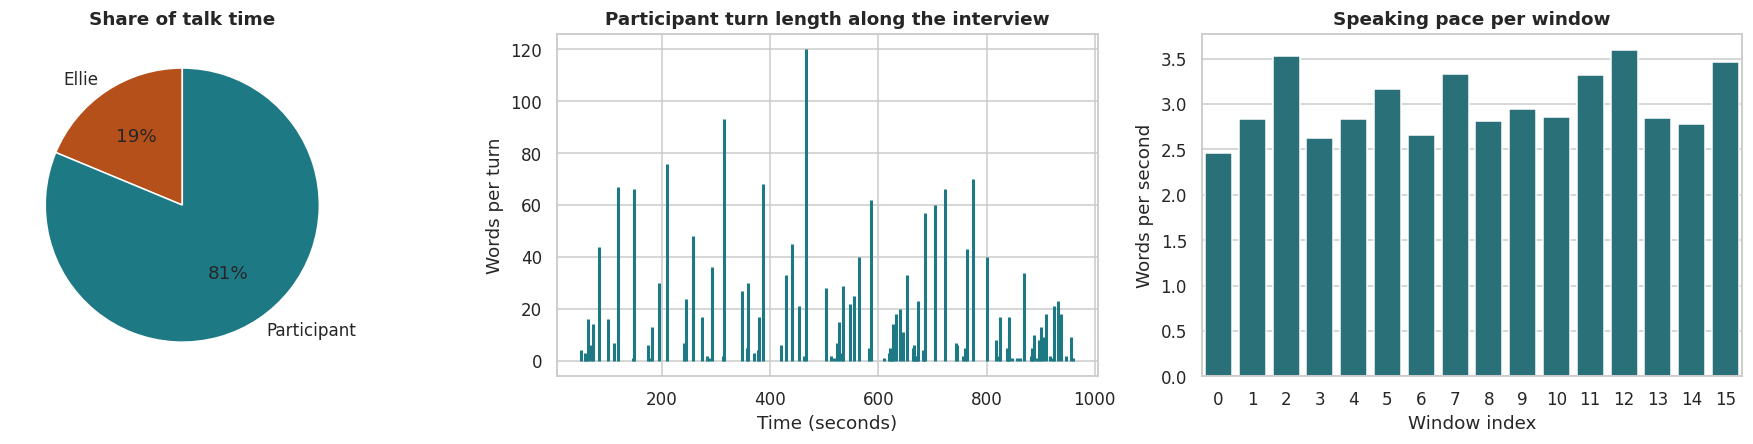

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: conversation shape (talk time, turn length, pace)
# ---------------------------------------------------------------
# Totals per speaker: how long each one talks and how many words they say.
talk_summary = (transcript.groupby("speaker")
                .agg(turns=("clean", "size"), words=("n_words", "sum"), seconds=("duration", "sum"))
                .round(1))
display(talk_summary)

# Per-window view: how much of each window the participant spends talking, and at what pace.
window_talk = (participant.groupby("window")
               .agg(participant_words=("n_words", "sum"),
                    speech_seconds=("duration", "sum"),
                    mean_turn_words=("n_words", "mean"))
               .assign(words_per_second=lambda d: d["participant_words"] / d["speech_seconds"].clip(lower=1e-6)))
WINDOW_TABLES["talk"] = window_talk[["words_per_second", "mean_turn_words", "speech_seconds"]]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

# Left: share of total talk time per speaker.
talk_summary["seconds"].plot.pie(ax=axes[0], autopct="%1.0f%%", startangle=90, ylabel="",
                                 colors=[COLORS["interviewer"], COLORS["participant"]])
axes[0].set_title("Share of talk time")

# Middle: how long each participant turn is, in words, along the interview.
axes[1].vlines(participant["start_time"], 0, participant["n_words"], color=COLORS["participant"], lw=2)
axes[1].set_title("Participant turn length along the interview")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Words per turn")

# Right: speaking pace per window, to spot fast or hesitant stretches.
sns.barplot(x=window_talk.index, y=window_talk["words_per_second"], color=COLORS["participant"], ax=axes[2])
axes[2].set_title("Speaking pace per window")
axes[2].set_xlabel("Window index")
axes[2].set_ylabel("Words per second")
save_fig("transcript_conversation_shape")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,value
roberta_weighted_mean,0.198
vader_weighted_mean,0.498
share_positive_turns,0.301
share_neutral_turns,0.573
share_negative_turns,0.126
agreement_between_models,0.597


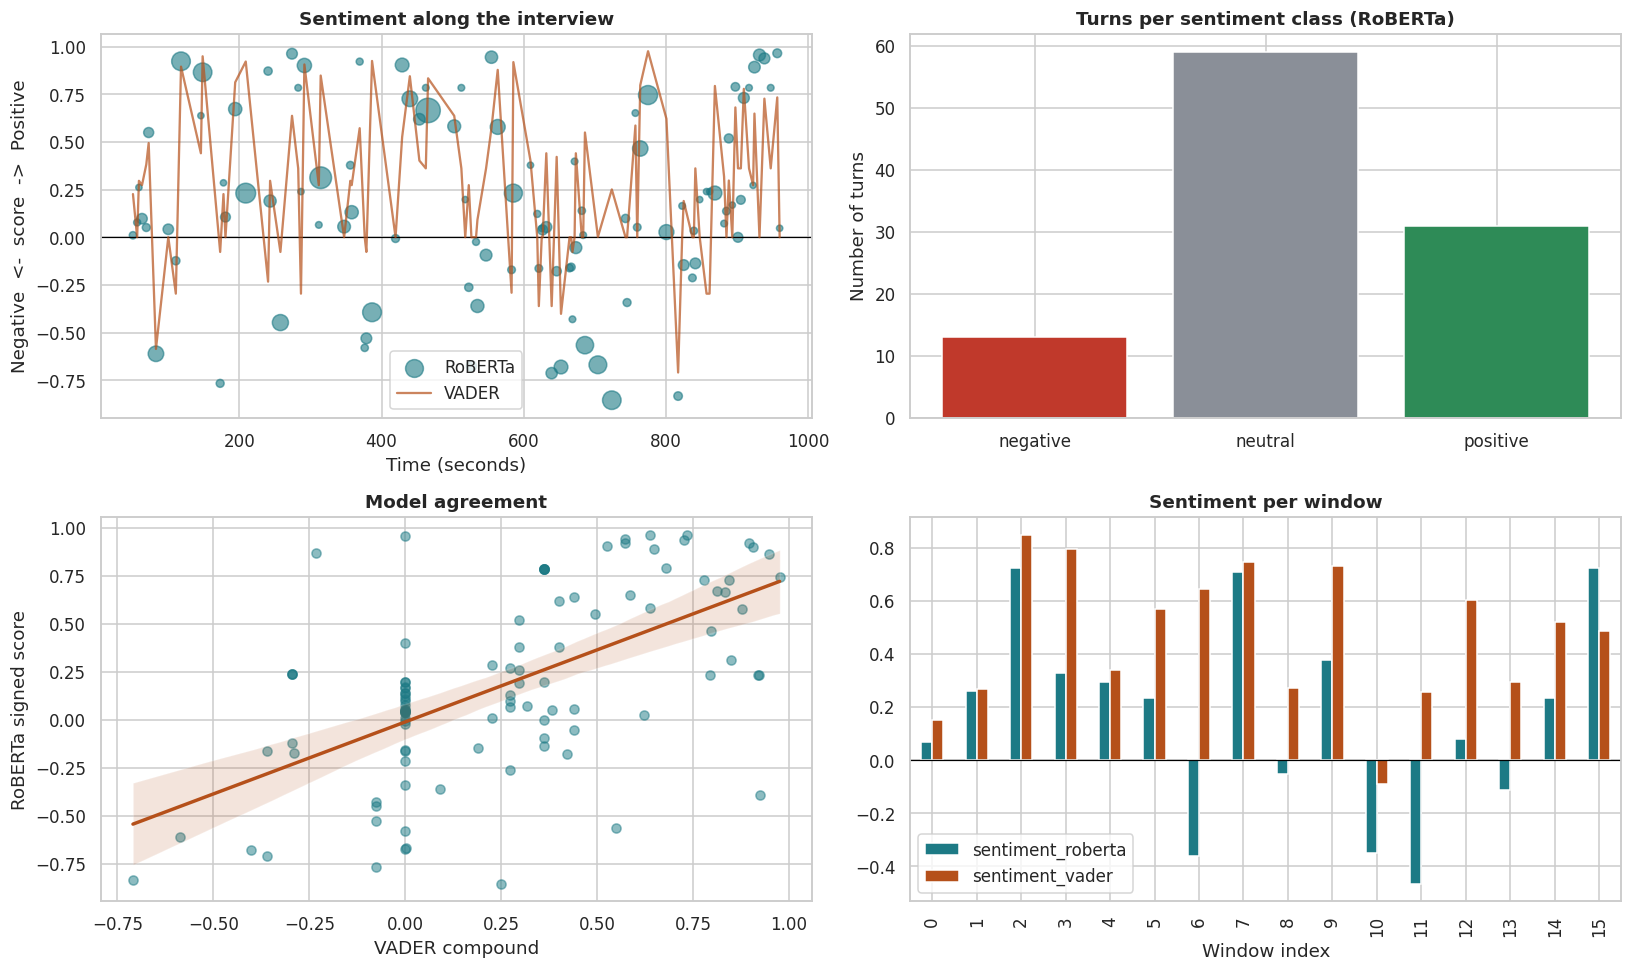

Most negative turns


,start_time,roberta_signed,clean
69,723.636,-0.854880,it's very frustrating because it's like i'm ta...
77,816.806,-0.833191,what am i like irritated tired um lazy
12,173.236,-0.766602,what do you mean i'm sorry


Most positive turns


,start_time,roberta_signed,clean
101,956.126,0.965007,you're more than welcome you have a good day
20,274.206,0.962521,my kids will keep me you know sane and you kno...
98,931.136,0.955630,especially when i go to pick them up from scho...


In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: sentiment (RoBERTa model + VADER baseline)
# ---------------------------------------------------------------
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

set_all_seeds()
device = 0 if torch.cuda.is_available() else -1

# Pretrained, ready-to-use sentiment model. No training needed, so it works on one session.
sent_pipe = pipeline("text-classification",
                     model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                     top_k=None, device=device)

# Score every participant turn; top_k=None returns the probability of every class, not just the winner.
raw = sent_pipe(participant["clean"].tolist(), truncation=True, max_length=512, batch_size=16)
probs = pd.DataFrame([{d["label"].lower(): d["score"] for d in row} for row in raw])

for cls in ["negative", "neutral", "positive"]:
    participant[f"rob_{cls}"] = probs[cls].values

# One signed number per turn: positive minus negative probability, from fully negative to fully positive.
participant["roberta_signed"] = participant["rob_positive"] - participant["rob_negative"]
participant["roberta_label"] = probs[["negative", "neutral", "positive"]].idxmax(axis=1).values

# Rule-based second opinion that needs no model download.
vader = SentimentIntensityAnalyzer()
participant["vader_compound"] = participant["clean"].apply(lambda s: vader.polarity_scores(s)["compound"])

# Overall reading, weighted by how many words each turn contains.
overall = {
    "roberta_weighted_mean": weighted_mean(participant["roberta_signed"], participant["n_words"]),
    "vader_weighted_mean": weighted_mean(participant["vader_compound"], participant["n_words"]),
    "share_positive_turns": (participant["roberta_label"] == "positive").mean(),
    "share_neutral_turns": (participant["roberta_label"] == "neutral").mean(),
    "share_negative_turns": (participant["roberta_label"] == "negative").mean(),
    "agreement_between_models": participant["roberta_signed"].corr(participant["vader_compound"]),
}
display(pd.Series(overall).round(3).to_frame("value"))

window_sent = participant.groupby("window").apply(
    lambda g: pd.Series({"sentiment_roberta": weighted_mean(g["roberta_signed"], g["n_words"]),
                         "sentiment_vader": weighted_mean(g["vader_compound"], g["n_words"])}))
WINDOW_TABLES["sentiment"] = window_sent

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Top left: sentiment along the interview; bubble size shows how long the turn is.
ax = axes[0, 0]
ax.axhline(0, color="black", lw=0.8)
ax.scatter(participant["start_time"], participant["roberta_signed"],
           s=participant["n_words"] * 2 + 15, alpha=0.6, color=COLORS["participant"], label="RoBERTa")
ax.plot(participant["start_time"], participant["vader_compound"], color=COLORS["interviewer"], alpha=0.7, label="VADER")
ax.set_title("Sentiment along the interview")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Negative  <-  score  ->  Positive")
ax.legend()

# Top right: how many turns fall into each class.
order = ["negative", "neutral", "positive"]
counts = participant["roberta_label"].value_counts().reindex(order).fillna(0)
axes[0, 1].bar(order, counts.values, color=[COLORS[o] for o in order])
axes[0, 1].set_title("Turns per sentiment class (RoBERTa)")
axes[0, 1].set_ylabel("Number of turns")

# Bottom left: do the two models agree, turn by turn?
sns.regplot(x=participant["vader_compound"], y=participant["roberta_signed"], ax=axes[1, 0],
            scatter_kws={"alpha": 0.5, "color": COLORS["participant"]}, line_kws={"color": COLORS["interviewer"]})
axes[1, 0].set_title("Model agreement")
axes[1, 0].set_xlabel("VADER compound")
axes[1, 0].set_ylabel("RoBERTa signed score")

# Bottom right: sentiment per time window, to see how the mood of the conversation drifts.
window_sent.plot.bar(ax=axes[1, 1], color=[COLORS["participant"], COLORS["interviewer"]])
axes[1, 1].axhline(0, color="black", lw=0.8)
axes[1, 1].set_title("Sentiment per window")
axes[1, 1].set_xlabel("Window index")
save_fig("transcript_sentiment")

# Show the most negative and most positive turns so the numbers can be sanity-checked in plain language.
cols = ["start_time", "roberta_signed", "clean"]
print("Most negative turns")
display(participant.nsmallest(3, "roberta_signed")[cols])
print("Most positive turns")
display(participant.nlargest(3, "roberta_signed")[cols])

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

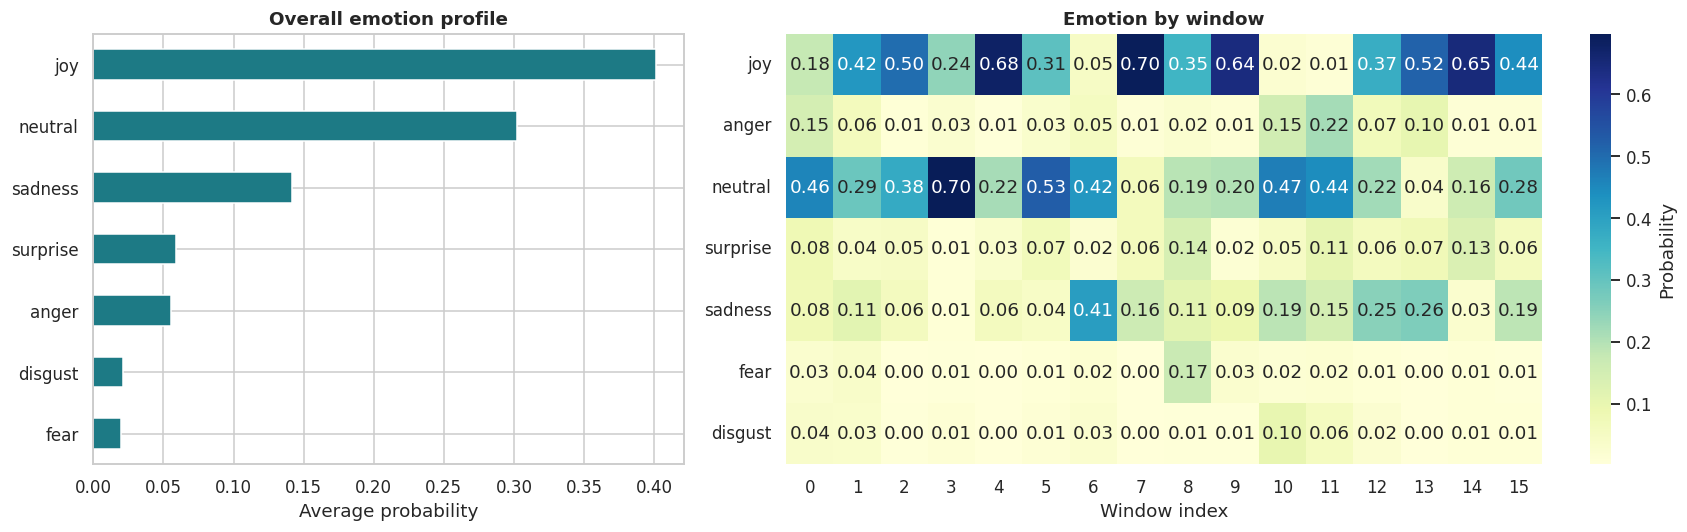

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: emotion classification (DistilRoBERTa emotion model)
# ---------------------------------------------------------------
set_all_seeds()

# Open emotion model with seven classes: anger, disgust, fear, joy, neutral, sadness, surprise.
emo_pipe = pipeline("text-classification",
                    model="j-hartmann/emotion-english-distilroberta-base",
                    top_k=None, device=device)

raw_emo = emo_pipe(participant["clean"].tolist(), truncation=True, max_length=512, batch_size=16)
emo = pd.DataFrame([{d["label"]: d["score"] for d in row} for row in raw_emo])
EMOTIONS = list(emo.columns)

# Keep the emotion probabilities next to the turn info we need for weighting and windows.
emo_turns = pd.concat([participant[["start_time", "window", "n_words"]], emo], axis=1)

# Overall emotion profile, weighted by turn length.
overall_emotion = emo.mul(participant["n_words"], axis=0).sum() / participant["n_words"].sum()

# Emotion profile per window.
window_emotion = emo_turns.groupby("window").apply(
    lambda g: pd.Series({e: weighted_mean(g[e], g["n_words"]) for e in EMOTIONS}))
WINDOW_TABLES["emotion"] = window_emotion.add_prefix("emo_")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: the average emotion mix of the whole interview.
overall_emotion.sort_values().plot.barh(ax=axes[0], color=COLORS["participant"])
axes[0].set_title("Overall emotion profile")
axes[0].set_xlabel("Average probability")

# Right: which emotions dominate in which part of the interview.
sns.heatmap(window_emotion.T, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "Probability"})
axes[1].set_title("Emotion by window")
axes[1].set_xlabel("Window index")
save_fig("transcript_emotion")

Overall language markers (share of all words)


,rate
first_person,0.0780
negation,0.0143
filler,0.0168
positive_words,0.0703
negative_words,0.0194


Median reply delay: 2.56 seconds


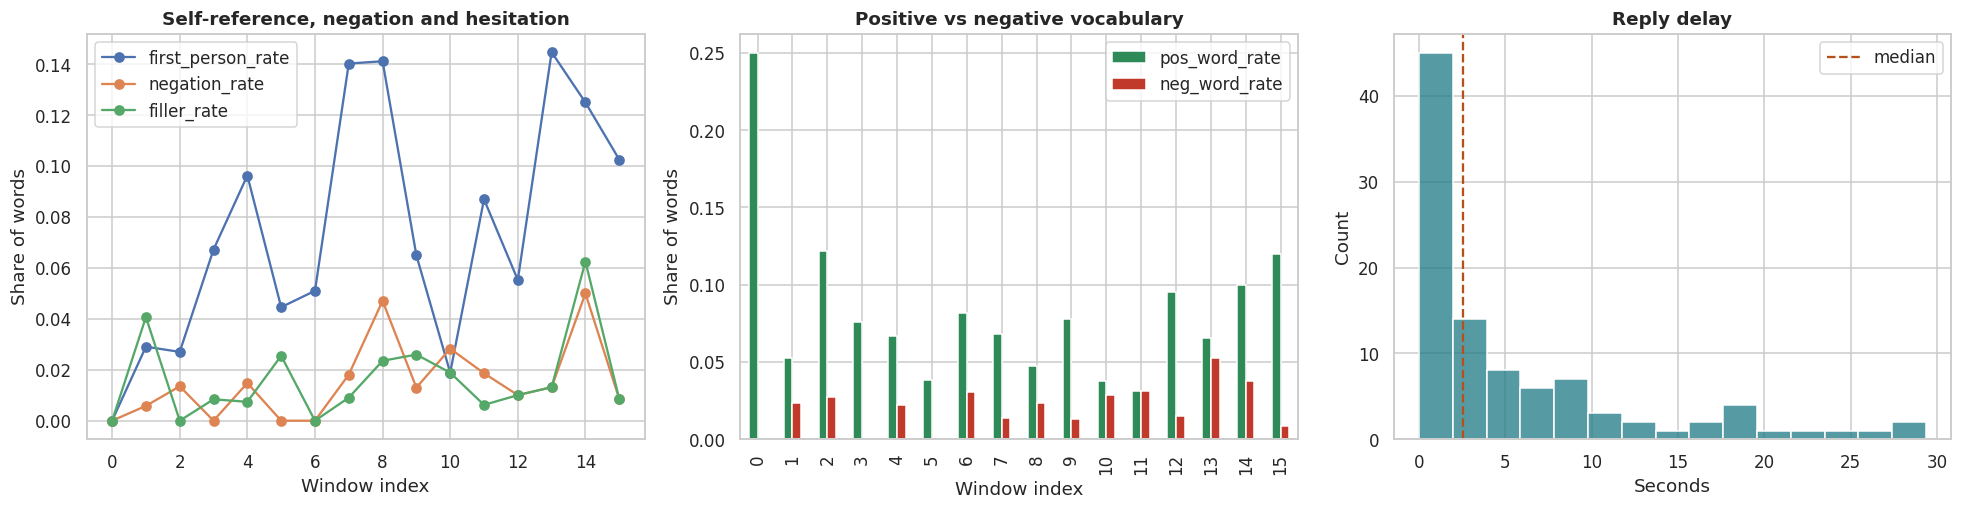

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: language-use markers and reply delay
# ---------------------------------------------------------------
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
lexicon = SentimentIntensityAnalyzer().lexicon  # word -> valence, used as a ready-made word list

FIRST_PERSON = {"i", "me", "my", "mine", "myself", "i'm", "i've", "i'll", "i'd"}
NEGATIONS = {"no", "not", "never", "nothing", "nobody", "none", "neither", "nor", "can't", "don't", "won't",
             "didn't", "isn't", "wasn't", "couldn't", "wouldn't", "shouldn't", "doesn't", "haven't", "hadn't", "hasn't"}
FILLERS = {"um", "uh", "hm", "hmm", "mm", "er"}
POSITIVE_WORDS = {w for w, v in lexicon.items() if v > 0}
NEGATIVE_WORDS = {w for w, v in lexicon.items() if v < 0}


def tokenize(text):
    """Lower-case words, keeping apostrophes so contractions stay intact."""
    return re.findall(r"[a-z']+", text.lower())


def language_counts(text):
    """Count each marker family inside one piece of text."""
    tokens = tokenize(text)
    return pd.Series({
        "tokens": len(tokens),
        "first_person": sum(t in FIRST_PERSON for t in tokens),
        "negation": sum(t in NEGATIONS for t in tokens),
        "filler": sum(t in FILLERS for t in tokens),
        "positive_words": sum(t in POSITIVE_WORDS for t in tokens),
        "negative_words": sum(t in NEGATIVE_WORDS for t in tokens),
        "unique_tokens": len(set(tokens)),
    })


lang_turns = pd.concat([participant[["start_time", "window"]], participant["clean"].apply(language_counts)], axis=1)

# Add up counts per window, then turn them into rates so windows of different length can be compared.
by_window = lang_turns.groupby("window").sum(numeric_only=True)
window_language = pd.DataFrame({
    "first_person_rate": by_window["first_person"] / by_window["tokens"],
    "negation_rate": by_window["negation"] / by_window["tokens"],
    "filler_rate": by_window["filler"] / by_window["tokens"],
    "pos_word_rate": by_window["positive_words"] / by_window["tokens"],
    "neg_word_rate": by_window["negative_words"] / by_window["tokens"],
    "lexical_variety": by_window["unique_tokens"] / by_window["tokens"],
})

# Reply delay: time between the end of the last interviewer turn and the start of each participant turn.
ellie_stops = np.sort(interviewer["stop_time"].values)
position = np.searchsorted(ellie_stops, participant["start_time"].values) - 1
delay = participant["start_time"].values - np.where(position >= 0, ellie_stops[np.clip(position, 0, None)], np.nan)
participant["reply_delay"] = delay
# Ignore absurd gaps that come from long monologues rather than from answering a question.
valid_delay = participant["reply_delay"].where(participant["reply_delay"].between(0, 30))
window_language["median_reply_delay"] = valid_delay.groupby(participant["window"]).median()
WINDOW_TABLES["language"] = window_language

print("Overall language markers (share of all words)")
overall_rates = lang_turns.drop(columns=["start_time", "window"]).sum()
display((overall_rates / overall_rates["tokens"]).drop(["tokens", "unique_tokens"]).round(4).to_frame("rate"))
print(f"Median reply delay: {valid_delay.median():.2f} seconds")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Left: self-reference, negation and hesitation over the interview.
window_language[["first_person_rate", "negation_rate", "filler_rate"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Self-reference, negation and hesitation")
axes[0].set_xlabel("Window index")
axes[0].set_ylabel("Share of words")

# Middle: positive against negative vocabulary.
window_language[["pos_word_rate", "neg_word_rate"]].plot.bar(ax=axes[1], color=[COLORS["positive"], COLORS["negative"]])
axes[1].set_title("Positive vs negative vocabulary")
axes[1].set_xlabel("Window index")
axes[1].set_ylabel("Share of words")

# Right: how long the participant waits before answering.
sns.histplot(valid_delay.dropna(), bins=15, color=COLORS["participant"], ax=axes[2])
axes[2].axvline(valid_delay.median(), color=COLORS["interviewer"], ls="--", label="median")
axes[2].set_title("Reply delay")
axes[2].set_xlabel("Seconds")
axes[2].legend()
save_fig("transcript_language")

topic 0: people, daughter, classes, look, actually, metro, different, basis
topic 1: kids, family, young, help, school, degree, support, situation
topic 2: school, hear, change, time, night, argument, happy, rest


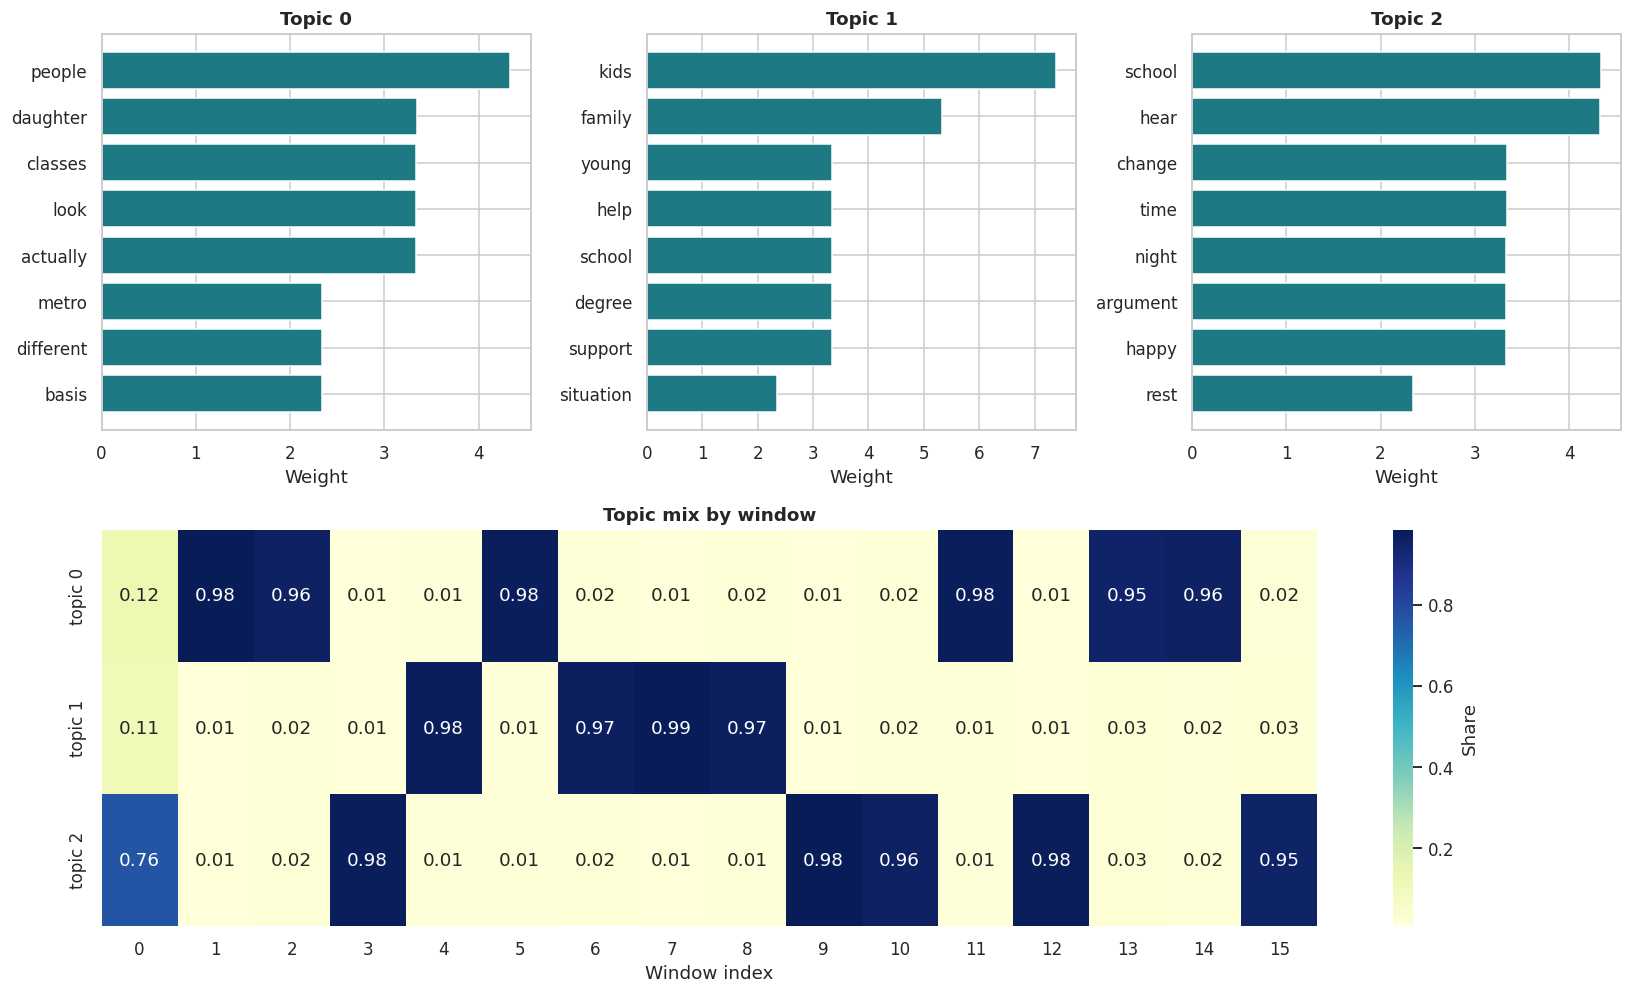

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: topics with LDA (classic, light, fully reproducible)
# ---------------------------------------------------------------
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation

# Number of topics is a knob: keep it small because one interview is short.
N_TOPICS = 3
N_TOP_WORDS = 8

# Spoken-language filler that carries no topic information, added on top of the standard stop words.
SPOKEN_FILLER = {"um", "uh", "like", "know", "gonna", "gotta", "just", "really", "pretty", "kinda",
                 "yeah", "okay", "thing", "things", "mean", "going", "think", "feel", "want", "way",
                 "nature", "good", "right", "need", "say", "cause", "thank", "lot", "probably", "wanna",
                 "told", "person", "better", "little", "doing", "make", "years", "year"}
stop_words = list(ENGLISH_STOP_WORDS.union(SPOKEN_FILLER))

# One document per window: all words the participant said in that window.
documents = participant.groupby("window")["clean"].apply(" ".join)

vectorizer = CountVectorizer(stop_words=stop_words, token_pattern=r"(?u)\b[a-z]{4,}\b", max_df=0.9)
counts = vectorizer.fit_transform(documents)

lda = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch", max_iter=100, random_state=SEED)
doc_topics = lda.fit_transform(counts)
vocab = np.array(vectorizer.get_feature_names_out())

topic_words = {f"topic {i}": vocab[np.argsort(comp)[::-1][:N_TOP_WORDS]].tolist() for i, comp in enumerate(lda.components_)}
for name, words in topic_words.items():
    print(f"{name}: {', '.join(words)}")

topic_mix = pd.DataFrame(doc_topics, index=documents.index, columns=list(topic_words))

# We use gridspec to place the topic bar charts in row 0 and the heatmap in row 1.
fig = plt.figure(figsize=(15, 9.2))
gs = fig.add_gridspec(2, N_TOPICS)

# One small bar chart per topic showing its strongest words in the first row.
axes = []
for i, comp in enumerate(lda.components_):
    ax = fig.add_subplot(gs[0, i])
    top = np.argsort(comp)[::-1][:N_TOP_WORDS]
    ax.barh(vocab[top][::-1], comp[top][::-1], color=COLORS["participant"])
    ax.set_title(f"Topic {i}")
    ax.set_xlabel("Weight")
    axes.append(ax)

# Last panel: which topic dominates which window, taking up the entire second row.
ax_heatmap = fig.add_subplot(gs[1, :])
sns.heatmap(topic_mix.T, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax_heatmap, cbar_kws={"label": "Share"})
ax_heatmap.set_title("Topic mix by window")
ax_heatmap.set_xlabel("Window index")

save_fig("transcript_topics")

Patient replies joined: 105 turns, 672 words in the corpus
Passages to score: 6

Whole-corpus sentiment summary
mean_negative                  0.212
mean_neutral                   0.375
mean_positive                  0.413
mean_signed_score              0.201
share_negative_passages        0.000
share_neutral_passages         0.500
share_positive_passages        0.500
most_negative_passage_score   -0.358
most_positive_passage_score    0.874
vader_whole_corpus             0.998
vader_mean_over_passages       0.755

Verdict: the patient's combined replies leans positive.


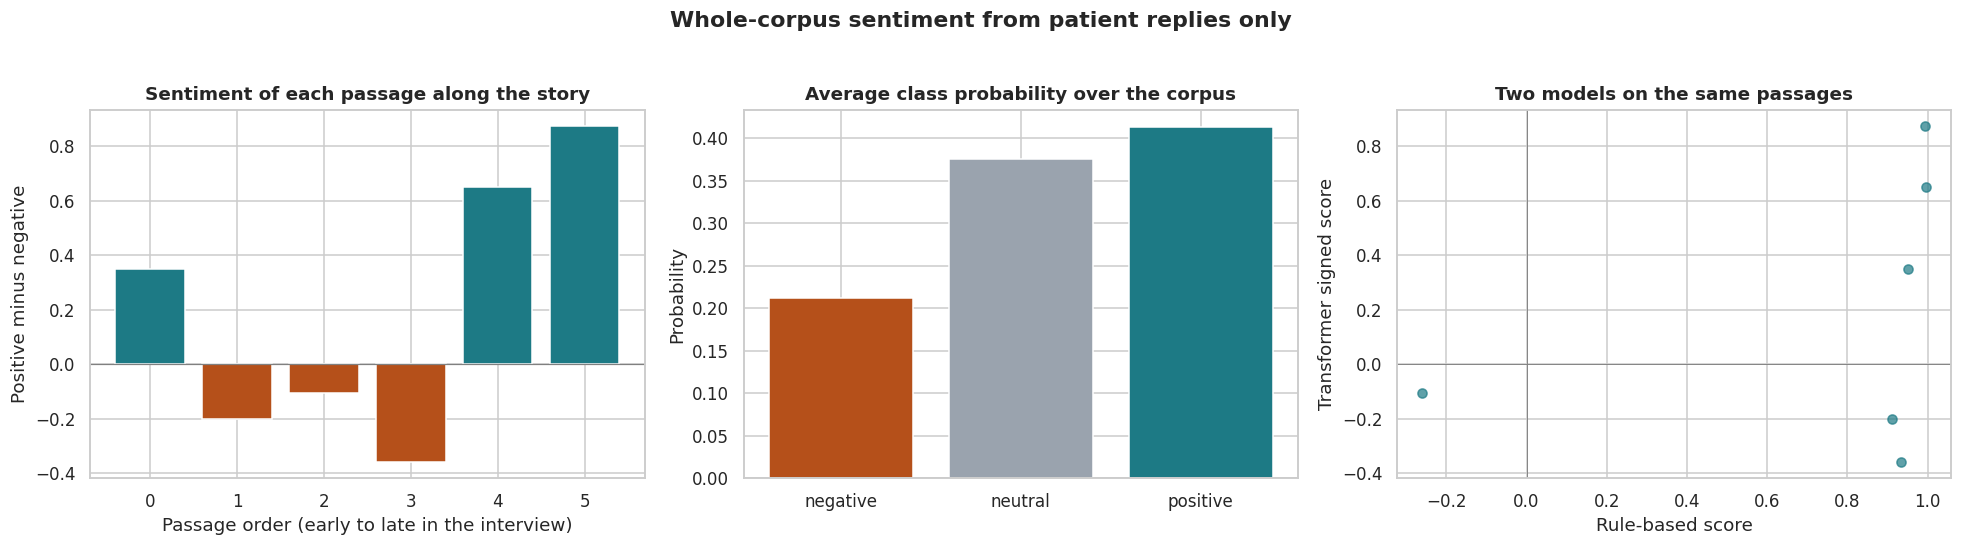


Most negative passages


,signed,text
3,-0.358235,or the health no no yes mm i'd say about a year um recognizing that there were some things in me that that were wrong i knew that there was something wrong 'cause i wasn't myself well you know i was always tired and not excited about things anymore and kinda lethargic you know laying around and just not feeling myself mm about the same yes i do once a month yeah i do i do well it's you know it...
1,-0.201938,wanna budge on this gun control issue thing that's it mm um i try to remove myself from that situation that's annoying me i've gotten better over the years um most of the time i just try to um you know walk away or you know control my emotions in terms of you know just walking away mm just watch t_v now hmm i would say my children being born well i have four children um each birth was speical ...



Most positive passages


,signed,text
5,0.873520,of stuff going on so i'll leave it at that hmm well i still like sports you know and um watching a good game or something is usually puts me in a good mood particularly if my team wins you know i like u_s_c um i have a nephew that's um freshman football player at u_s_c and uh i've been a trojan football fan for forty years so yeah hmm well i you know i think i i listen well and um you know i'm...
4,0.651908,detail but you know it's it i seem to think that it's helpful well i i think um that's a hard question let's move on please irritable cranky yeah it is ooh that's a good question it's been awhile i'd say year and a half maybe hmm well there's been a lot going on in my life you know i just lost my parent my dad my last parent just a lot of stuff going on so i'll leave it at that hmm well i stil...


In [ ]:
# =============================================================================
# TRANSCRIPT: WHOLE-CORPUS SENTIMENT (patient replies only)
# =============================================================================
# Idea: join every participant reply into one long corpus, cut it into
# overlapping passages, and score each passage. A passage holds many sentences,
# so the model sees context and not just a single short line.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Reuse the seed helper from the setup cell if it exists.
if "set_all_seeds" in globals():
    set_all_seeds()

# ---- Settings you can tune --------------------------------------------------
PASSAGE_WORDS = 200      # how many words go into one passage
PASSAGE_STEP = 100       # how far the window slides; smaller step means more overlap

# ---- Step one: build the corpus from patient replies only -------------------
# Turns are kept in time order, so the corpus reads like the patient's own story.
patient_turns = participant.sort_values("start_time")["clean"].astype(str).tolist()
corpus_words = " ".join(patient_turns).split()
print(f"Patient replies joined: {len(patient_turns)} turns, {len(corpus_words)} words in the corpus")

# ---- Step two: cut the corpus into overlapping passages ---------------------
passages = []
for begin in range(0, max(len(corpus_words) - PASSAGE_WORDS, 0) + 1, PASSAGE_STEP):
    chunk = corpus_words[begin: begin + PASSAGE_WORDS]
    passages.append({"first_word": begin, "text": " ".join(chunk), "n_words": len(chunk)})
passages = pd.DataFrame(passages)

# The tail of the corpus can be left out by the sliding step, so add it explicitly.
if len(corpus_words) > PASSAGE_WORDS and passages["first_word"].iloc[-1] + PASSAGE_WORDS < len(corpus_words):
    tail_start = len(corpus_words) - PASSAGE_WORDS
    passages.loc[len(passages)] = [tail_start, " ".join(corpus_words[tail_start:]), PASSAGE_WORDS]
print(f"Passages to score: {len(passages)}")

# ---- Step three: load the sentiment model (reuse it if already loaded) ------
if "sent_pipe" not in globals():
    sent_pipe = pipeline("text-classification",
                         model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                         top_k=None)
if "vader" not in globals():
    import nltk
    nltk.download("vader_lexicon", quiet=True)
    vader = SentimentIntensityAnalyzer()

# ---- Step four: score every passage -----------------------------------------
# Each passage gets a probability for negative, neutral and positive.
raw = sent_pipe(passages["text"].tolist(), truncation=True, max_length=512, batch_size=8)
probs = pd.DataFrame([{d["label"].lower(): d["score"] for d in row} for row in raw])
passages = pd.concat([passages, probs], axis=1)

# A single signed number per passage: positive minus negative probability.
passages["signed"] = passages["positive"] - passages["negative"]
passages["label"] = passages[["negative", "neutral", "positive"]].idxmax(axis=1)

# Rule-based second opinion on the same passages.
passages["vader"] = passages["text"].apply(lambda s: vader.polarity_scores(s)["compound"])

# ---- Step five: one verdict for the whole corpus ----------------------------
# Passages are weighted by their word count so the short tail does not count extra.
weights = passages["n_words"]
overall = {
    "mean_negative": np.average(passages["negative"], weights=weights),
    "mean_neutral": np.average(passages["neutral"], weights=weights),
    "mean_positive": np.average(passages["positive"], weights=weights),
    "mean_signed_score": np.average(passages["signed"], weights=weights),
    "share_negative_passages": (passages["label"] == "negative").mean(),
    "share_neutral_passages": (passages["label"] == "neutral").mean(),
    "share_positive_passages": (passages["label"] == "positive").mean(),
    "most_negative_passage_score": passages["signed"].min(),
    "most_positive_passage_score": passages["signed"].max(),
    "vader_whole_corpus": vader.polarity_scores(" ".join(corpus_words))["compound"],
    "vader_mean_over_passages": np.average(passages["vader"], weights=weights),
}
overall = pd.Series(overall)

# Plain-language reading of the signed score.
score = overall["mean_signed_score"]
if score <= -0.15:
    verdict = "leans negative"
elif score >= 0.15:
    verdict = "leans positive"
else:
    verdict = "sits close to neutral"
print("\nWhole-corpus sentiment summary")
print(overall.round(3).to_string())
print(f"\nVerdict: the patient's combined replies {verdict}.")

# ---- Step six: visuals -------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Left: how sentiment moves through the story, passage by passage.
bar_colors = np.where(passages["signed"] >= 0, "#1D7A85", "#B5501A")
axes[0].bar(passages.index, passages["signed"], color=bar_colors)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_title("Sentiment of each passage along the story")
axes[0].set_xlabel("Passage order (early to late in the interview)")
axes[0].set_ylabel("Positive minus negative")

# Middle: average probability mass for each class across the corpus.
class_means = overall[["mean_negative", "mean_neutral", "mean_positive"]]
class_means.index = ["negative", "neutral", "positive"]
axes[1].bar(class_means.index, class_means.values, color=["#B5501A", "#9AA3AE", "#1D7A85"])
axes[1].set_title("Average class probability over the corpus")
axes[1].set_ylabel("Probability")

# Right: do the transformer model and the rule-based model agree per passage?
axes[2].scatter(passages["vader"], passages["signed"], color="#1D7A85", alpha=0.7)
axes[2].axhline(0, color="grey", lw=0.6)
axes[2].axvline(0, color="grey", lw=0.6)
axes[2].set_title("Two models on the same passages")
axes[2].set_xlabel("Rule-based score")
axes[2].set_ylabel("Transformer signed score")

fig.suptitle("Whole-corpus sentiment from patient replies only", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# ---- Step seven: read the extremes yourself ---------------------------------
# Numbers can mislead, so always look at the passages that drive the result.
pd.set_option("display.max_colwidth", 400)
print("\nMost negative passages")
display(passages.nsmallest(2, "signed")[["signed", "text"]])
print("\nMost positive passages")
display(passages.nlargest(2, "signed")[["signed", "text"]])

# Keep the passage table so later cells (for example fusion) can reuse it.
corpus_sentiment = passages.copy()

##Face: expression states from action units

Frames dropped because tracking failed: 1.7%
Silhouette by number of states: {3: np.float64(0.146), 4: np.float64(0.146), 5: np.float64(0.15), 6: np.float64(0.14)} -> using 5
Mean time in a state before switching: 2.5 s | switches per minute: 24.2
HMM switches per minute: 16.5 | frame-level agreement with KMeans (adjusted Rand): 0.17


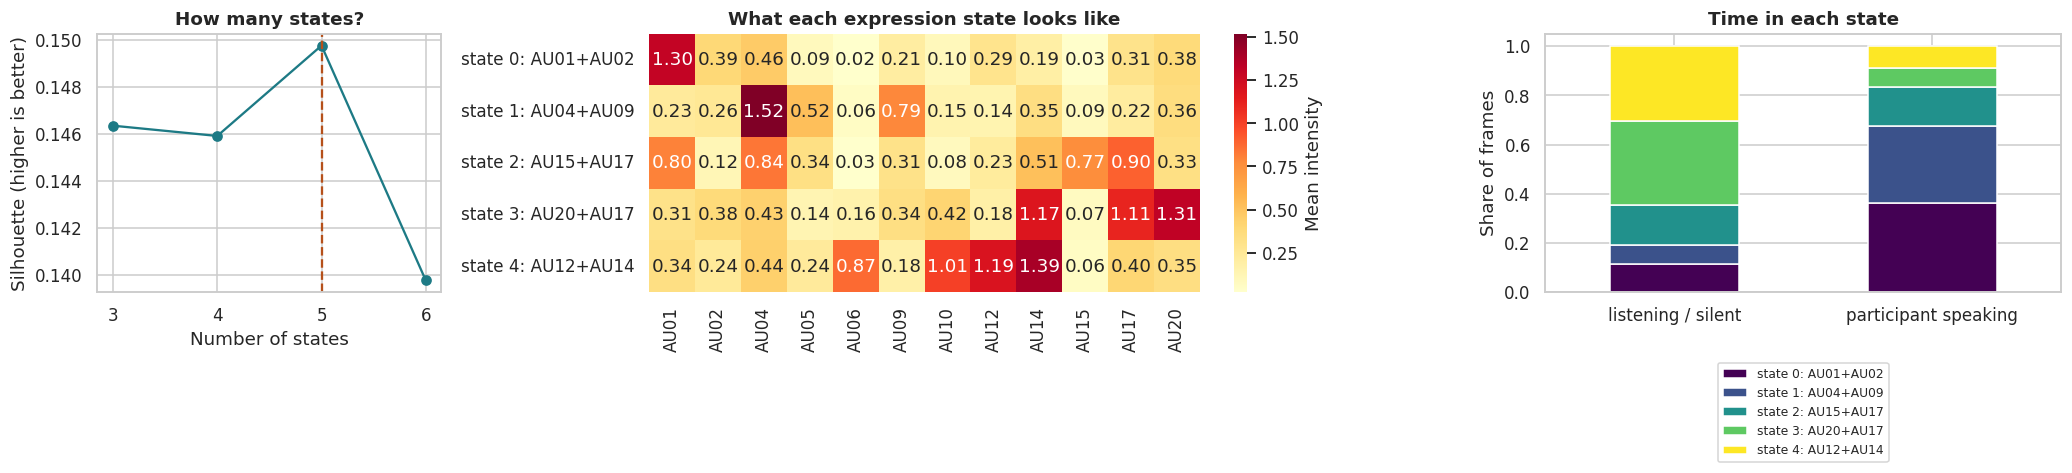

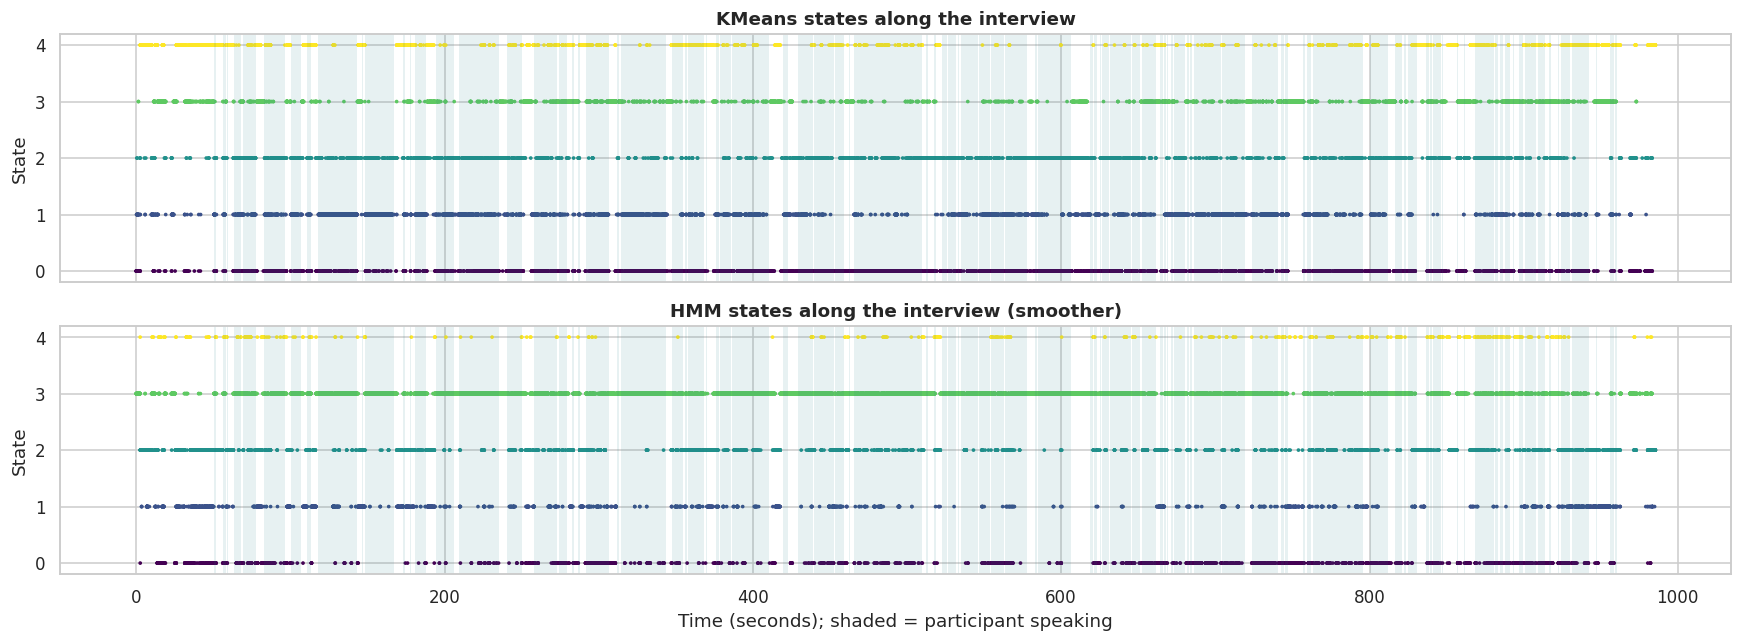

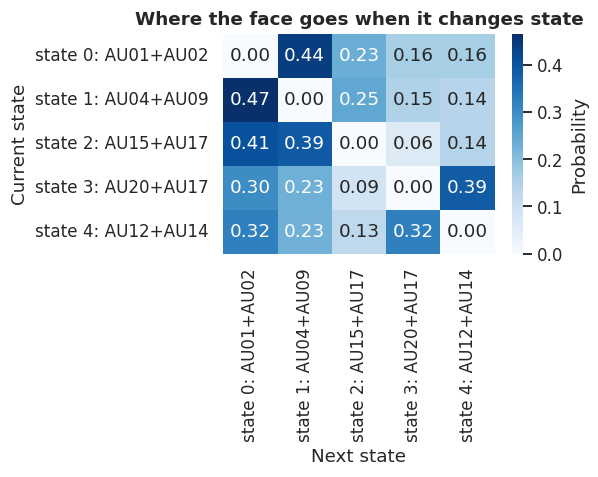

In [ ]:
# ---------------------------------------------------------------
# FACE: expression states from action units (KMeans + HMM)
# ---------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from hmmlearn.hmm import GaussianHMM

set_all_seeds()

au = pd.read_csv(PATHS["aus"], skipinitialspace=True)
intensity_cols = [c for c in au.columns if c.endswith("_r")]

# Mouth-opening units mostly track speech, so they are excluded from the expression analysis.
speech_driven = ["AU25_r", "AU26_r"]
expr_cols = [c for c in intensity_cols if c not in speech_driven]

# Keep only frames where the face tracker succeeded; failed frames carry placeholder values.
print(f"Frames dropped because tracking failed: {(au['success'] != 1).mean():.1%}")
tracked = au[au["success"] == 1].reset_index(drop=True)
tracked["speaking"] = speech_mask(tracked["timestamp"], participant)

# Put all action units on the same scale so no single one dominates the clustering.
X = StandardScaler().fit_transform(tracked[expr_cols])

# Let the data suggest how many states there are, using silhouette on a fixed random subsample for speed.
K_RANGE = range(3, 7)   # start above the minimum so there are always several states to compare
silhouette = {}
for k in K_RANGE:
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    silhouette[k] = silhouette_score(X, labels_k, sample_size=5000, random_state=SEED)
best_k = max(silhouette, key=silhouette.get)
print("Silhouette by number of states:", {k: round(v, 3) for k, v in silhouette.items()}, "-> using", best_k)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(X)

# Relabel the states so state zero is the calmest face and higher numbers are more active.
total_activity = tracked[expr_cols].groupby(kmeans.labels_).mean().sum(axis=1)
remap = {old: new for new, old in enumerate(total_activity.sort_values().index)}
tracked["state"] = pd.Series(kmeans.labels_).map(remap).values

# What each state looks like in the original units, and a short readable name made from its standout units.
profile = tracked.groupby("state")[expr_cols].mean()
standout = (profile - tracked[expr_cols].mean())
state_names = {s: f"state {s}: " + "+".join(standout.loc[s].nlargest(2).index.str.replace("_r", "")) for s in profile.index}

# How much time the face spends in each state, split by whether the participant is speaking.
share = pd.crosstab(tracked["speaking"].map({True: "participant speaking", False: "listening / silent"}),
                    tracked["state"].map(state_names), normalize="index")

# Frame-by-frame labels flicker with tracker noise, so switching is measured on the dominant state of each second.
tracked["second"] = tracked["timestamp"].astype(int)
dominant_state = tracked.groupby("second")["state"].agg(lambda s: s.mode().iloc[0])


def switch_stats(sequence):
    """Mean seconds spent in a state before switching, and number of switches per minute."""
    run_ids = (sequence != sequence.shift()).cumsum()
    return run_ids.groupby(run_ids).size().mean(), (run_ids.nunique() - 1) / (len(sequence) / 60)


mean_dwell, switches_per_minute = switch_stats(dominant_state)
print(f"Mean time in a state before switching: {mean_dwell:.1f} s | switches per minute: {switches_per_minute:.1f}")

# Transition matrix without self-loops, so it shows where the face goes when it does change.
prev_state, next_state = dominant_state.values[:-1], dominant_state.values[1:]
all_states = sorted(dominant_state.unique())
moves = pd.crosstab(prev_state, next_state).reindex(index=all_states, columns=all_states, fill_value=0).astype(float)
moves_array = moves.to_numpy(copy=True)
np.fill_diagonal(moves_array, 0)
moves = pd.DataFrame(moves_array, index=moves.index, columns=moves.columns)
transition = moves.div(moves.sum(axis=1).replace(0, np.nan), axis=0)

# A temporal model as a cross-check: an HMM smooths out frame-to-frame jitter.
hmm = GaussianHMM(n_components=best_k, covariance_type="diag", n_iter=100, random_state=SEED).fit(X)
tracked["hmm_state"] = hmm.predict(X)
hmm_dominant = tracked.groupby("second")["hmm_state"].agg(lambda s: s.mode().iloc[0])
_, hmm_switches = switch_stats(hmm_dominant)
print(f"HMM switches per minute: {hmm_switches:.1f} | frame-level agreement with KMeans (adjusted Rand): {adjusted_rand_score(tracked['state'], tracked['hmm_state']):.2f}")

# Per-window summary for the fusion step, using only frames where the participant is talking.
speaking_frames = tracked[tracked["speaking"]].copy()
speaking_frames["activity"] = speaking_frames[expr_cols].sum(axis=1)
speaking_frames["window"] = to_window(speaking_frames["timestamp"])
window_face = speaking_frames.groupby("window").agg(
    face_activity=("activity", "mean"),
    face_variability=("activity", "std"),
    smile_units=("AU12_r", "mean"),
    cheek_raise=("AU06_r", "mean"),
    brow_lowerer=("AU04_r", "mean"),
    calm_state_share=("state", lambda s: (s == 0).mean()),
)
WINDOW_TABLES["face"] = window_face

# ----- figures -----
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [0.8, 1.6, 1.2]})
axes[0].plot(list(silhouette), list(silhouette.values()), marker="o", color=COLORS["participant"])
axes[0].axvline(best_k, color=COLORS["interviewer"], ls="--")
axes[0].set_title("How many states?")
axes[0].set_xlabel("Number of states")
axes[0].set_ylabel("Silhouette (higher is better)")

sns.heatmap(profile.rename(index=state_names).rename(columns=lambda c: c.replace("_r", "")),
            annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Mean intensity"})
axes[1].set_title("What each expression state looks like")
axes[1].set_ylabel("")

share.plot.bar(stacked=True, ax=axes[2], colormap="viridis")
axes[2].set_title("Time in each state")
axes[2].set_xlabel("")
axes[2].set_ylabel("Share of frames")
axes[2].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25))
axes[2].tick_params(axis="x", rotation=0)
save_fig("face_states_overview")

fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for ax, col, title in [(axes[0], "state", "KMeans states along the interview"),
                       (axes[1], "hmm_state", "HMM states along the interview (smoother)")]:
    ax.scatter(tracked["timestamp"], tracked[col], c=tracked[col], cmap="viridis", s=2)
    shade_turns(ax, participant, COLORS["participant"], alpha=0.10)
    ax.set_title(title)
    ax.set_ylabel("State")
axes[1].set_xlabel("Time (seconds); shaded = participant speaking")
save_fig("face_state_timeline")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(transition.rename(index=state_names, columns=state_names), annot=True, fmt=".2f", cmap="Blues", ax=ax,
            cbar_kws={"label": "Probability"})
ax.set_title("Where the face goes when it changes state")
ax.set_xlabel("Next state")
ax.set_ylabel("Current state")
save_fig("face_state_transitions")

##Voice: pitch, voice quality and formants

Voiced share while participant speaks: 65.8%
Overall voice profile (participant, voiced frames)


,F0,NAQ,QOQ,H1H2,peakSlope,Rd,F1,F2,F3
mean,192.97,0.12,0.44,6.20,-0.36,1.51,570.68,1671.18,2670.00
std,36.17,0.05,0.15,6.13,0.07,0.42,203.30,452.58,499.91
min,93.00,0.00,0.00,-32.87,-0.52,0.30,0.00,51.56,609.00
max,386.00,0.29,0.91,35.06,-0.01,2.50,2327.00,3697.80,4191.80


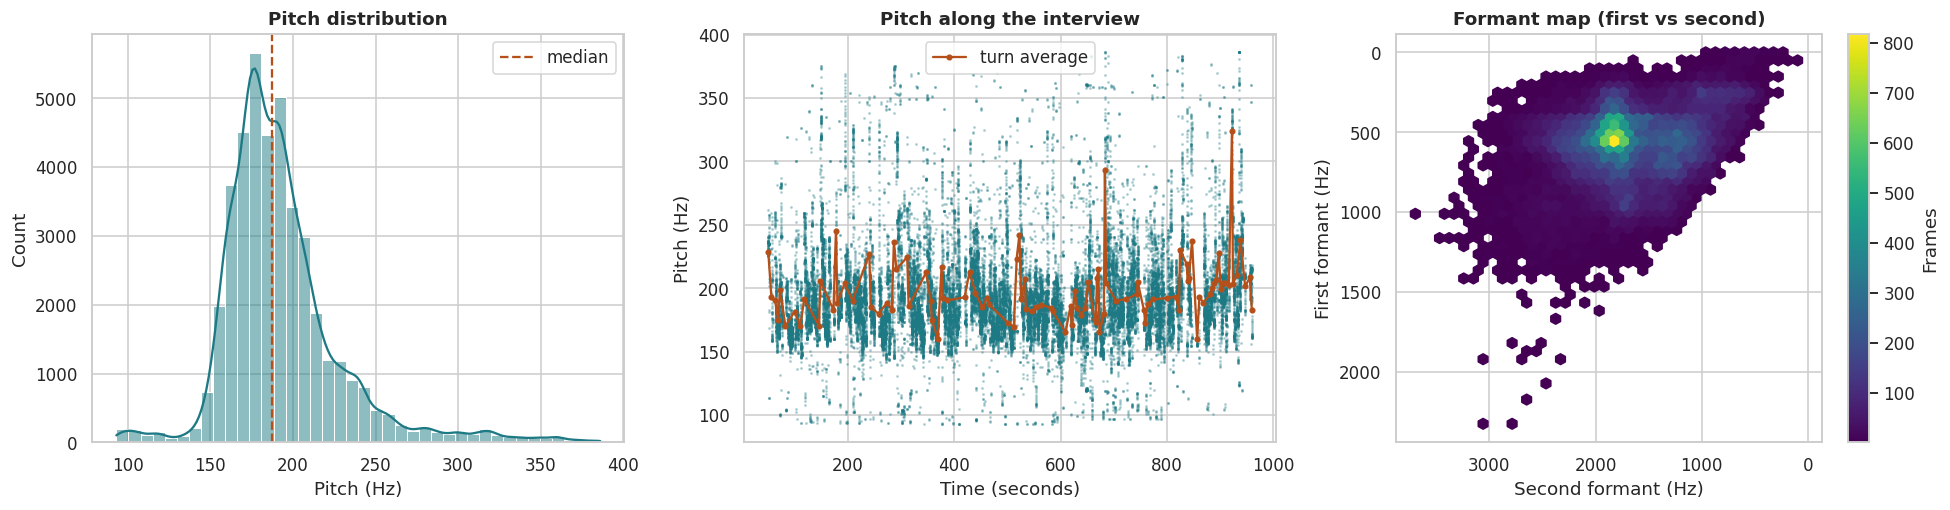

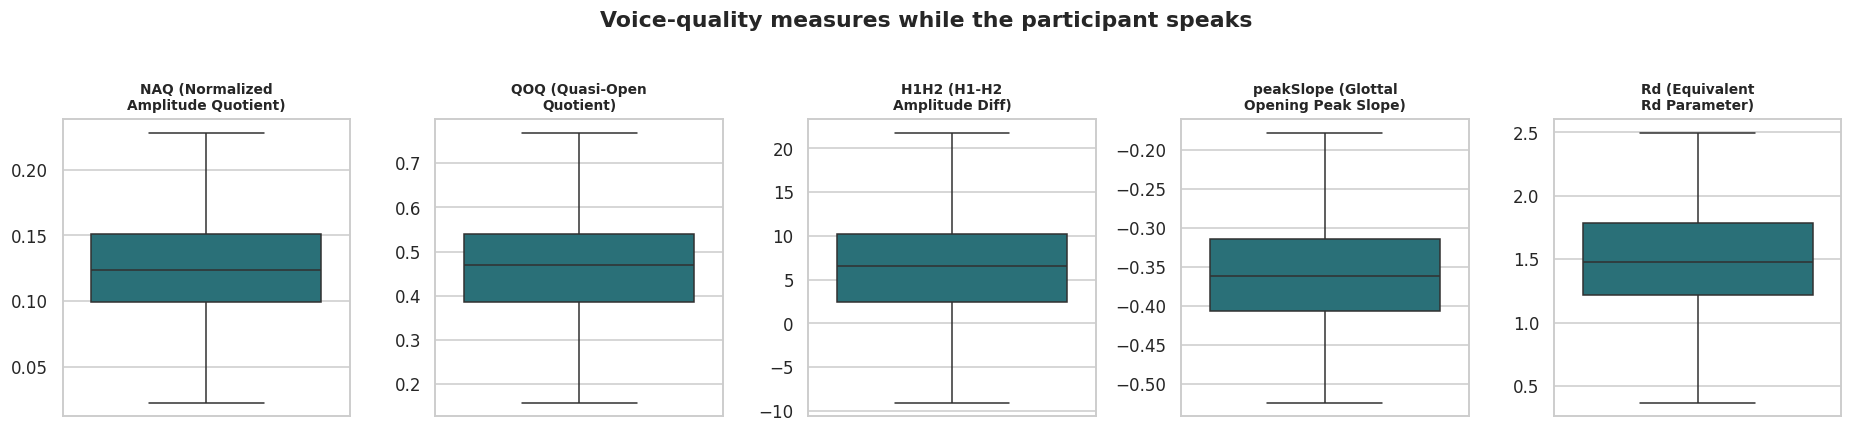

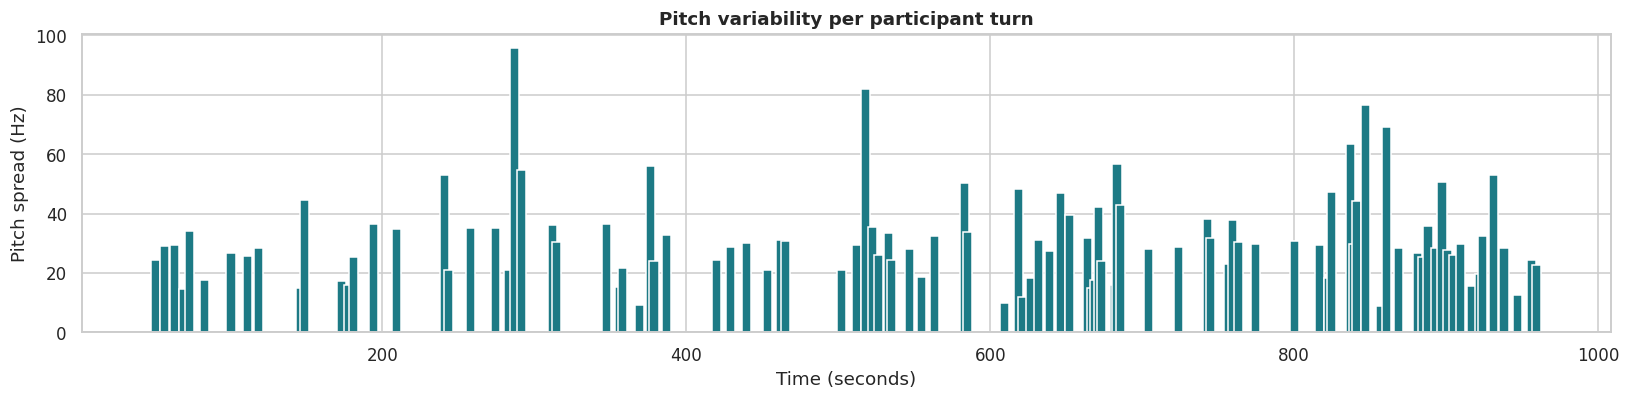

In [ ]:
# ---------------------------------------------------------------
# VOICE: pitch, voice quality and formants (participant speech only)
# ---------------------------------------------------------------
# The file has no header, so we name the columns in the documented order. The documentation lists fewer
# names than the file has columns; the extra one is assumed to be a creak indicator next to the confidence column.
cov_names = (["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf", "creak"]
             + [f"MCEP_{i}" for i in range(25)]
             + [f"HMPDM_{i}" for i in range(25)]
             + [f"HMPDD_{i}" for i in range(13)])

cov = pd.read_csv(PATHS["covarep"], header=None)
if cov.shape[1] == len(cov_names):
    cov.columns = cov_names
else:
    print("Column count differs from the expected layout; check the naming before trusting later cells.")
    cov.columns = cov_names[:cov.shape[1]] + [f"extra_{i}" for i in range(cov.shape[1] - len(cov_names))]

formant = pd.read_csv(PATHS["formant"], header=None, names=["F1", "F2", "F3", "F4", "F5"])

# Both files tick at the same fixed rate; trim to the shorter one so rows line up one-to-one.
n_rows = min(len(cov), len(formant))
voice = pd.concat([cov.iloc[:n_rows][["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd"]].reset_index(drop=True),
                   formant.iloc[:n_rows][["F1", "F2", "F3"]].reset_index(drop=True)], axis=1)
voice = voice.replace([np.inf, -np.inf], np.nan)

FRAME_STEP = 0.01  # seconds between audio-feature rows
voice["time"] = np.arange(n_rows) * FRAME_STEP
voice["speaking"] = speech_mask(voice["time"], participant)

# Voiced means the vocal folds are vibrating; only then are pitch and voice-quality values valid.
voice["voiced"] = (voice["VUV"] == 1) & (voice["F0" ]> 0)
speech_voiced = voice[voice["speaking"] & voice["voiced"]].copy()
print(f"Voiced share while participant speaks: {voice.loc[voice['speaking'], 'voiced'].mean():.1%}")

# One summary row per participant turn, so changes in delivery can be tied to what was being said.
rows = []
for _, turn in participant.iterrows():
    seg = voice.iloc[int(turn["start_time"] / FRAME_STEP): int(turn["stop_time"] / FRAME_STEP)]
    seg_voiced = seg[seg["voiced"]]
    if len(seg_voiced) < 20:
        continue
    rows.append({"start_time": turn["start_time"], "window": turn["window"], "n_words": turn["n_words"],
                 "pitch_mean": seg_voiced["F0"].mean(), "pitch_std": seg_voiced["F0"].std(),
                 "pitch_range": seg_voiced["F0"].quantile(0.95) - seg_voiced["F0"].quantile(0.05),
                 "voiced_ratio": len(seg_voiced) / max(len(seg), 1),
                 "NAQ": seg_voiced["NAQ"].mean(), "QOQ": seg_voiced["QOQ"].mean(),
                 "H1H2": seg_voiced["H1H2"].mean(), "peakSlope": seg_voiced["peakSlope"].mean()})
voice_turns = pd.DataFrame(rows)

window_voice = voice_turns.groupby("window").apply(lambda g: pd.Series({
    "pitch_mean": weighted_mean(g["pitch_mean"], g["n_words"]),
    "pitch_std": weighted_mean(g["pitch_std"], g["n_words"]),
    "voiced_ratio": weighted_mean(g["voiced_ratio"], g["n_words"]),
    "breathiness_naq": weighted_mean(g["NAQ"], g["n_words"])}))
WINDOW_TABLES["voice"] = window_voice

print("Overall voice profile (participant, voiced frames)")
display(speech_voiced[["F0", "NAQ", "QOQ", "H1H2", "peakSlope", "Rd", "F1", "F2", "F3"]].describe().loc[["mean", "std", "min", "max"]].round(2))

# ----- figures -----
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Pitch distribution: spread shows how much the pitch moves; a narrow hump suggests flat delivery.
sns.histplot(speech_voiced["F0"], bins=40, kde=True, color=COLORS["participant"], ax=axes[0])
axes[0].axvline(speech_voiced["F0"].median(), color=COLORS["interviewer"], ls="--", label="median")
axes[0].set_title("Pitch distribution")
axes[0].set_xlabel("Pitch (Hz)")
axes[0].legend()

# Pitch contour along the interview, with each turn's average on top.
axes[1].scatter(speech_voiced["time"], speech_voiced["F0"], s=1, alpha=0.25, color=COLORS["participant"])
axes[1].plot(voice_turns["start_time"], voice_turns["pitch_mean"], color=COLORS["interviewer"], marker="o", ms=3, label="turn average")
axes[1].set_title("Pitch along the interview")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Pitch (Hz)")
axes[1].legend()

# Vowel-style map from the first two formants: tells which speech sounds the participant produces.
hb = axes[2].hexbin(speech_voiced["F2"], speech_voiced["F1"], gridsize=40, cmap="viridis", mincnt=1)
axes[2].invert_xaxis()
axes[2].invert_yaxis()
axes[2].set_title("Formant map (first vs second)")
axes[2].set_xlabel("Second formant (Hz)")
axes[2].set_ylabel("First formant (Hz)")
plt.colorbar(hb, ax=axes[2], label="Frames")
save_fig("voice_pitch_and_formants")

# Voice-quality measures mapped to their full academic/lexical definition terms.
quality_cols = ["NAQ", "QOQ", "H1H2", "peakSlope", "Rd"]
quality_definitions = {
    "NAQ": "NAQ (Normalized\nAmplitude Quotient)",
    "QOQ": "QOQ (Quasi-Open\nQuotient)",
    "H1H2": "H1H2 (H1-H2\nAmplitude Diff)",
    "peakSlope": "peakSlope (Glottal\nOpening Peak Slope)",
    "Rd": "Rd (Equivalent\nRd Parameter)"
}

fig, axes = plt.subplots(1, len(quality_cols), figsize=(17, 3.8))
for ax, col in zip(axes, quality_cols):
    sns.boxplot(y=speech_voiced[col], ax=ax, color=COLORS["participant"], showfliers=False)
    ax.set_title(quality_definitions[col], fontsize=9)
    ax.set_ylabel("")
fig.suptitle("Voice-quality measures while the participant speaks", fontweight="bold", y=1.03)
save_fig("voice_quality_measures")

# Pitch variability for every turn: tall bars are expressive turns, short bars are flat ones.
fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(voice_turns["start_time"], voice_turns["pitch_std"], width=6, color=COLORS["participant"])
ax.set_title("Pitch variability per participant turn")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Pitch spread (Hz)")
save_fig("voice_pitch_variability")

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.15k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

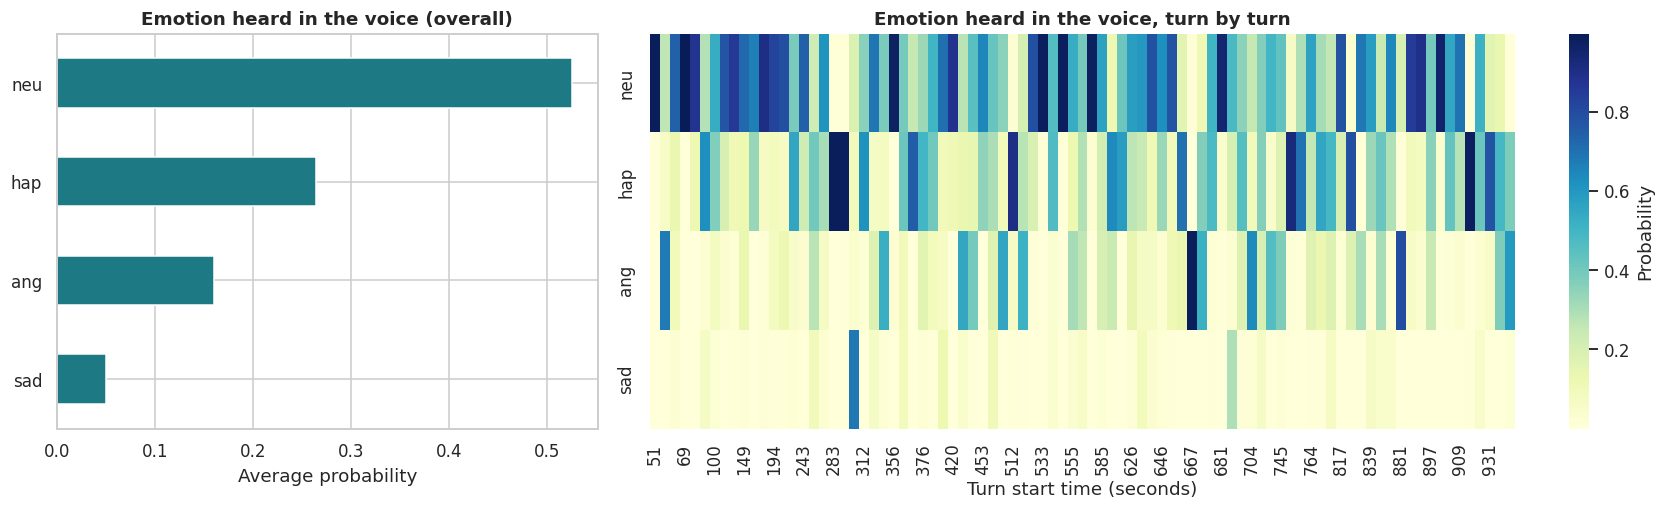

In [ ]:
# ---------------------------------------------------------------
# VOICE EMOTION: pretrained speech-emotion model on participant turns
# ---------------------------------------------------------------
RUN_SPEECH_EMOTION = True
SER_MODEL = "superb/wav2vec2-base-superb-er"   # small, open model; labels are neutral, happy, angry, sad
TARGET_SR = 16000
MAX_CHUNK_SEC = 15      # long turns are cut into pieces so memory stays small
MIN_TURN_SEC = 1.0      # very short turns are skipped because they carry too little signal

if RUN_SPEECH_EMOTION:
    from scipy.io import wavfile
    from scipy.signal import resample_poly
    from transformers import AutoFeatureExtractor, AutoModelForAudioClassification

    set_all_seeds()

    # Load the waveform as floating point between minus one and one, mono, at the sampling rate the model expects.
    sr, wave = wavfile.read(PATHS["audio"])
    wave = wave.astype(np.float32) / (np.iinfo(np.int16).max if wave.dtype == np.int16 else 1.0)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    if sr != TARGET_SR:
        wave = resample_poly(wave, TARGET_SR, sr).astype(np.float32)

    extractor = AutoFeatureExtractor.from_pretrained(SER_MODEL)
    ser_model = AutoModelForAudioClassification.from_pretrained(SER_MODEL).to("cuda" if torch.cuda.is_available() else "cpu").eval()
    id2label = ser_model.config.id2label

    def emotion_probs(chunk):
        """Return the emotion probability vector for one audio chunk."""
        inputs = extractor(chunk, sampling_rate=TARGET_SR, return_tensors="pt", padding=True)
        inputs = {k: v.to(ser_model.device) for k, v in inputs.items()}
        with torch.no_grad():
            logits = ser_model(**inputs).logits
        return torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    rows = []
    for _, turn in participant.iterrows():
        if turn["duration"] < MIN_TURN_SEC:
            continue
        segment = wave[int(turn["start_time"] * TARGET_SR): int(turn["stop_time"] * TARGET_SR)]
        chunk_len = MAX_CHUNK_SEC * TARGET_SR
        pieces = [segment[i:i + chunk_len] for i in range(0, len(segment), chunk_len) if len(segment[i:i + chunk_len]) > TARGET_SR // 2]
        if not pieces:
            continue
        lengths = np.array([len(p) for p in pieces], float)
        probs_turn = np.average([emotion_probs(p) for p in pieces], axis=0, weights=lengths)
        rows.append({"start_time": turn["start_time"], "window": turn["window"], "duration": turn["duration"],
                     **{id2label[i]: probs_turn[i] for i in range(len(probs_turn))}})

    ser = pd.DataFrame(rows)
    SER_LABELS = [id2label[i] for i in sorted(id2label)]

    overall_ser = ser[SER_LABELS].mul(ser["duration"], axis=0).sum() / ser["duration"].sum()
    window_ser = ser.groupby("window").apply(lambda g: pd.Series({l: weighted_mean(g[l], g["duration"]) for l in SER_LABELS}))
    WINDOW_TABLES["voice_emotion"] = window_ser.add_prefix("ser_")

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [0.8, 1.6]})
    overall_ser.sort_values().plot.barh(ax=axes[0], color=COLORS["participant"])
    axes[0].set_title("Emotion heard in the voice (overall)")
    axes[0].set_xlabel("Average probability")

    sns.heatmap(ser.set_index(ser["start_time"].round(0).astype(int))[SER_LABELS].T, cmap="YlGnBu", ax=axes[1],
                cbar_kws={"label": "Probability"})
    axes[1].set_title("Emotion heard in the voice, turn by turn")
    axes[1].set_xlabel("Turn start time (seconds)")
    save_fig("voice_emotion_model")
else:
    print("Speech-emotion step skipped.")

##Gaze and head pose

Frames dropped because tracking failed: 0.7%
Speaking vs listening, median values


,head_speed,head_turn_speed
speaking,,
listening / silent,14.91,4.07
speaking,47.65,14.14


Share of frames with steady gaze around the typical direction: 89.8%


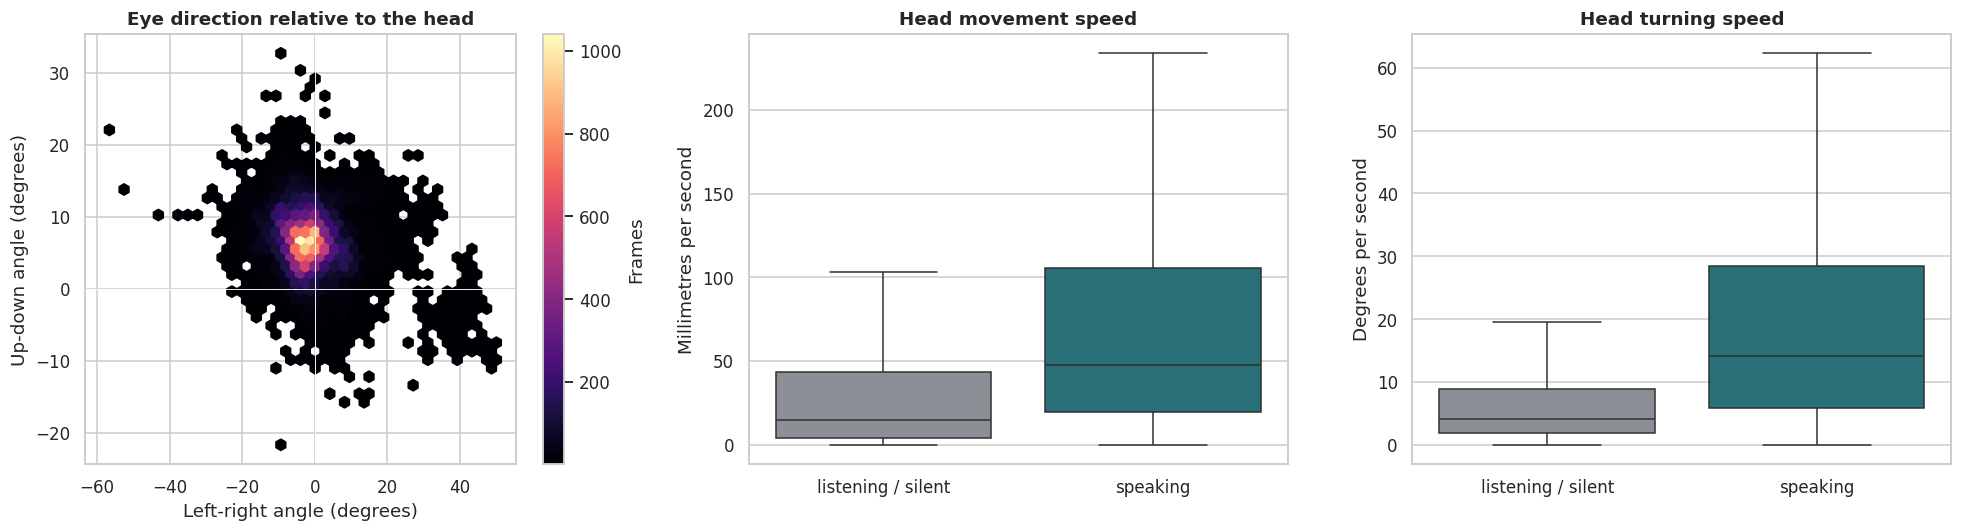

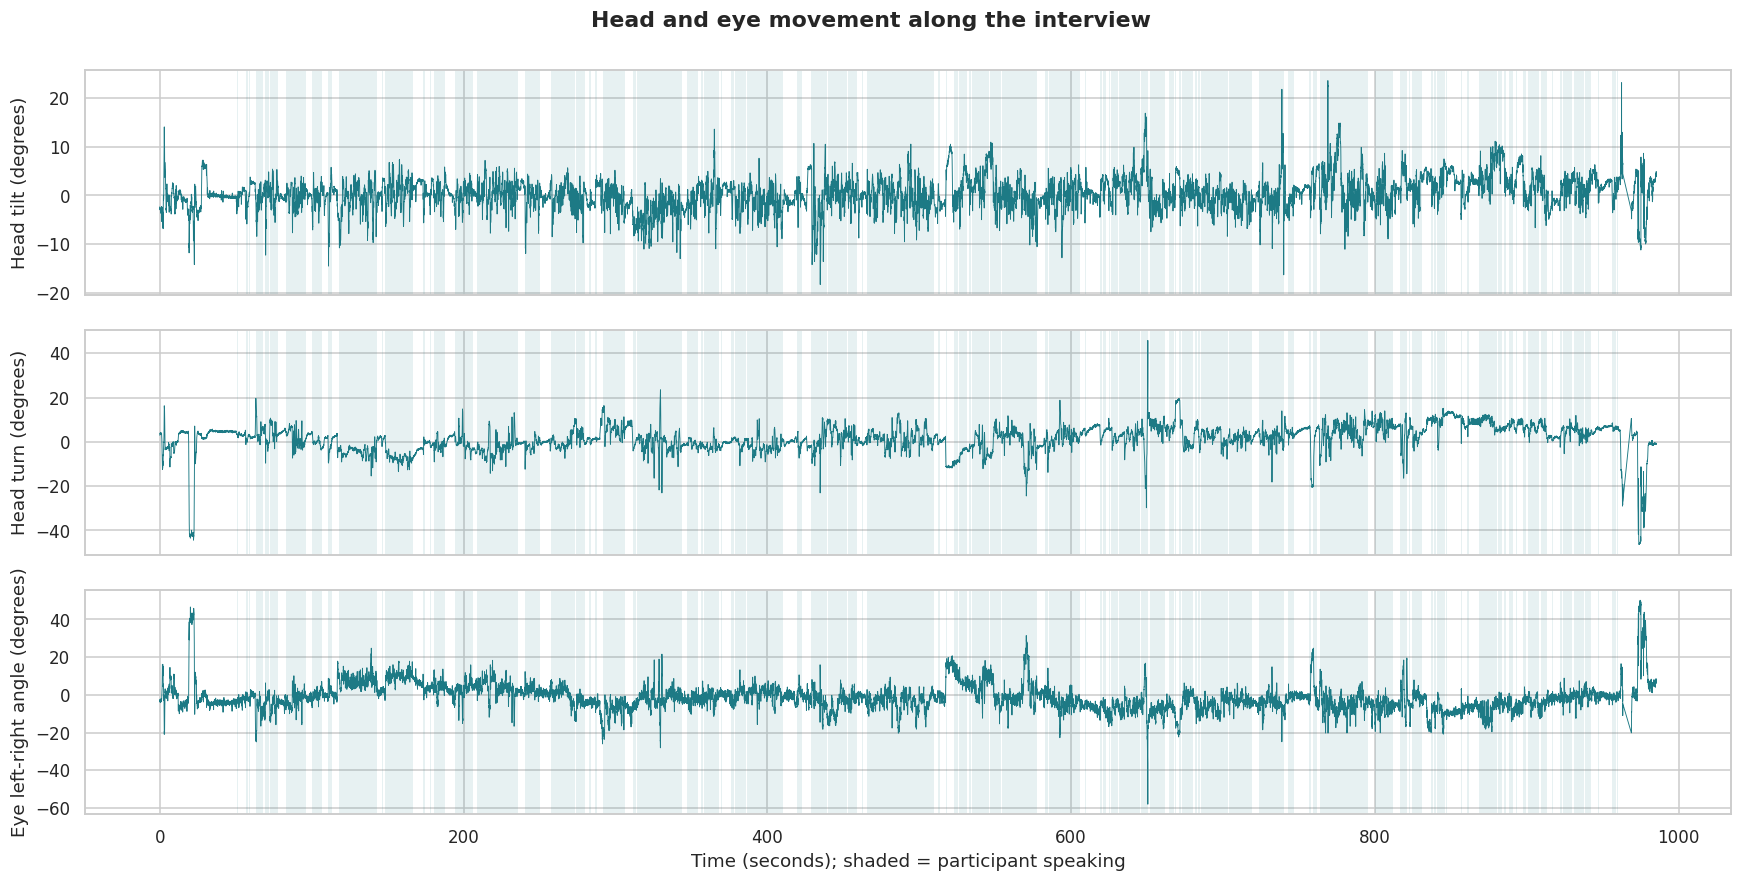

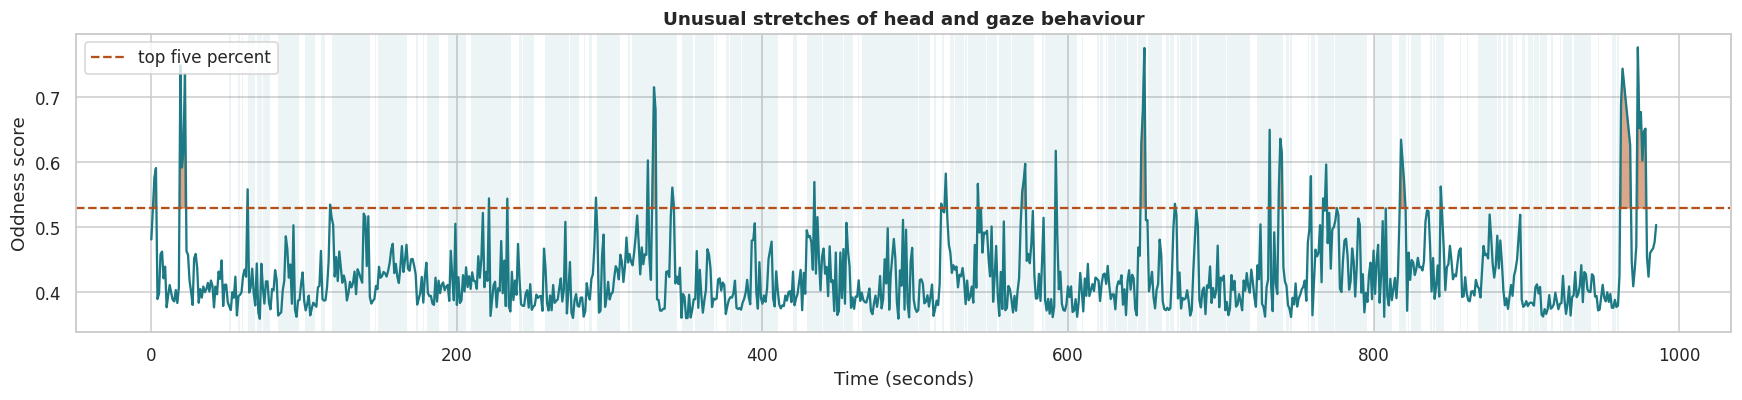

In [ ]:
# ---------------------------------------------------------------
# GAZE + HEAD POSE: angles, movement speed, steadiness, anomalies
# ---------------------------------------------------------------
from sklearn.ensemble import IsolationForest

set_all_seeds()

gaze = pd.read_csv(PATHS["gaze"], skipinitialspace=True)
pose = pd.read_csv(PATHS["pose"], skipinitialspace=True)

# Both files share the same frames; keep only frames where the tracker succeeded.
motion = gaze.merge(pose[["frame", "Tx", "Ty", "Tz", "Rx", "Ry", "Rz"]], on="frame")
print(f"Frames dropped because tracking failed: {(motion['success'] != 1).mean():.1%}")
motion = motion[motion["success"] == 1].reset_index(drop=True)
frame_step = motion["timestamp"].diff().median()

# Eye direction as two angles. Head-space vectors tell where the eyes point relative to the head; world-space
# vectors tell where they point relative to the camera. Average both eyes. In the tracker's convention a positive
# vertical angle means looking below the camera axis.
def to_angles(x, y, z):
    """Convert a 3D direction into left-right (yaw) and up-down (pitch) angles in degrees."""
    return np.degrees(np.arctan2(x, -z)), np.degrees(np.arctan2(y, -z))

motion["eye_yaw_head"], motion["eye_pitch_head"] = to_angles((motion["x_h0"] + motion["x_h1"]) / 2,
                                                             (motion["y_h0"] + motion["y_h1"]) / 2,
                                                             (motion["z_h0"] + motion["z_h1"]) / 2)
motion["gaze_yaw_cam"], motion["gaze_pitch_cam"] = to_angles((motion["x_0"] + motion["x_1"]) / 2,
                                                             (motion["y_0"] + motion["y_1"]) / 2,
                                                             (motion["z_0"] + motion["z_1"]) / 2)

# Head rotation in degrees (tilt forward-back, turn left-right, roll sideways).
for src, dst in [("Rx", "head_pitch"), ("Ry", "head_yaw"), ("Rz", "head_roll")]:
    motion[dst] = np.degrees(motion[src])

# Smooth lightly with a rolling median so tracker jitter does not look like movement, then take speeds.
smooth = motion[["Tx", "Ty", "Tz", "head_pitch", "head_yaw", "head_roll"]].rolling(5, center=True, min_periods=1).median()
dt = motion["timestamp"].diff()
gap = dt > 3 * frame_step   # after a tracking gap the difference is not a real speed
motion["head_speed"] = np.sqrt(smooth[["Tx", "Ty", "Tz"]].diff().pow(2).sum(axis=1)) / dt
motion["head_turn_speed"] = np.sqrt(smooth[["head_pitch", "head_yaw", "head_roll"]].diff().pow(2).sum(axis=1)) / dt
motion.loc[gap, ["head_speed", "head_turn_speed"]] = np.nan

motion["speaking"] = speech_mask(motion["timestamp"], participant)
motion["window"] = to_window(motion["timestamp"])

# Steadiness proxy: how often the world-space gaze stays close to the participant's own typical direction.
# Using their own median as the reference avoids assuming where the screen or camera sits.
STEADY_TOLERANCE_DEG = 5
motion["steady_gaze"] = (((motion["gaze_yaw_cam"] - motion["gaze_yaw_cam"].median()).abs() < STEADY_TOLERANCE_DEG)
                         & ((motion["gaze_pitch_cam"] - motion["gaze_pitch_cam"].median()).abs() < STEADY_TOLERANCE_DEG))

# Per-window summary for fusion, on the participant's speaking frames.
spk = motion[motion["speaking"]]
window_motion = spk.groupby("window").agg(
    gaze_spread=("eye_yaw_head", "std"),
    gaze_vertical_spread=("eye_pitch_head", "std"),
    steady_gaze_share=("steady_gaze", "mean"),
    head_speed=("head_speed", "median"),
    head_turn_speed=("head_turn_speed", "median"),
    head_yaw_spread=("head_yaw", "std"),
)
WINDOW_TABLES["motion"] = window_motion

print("Speaking vs listening, median values")
display(motion.groupby("speaking")[["head_speed", "head_turn_speed"]].median().round(2).rename(index={True: "speaking", False: "listening / silent"}))
print(f"Share of frames with steady gaze around the typical direction: {motion['steady_gaze'].mean():.1%}")

# Unusual stretches: one row per second of simple steadiness features, scored by an isolation forest.
motion["second"] = motion["timestamp"].astype(int)
per_second = motion.groupby("second").agg(
    gaze_yaw_mean=("eye_yaw_head", "mean"), gaze_pitch_mean=("eye_pitch_head", "mean"),
    gaze_yaw_std=("eye_yaw_head", "std"), head_turn=("head_turn_speed", "median"),
    head_speed=("head_speed", "median")).dropna()
forest = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED).fit(per_second)
per_second["oddness"] = -forest.score_samples(per_second[["gaze_yaw_mean", "gaze_pitch_mean", "gaze_yaw_std", "head_turn", "head_speed"]])

# ----- figures -----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Where the eyes point relative to the head; a tight blob means steady gaze.
hb = axes[0].hexbin(motion["eye_yaw_head"], motion["eye_pitch_head"], gridsize=40, cmap="magma", mincnt=1)
axes[0].axhline(0, color="white", lw=0.6)
axes[0].axvline(0, color="white", lw=0.6)
axes[0].set_title("Eye direction relative to the head")
axes[0].set_xlabel("Left-right angle (degrees)")
axes[0].set_ylabel("Up-down angle (degrees)")
plt.colorbar(hb, ax=axes[0], label="Frames")

# Head movement speed: speaking against listening.
sns.boxplot(data=motion, x="speaking", y="head_speed", ax=axes[1], palette=[COLORS["neutral"], COLORS["participant"]], showfliers=False)
axes[1].set_xticklabels(["listening / silent", "speaking"])
axes[1].set_title("Head movement speed")
axes[1].set_xlabel("")
axes[1].set_ylabel("Millimetres per second")

# Head turning speed: same comparison.
sns.boxplot(data=motion, x="speaking", y="head_turn_speed", ax=axes[2], palette=[COLORS["neutral"], COLORS["participant"]], showfliers=False)
axes[2].set_xticklabels(["listening / silent", "speaking"])
axes[2].set_title("Head turning speed")
axes[2].set_xlabel("")
axes[2].set_ylabel("Degrees per second")
save_fig("gaze_pose_overview")

# Time series of head angles with the participant's speaking turns shaded.
fig, axes = plt.subplots(3, 1, figsize=(16, 8), sharex=True)
for ax, col, label in [(axes[0], "head_pitch", "Head tilt (degrees)"),
                       (axes[1], "head_yaw", "Head turn (degrees)"),
                       (axes[2], "eye_yaw_head", "Eye left-right angle (degrees)")]:
    ax.plot(motion["timestamp"], motion[col], lw=0.6, color=COLORS["participant"])
    shade_turns(ax, participant, COLORS["participant"], alpha=0.10)
    ax.set_ylabel(label)
axes[-1].set_xlabel("Time (seconds); shaded = participant speaking")
fig.suptitle("Head and eye movement along the interview", fontweight="bold", y=1.0)
save_fig("gaze_pose_timeseries")

# Where the detector sees unusual head and gaze behaviour.
fig, ax = plt.subplots(figsize=(16, 3.8))
ax.plot(per_second.index, per_second["oddness"], color=COLORS["participant"])
threshold = per_second["oddness"].quantile(0.95)
ax.axhline(threshold, color=COLORS["interviewer"], ls="--", label="top five percent")
ax.fill_between(per_second.index, per_second["oddness"], threshold, where=per_second["oddness"] > threshold, color=COLORS["interviewer"], alpha=0.5)
shade_turns(ax, participant, COLORS["participant"], alpha=0.08)
ax.set_title("Unusual stretches of head and gaze behaviour")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Oddness score")
ax.legend()
save_fig("gaze_pose_anomalies")

##Fusion: all streams on one timeline

Streams included: ['talk', 'sentiment', 'emotion', 'language', 'face', 'voice', 'voice_emotion', 'motion']


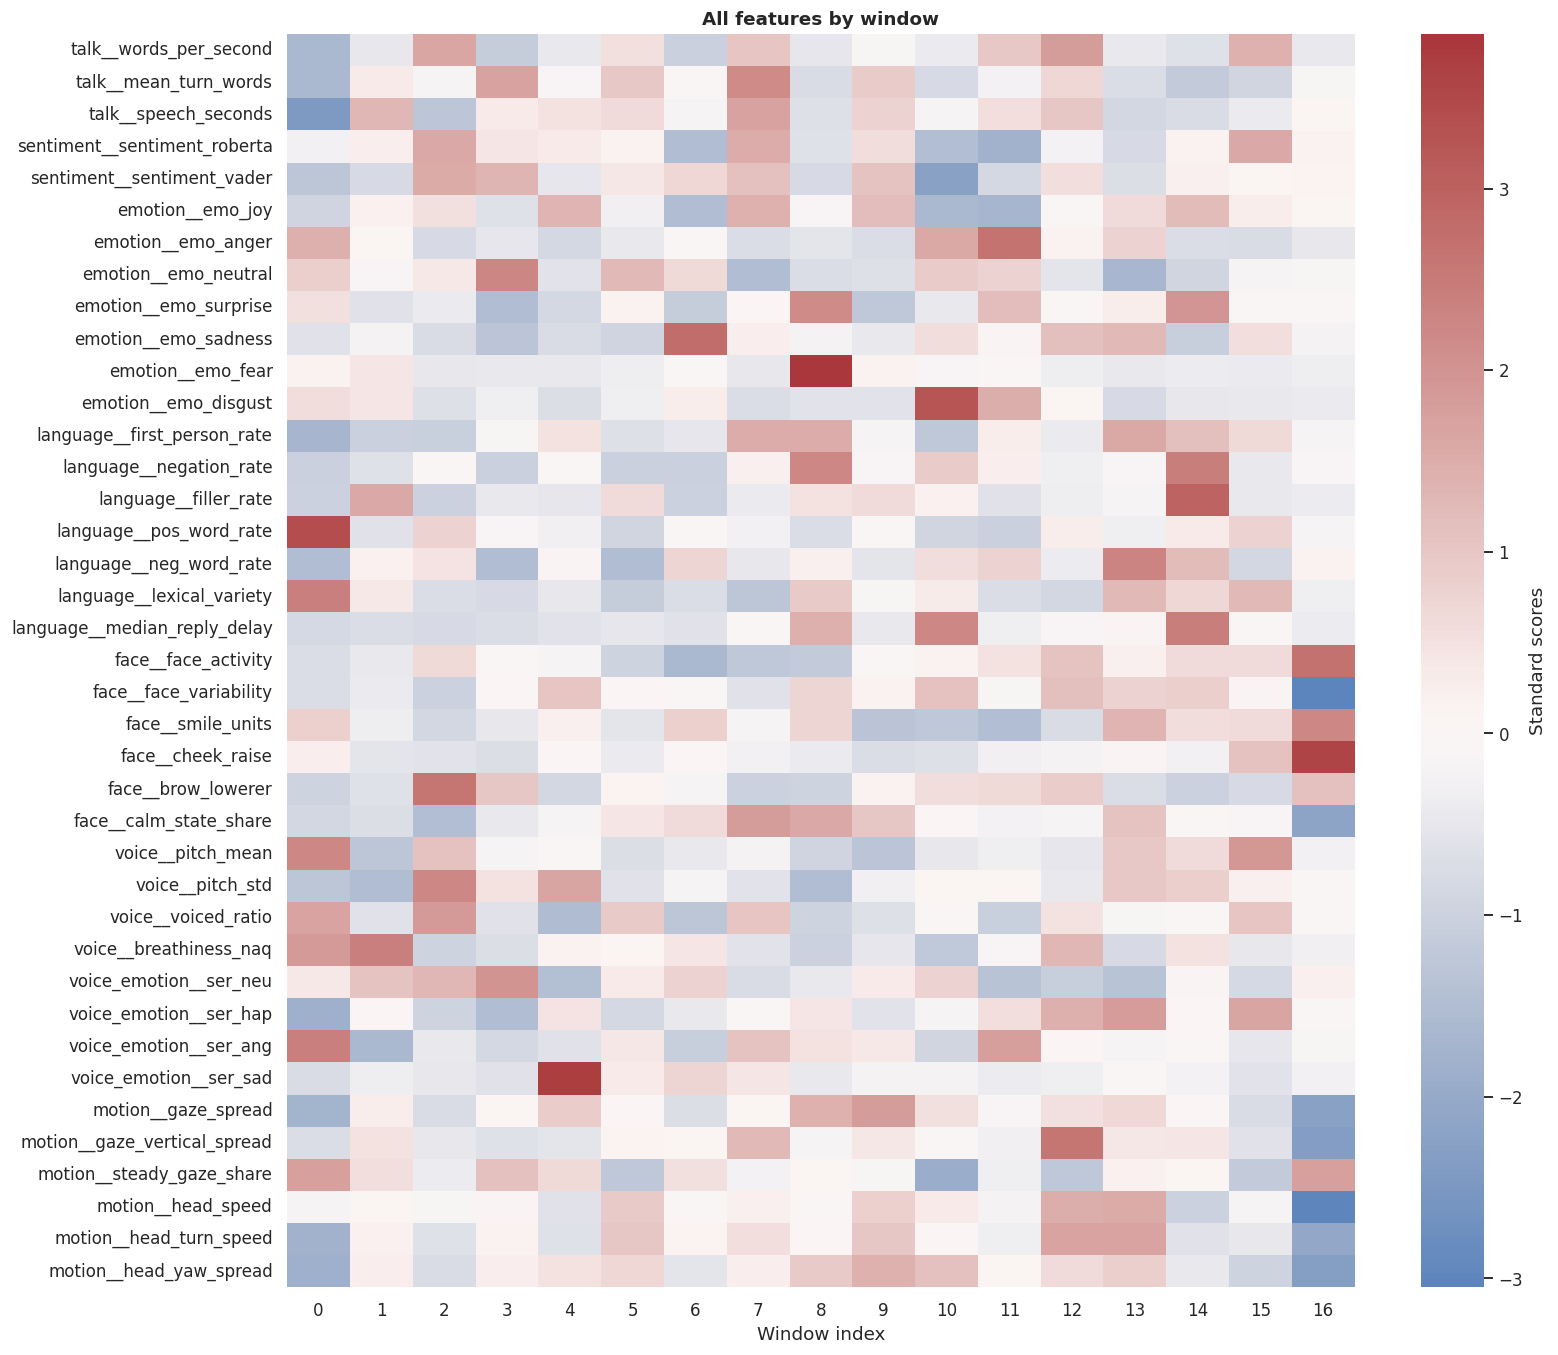

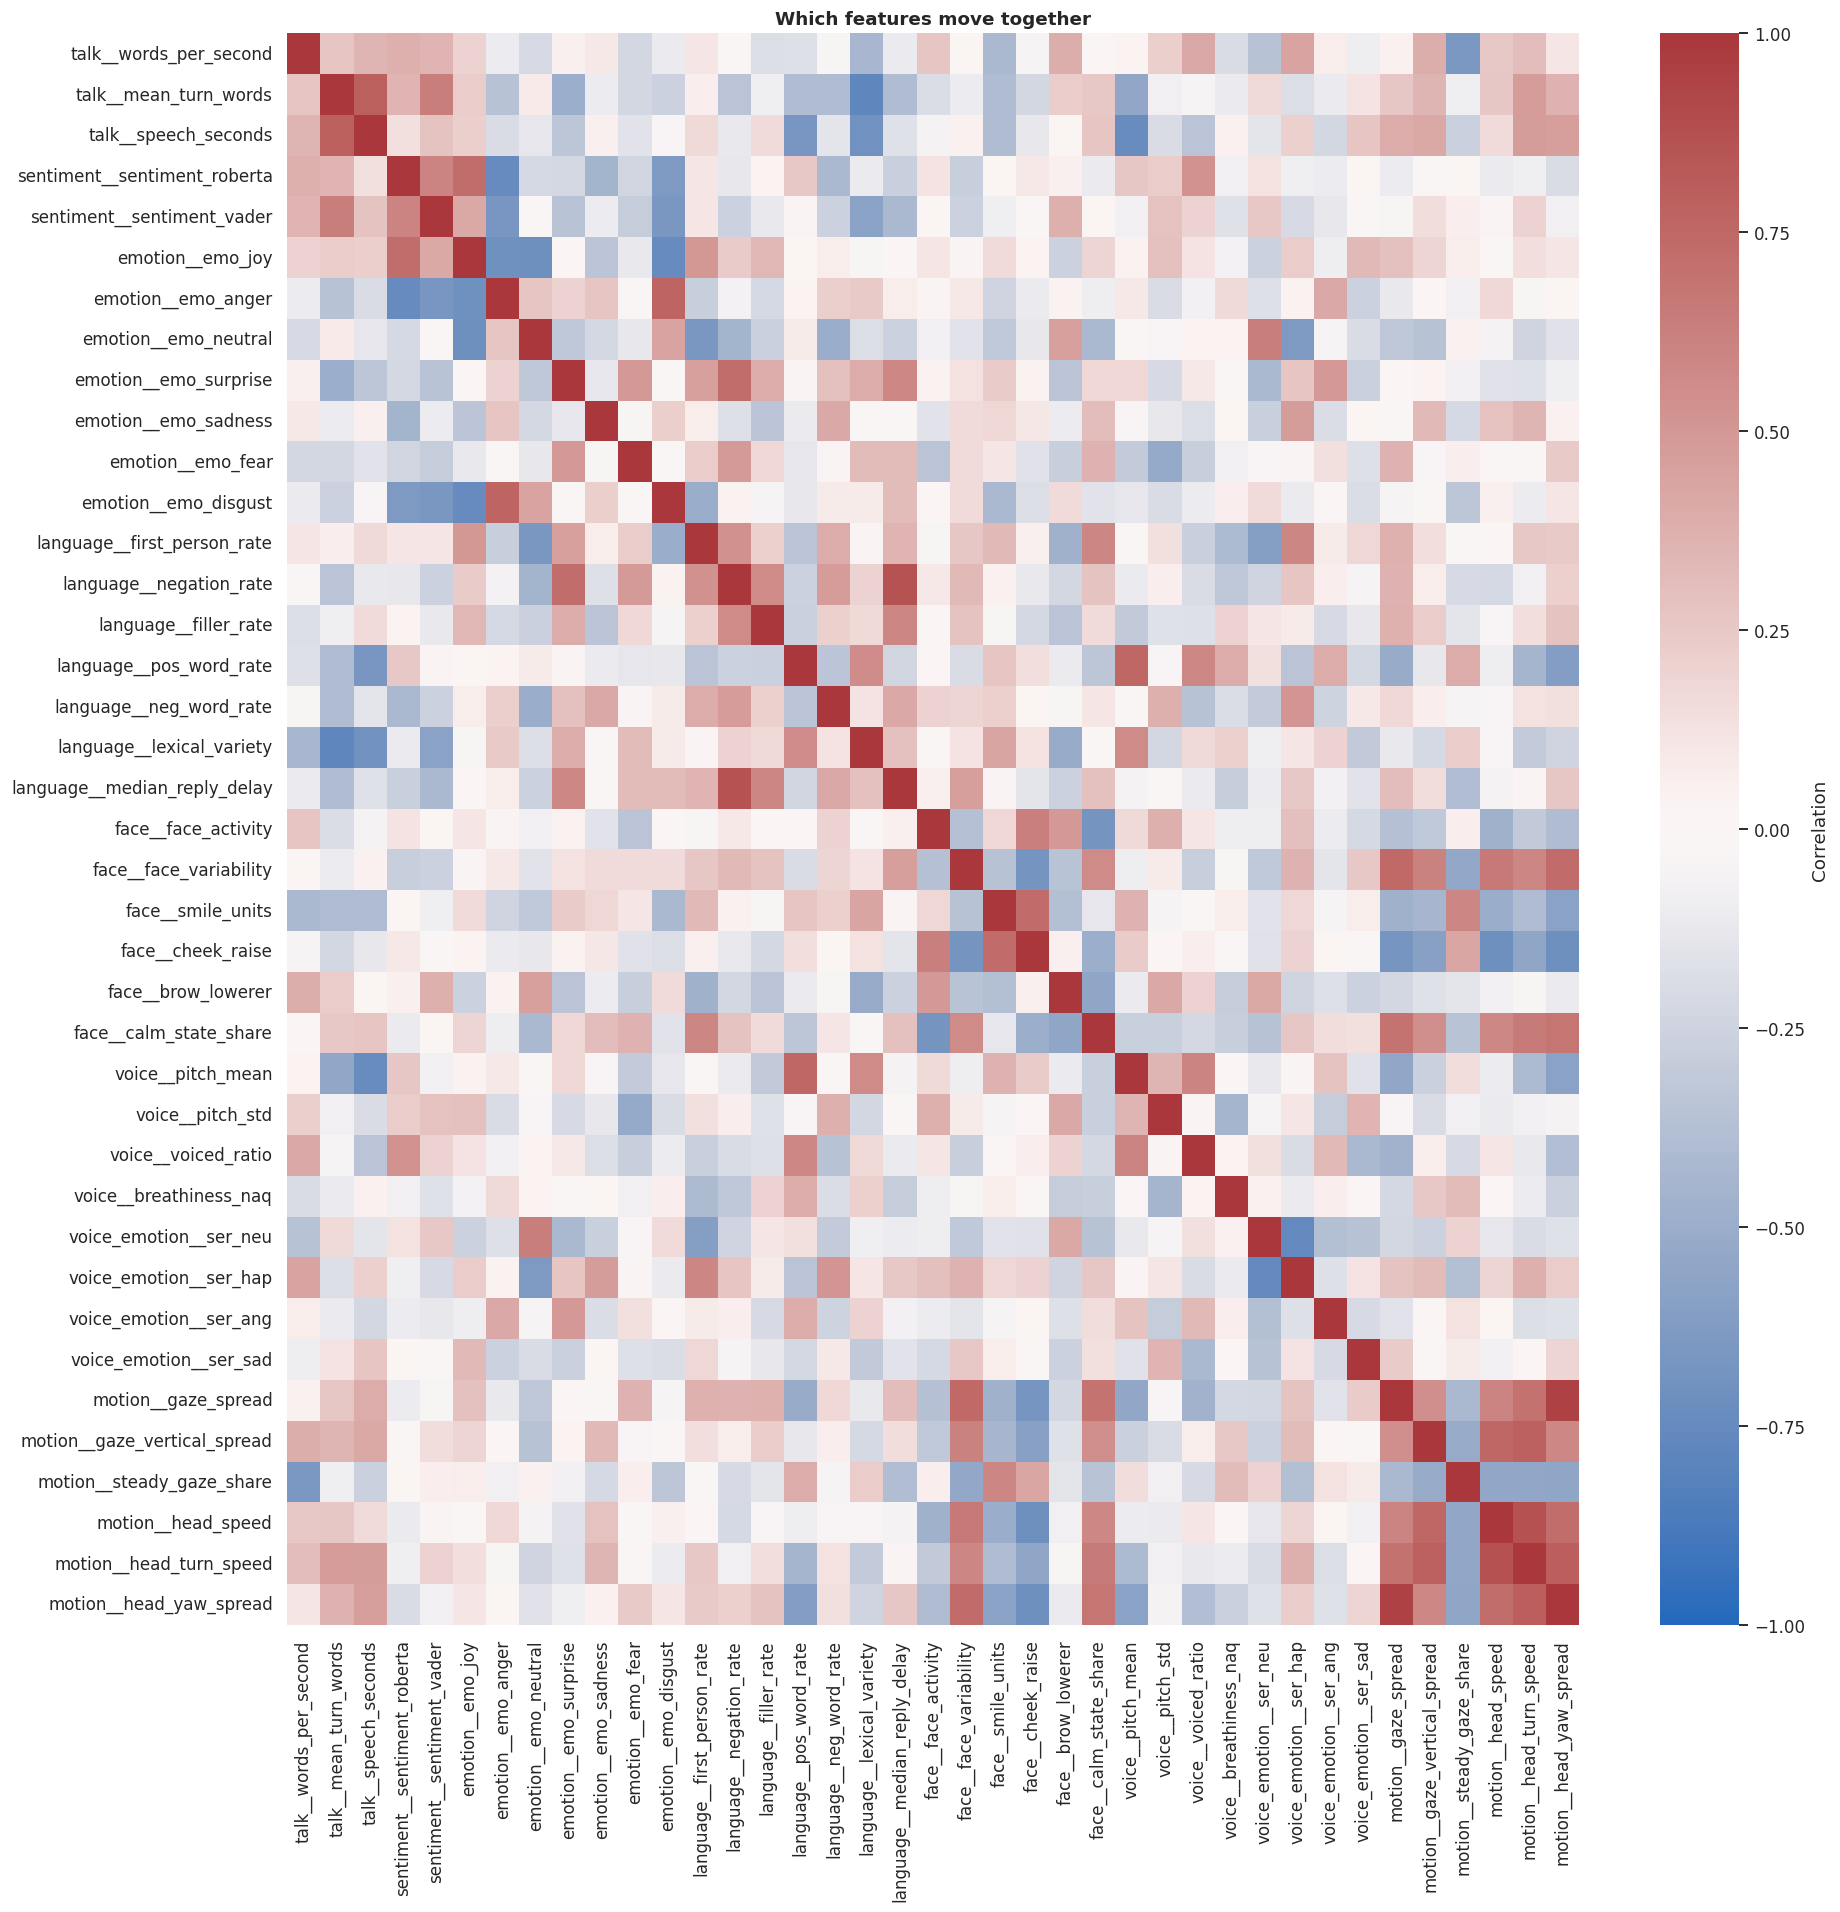

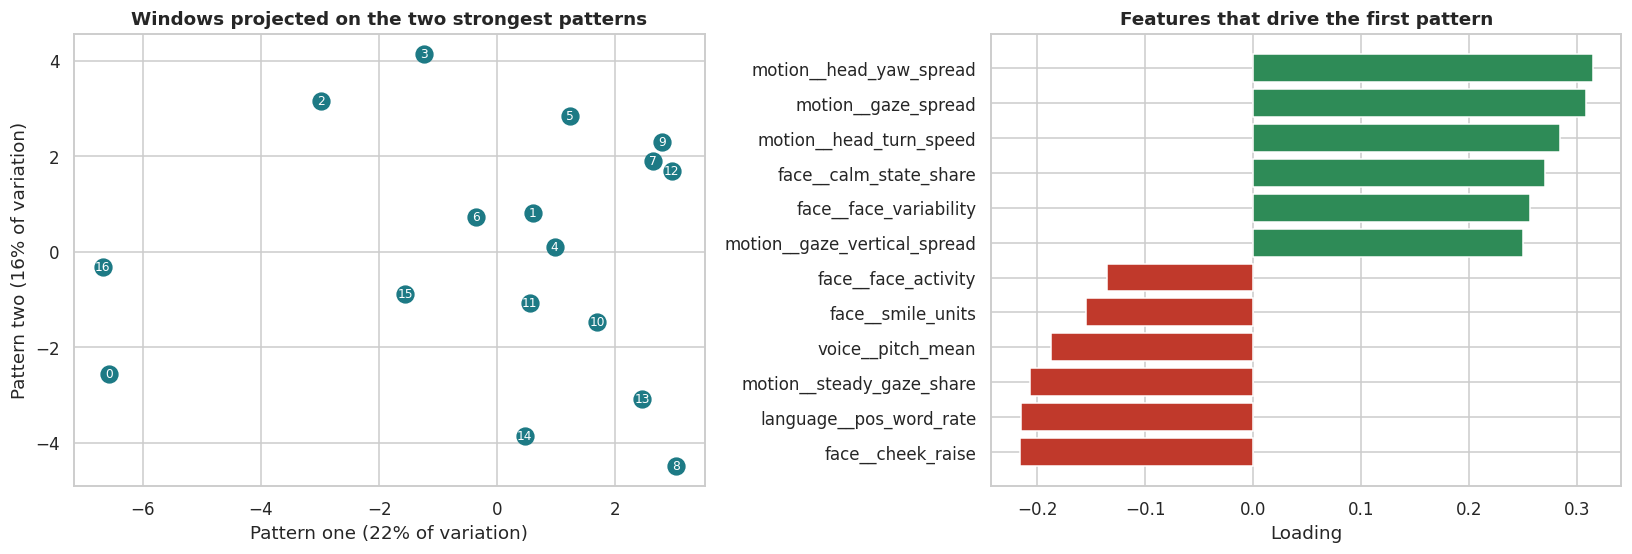

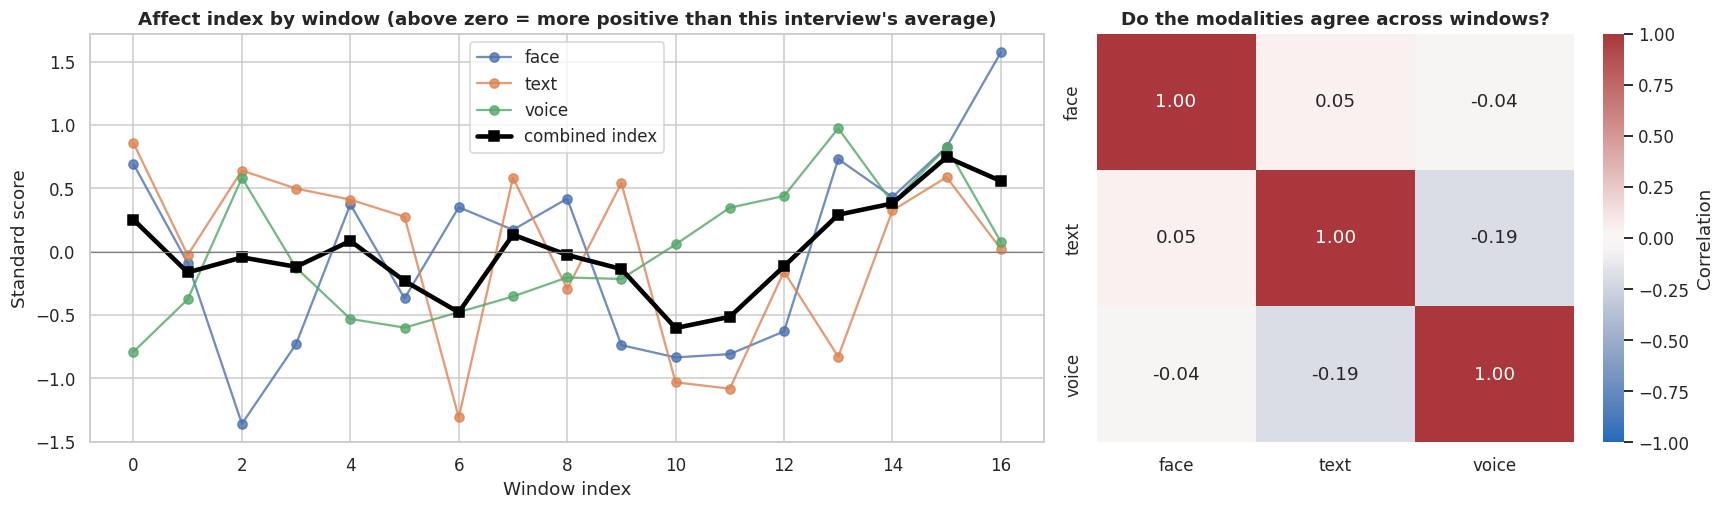

,value
text: overall sentiment (RoBERTa),0.197637
text: strongest emotion,joy
text: median reply delay (s),2.56
face: switches per minute,24.233129
voice: median pitch (Hz),187.0
voice emotion: strongest,neu
gaze: share of steady frames,0.898256



Remember: this is one participant, so the table describes behaviour; compare it with the known label by hand and say so openly in the write-up.


In [ ]:
# ---------------------------------------------------------------
# FUSION: join the streams per window, compare, and build a transparent affect index
# ---------------------------------------------------------------
from sklearn.decomposition import PCA

# Join every stream's window summary on the window index; missing streams are simply absent.
tables = {name: tbl.add_prefix(f"{name}__") for name, tbl in WINDOW_TABLES.items() if len(tbl)}
fused = pd.concat(tables.values(), axis=1).sort_index()
print("Streams included:", list(tables))

# Require a feature to be present in most windows, and fill the rare gap with the column median.
usable = fused.loc[:, fused.notna().mean() >= 0.6]
fused_filled = usable.fillna(usable.median())
fused_z = fused_filled.apply(zscore)

# Which features count as "more positive feeling" (plus one) or "more negative feeling" (minus one).
# Edit this dictionary to try other definitions; the index is rebuilt from it automatically.
AFFECT_DIRECTIONS = {
    "sentiment__sentiment_roberta": +1,
    "emotion__emo_joy": +1,
    "emotion__emo_sadness": -1,
    "language__pos_word_rate": +1,
    "language__neg_word_rate": -1,
    "face__smile_units": +1,
    "face__cheek_raise": +1,
    "face__brow_lowerer": -1,
    "voice__pitch_std": +1,
    "voice_emotion__ser_hap": +1,
    "voice_emotion__ser_sad": -1,
}
# Which stream each feature belongs to, so contributions can be averaged inside a stream first.
STREAM_OF = {"sentiment": "text", "emotion": "text", "language": "text", "talk": "text",
             "face": "face", "voice": "voice", "voice_emotion": "voice", "motion": "gaze and pose"}
MODALITY_OF = lambda col: STREAM_OF[col.split("__")[0]]

present = [c for c in AFFECT_DIRECTIONS if c in fused_z.columns]
contrib = pd.DataFrame({c: AFFECT_DIRECTIONS[c] * fused_z[c] for c in present})
modality = pd.Series({c: MODALITY_OF(c) for c in present})
# Average inside each modality first, then across modalities, so a stream with many features does not dominate.
per_modality = contrib.T.groupby(modality).mean().T
fused["affect_index"] = per_modality.mean(axis=1)

# ----- figures -----
# Every feature, every window, on one scale: the quickest way to see where streams agree.
fig, ax = plt.subplots(figsize=(15, max(6, 0.32 * fused_z.shape[1])))
sns.heatmap(fused_z.T, cmap="vlag", center=0, ax=ax, cbar_kws={"label": "Standard scores"})
ax.set_title("All features by window")
ax.set_xlabel("Window index")
save_fig("fusion_feature_heatmap")

# Which streams move together across windows (few windows, so read it as a hint, not proof).
corr = fused_z.corr()
fig, ax = plt.subplots(figsize=(max(9, 0.45 * corr.shape[0]), max(8, 0.45 * corr.shape[0])))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Correlation"},
            xticklabels=True, yticklabels=True)
ax.set_title("Which features move together")
save_fig("fusion_correlation")

# Windows that look alike land close together in this projection.
if fused_z.shape[0] >= 3:
    pca = PCA(n_components=2, random_state=SEED)
    coords = pca.fit_transform(fused_z)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    axes[0].scatter(coords[:, 0], coords[:, 1], s=120, color=COLORS["participant"])
    for idx, (x, y) in zip(fused_z.index, coords):
        axes[0].annotate(str(idx), (x, y), ha="center", va="center", color="white", fontsize=8)
    axes[0].set_title("Windows projected on the two strongest patterns")
    axes[0].set_xlabel(f"Pattern one ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    axes[0].set_ylabel(f"Pattern two ({pca.explained_variance_ratio_[1]:.0%} of variation)")

    loadings = pd.Series(pca.components_[0], index=fused_z.columns).sort_values()
    top = pd.concat([loadings.head(6), loadings.tail(6)])
    axes[1].barh(top.index, top.values, color=[COLORS["negative"] if v < 0 else COLORS["positive"] for v in top.values])
    axes[1].set_title("Features that drive the first pattern")
    axes[1].set_xlabel("Loading")
    save_fig("fusion_pca")

# The affect index: how each modality contributes, and the combined line.
if len(present):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
    per_modality.plot(marker="o", ax=axes[0], alpha=0.8)
    axes[0].plot(fused.index, fused["affect_index"], color="black", lw=3, marker="s", label="combined index")
    axes[0].axhline(0, color="grey", lw=0.8)
    axes[0].set_title("Affect index by window (above zero = more positive than this interview's average)")
    axes[0].set_xlabel("Window index")
    axes[0].set_ylabel("Standard score")
    axes[0].legend()

    # Do the modalities rise and fall together? Every feature is standardised inside this one interview, so averages
    # sit at zero by construction; agreement across windows is the informative quantity.
    sns.heatmap(per_modality.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[1],
                cbar_kws={"label": "Correlation"})
    axes[1].set_title("Do the modalities agree across windows?")
    save_fig("fusion_affect_index")

# One headline table: the plain-language numbers worth quoting from each stream.
headline = {}
if "sentiment" in WINDOW_TABLES: headline["text: overall sentiment (RoBERTa)"] = overall["roberta_weighted_mean"]
if "emotion" in WINDOW_TABLES: headline["text: strongest emotion"] = overall_emotion.idxmax()
if "language" in WINDOW_TABLES: headline["text: median reply delay (s)"] = valid_delay.median()
if "face" in WINDOW_TABLES: headline["face: switches per minute"] = switches_per_minute
if "voice" in WINDOW_TABLES: headline["voice: median pitch (Hz)"] = speech_voiced["F0"].median()
if "voice_emotion" in WINDOW_TABLES: headline["voice emotion: strongest"] = overall_ser.idxmax()
if "motion" in WINDOW_TABLES: headline["gaze: share of steady frames"] = motion["steady_gaze"].mean()
display(pd.Series(headline, name="value").to_frame())

#319_P

In [ ]:
zip_path = '/content/drive/My Drive/Multimodal_CEDS/319_P.zip'

if os.path.exists(zip_path):
    file_name = os.path.basename(zip_path)
    folder_name = os.path.splitext(file_name)[0]

    target_dir = f'/content/{folder_name}'
    os.makedirs(target_dir, exist_ok=True)

    print(f"Extracting '{zip_path}' to '{target_dir}'...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(target_dir)
    print("Extraction complete!")
else:
    print(f"Please upload '{os.path.basename(zip_path)}' to your Google Drive home directory first.")

Extracting '/content/drive/My Drive/Multimodal_CEDS/319_P.zip' to '/content/319_P'...
Extraction complete!


In [ ]:
# ---------------------------------------------------------------
# SETUP: libraries, one global seed, file paths and plot style
# ---------------------------------------------------------------
# Colab does not ship these two packages, so install them quietly.
!pip -q install vaderSentiment hmmlearn

import os, re, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

warnings.filterwarnings("ignore")

# One seed drives python, numpy and torch, so every rerun gives the same numbers and figures.
SEED = 42

def set_all_seeds(seed=SEED):
    """Fix every random number generator we rely on. Call again before any model step."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        from transformers import set_seed
        set_seed(seed)
    except Exception:
        pass

set_all_seeds()

# Change only SESSION_ID (and BASE_DIR if your folder differs) to reuse the notebook on another participant.
SESSION_ID = "319"
BASE_DIR = Path(f"/content/{SESSION_ID}_P")

PATHS = {
    "transcript": BASE_DIR / f"{SESSION_ID}_TRANSCRIPT.csv",
    "aus":        BASE_DIR / f"{SESSION_ID}_CLNF_AUs.txt",
    "gaze":       BASE_DIR / f"{SESSION_ID}_CLNF_gaze.txt",
    "pose":       BASE_DIR / f"{SESSION_ID}_CLNF_pose.txt",
    "covarep":    BASE_DIR / f"{SESSION_ID}_COVAREP.csv",
    "formant":    BASE_DIR / f"{SESSION_ID}_FORMANT.csv",
    "audio":      BASE_DIR / f"{SESSION_ID}_AUDIO.wav",
}

# Length of the time windows used to line up all streams in the fusion step, in seconds.
WINDOW_SEC = 60

FIG_DIR = Path(f"/content/figures_{SESSION_ID}")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# A small fixed palette so the same idea has the same colour in every figure.
COLORS = {"participant": "#1D7A85", "interviewer": "#B5501A",
          "neutral": "#8A8F98", "positive": "#2E8B57", "negative": "#C0392B"}

def save_fig(name):
    """Tidy the layout, save the figure into the figures folder, then show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Every analysis cell drops a small per-window summary in here; the fusion cell reads it back.
WINDOW_TABLES = {}

# Quick check that all files are where we expect them.
for key, path in PATHS.items():
    print(f"{key:<11} {'found' if path.exists() else 'MISSING'}  {path}")

transcript  found  /content/319_P/319_TRANSCRIPT.csv
aus         found  /content/319_P/319_CLNF_AUs.txt
gaze        found  /content/319_P/319_CLNF_gaze.txt
pose        found  /content/319_P/319_CLNF_pose.txt
covarep     found  /content/319_P/319_COVAREP.csv
formant     found  /content/319_P/319_FORMANT.csv
audio       found  /content/319_P/319_AUDIO.wav


In [ ]:
# ---------------------------------------------------------------
# SHARED HELPERS: transcript loading and time-alignment tools
# ---------------------------------------------------------------
def load_transcript(path):
    """Read the interview transcript and add the helper columns the analyses need."""
    t = pd.read_csv(path, sep="\t")
    t["value"] = t["value"].fillna("").astype(str)
    # Remove stage-direction tags such as laughter or throat clearing; keep only spoken words.
    t["clean"] = (t["value"].str.replace(r"<[^>]*>", " ", regex=True)
                            .str.replace(r"\s+", " ", regex=True).str.strip())
    t["duration"] = t["stop_time"] - t["start_time"]
    t["n_words"] = t["clean"].str.split().str.len().fillna(0).astype(int)
    return t.sort_values("start_time").reset_index(drop=True)


def to_window(times):
    """Map times in seconds to the index of the analysis window they fall into."""
    return (np.asarray(times) // WINDOW_SEC).astype(int)


def speech_mask(times, turns):
    """True for every time stamp that falls inside any of the given turns.
    This is how we cut audio and video features down to only the participant speaking."""
    times = np.asarray(times)
    mask = np.zeros(len(times), dtype=bool)
    for start, stop in zip(turns["start_time"], turns["stop_time"]):
        mask |= (times >= start) & (times <= stop)
    return mask


def shade_turns(ax, turns, color, alpha=0.12):
    """Paint the background of a time axis wherever the given speaker is talking."""
    for start, stop in zip(turns["start_time"], turns["stop_time"]):
        ax.axvspan(start, stop, color=color, alpha=alpha, lw=0)


def weighted_mean(values, weights):
    """Average that gives longer utterances more say; falls back to a plain mean if all weights are empty."""
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    return np.average(values, weights=weights) if weights.sum() > 0 else values.mean()


def zscore(series):
    """Standardise a column so different streams can be compared on one scale."""
    spread = series.std(ddof=0)
    return (series - series.mean()) / (spread if spread > 0 else 1)

In [ ]:
import pandas as pd
import numpy as np

##Transcript

In [ ]:
df = pd.read_csv("/content/319_P/319_TRANSCRIPT.csv",sep="\t")
df.head(10)

,start_time,stop_time,speaker,value
0,48.58,51.65,Ellie,hi i'm ellie thanks for coming in today
1,52.31,55.79,Ellie,i was created to talk to people in a safe and secure environment
2,56.48,63.05,Ellie,i'm not a therapist but i'm here to learn about people and would love to learn about you i'll ask a few questions to get us started
3,63.71,68.35,Ellie,and please feel free to tell me anything your answers are totally confidential
4,68.94,70.12,Ellie,are you okay with this
5,70.60,71.02,Participant,sure
6,72.10,72.56,Ellie,okay
7,73.49,75.60,Ellie,so how are you doing today
8,76.21,77.53,Participant,mm okay
9,79.05,79.68,Ellie,that's good


In [ ]:
display(df.info())
print("\n\n\n")
display(df.describe())
print("\n\n\n")
display(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186 entries, 0 to 185
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   start_time  186 non-null    float64
 1   stop_time   186 non-null    float64
 2   speaker     186 non-null    object 
 3   value       186 non-null    object 
dtypes: float64(2), object(2)
memory usage: 5.9+ KB


None

,start_time,stop_time
count,186.000000,186.000000
mean,336.532527,338.379731
std,168.146517,168.195909
min,48.580000,51.650000
25%,188.905000,190.215000
50%,339.565000,340.660000
75%,473.795000,476.040000
max,648.030000,648.370000


,0
start_time,0
stop_time,0
speaker,0
value,0


In [ ]:
transcript = load_transcript(PATHS["transcript"])

# Participant turns that actually contain words, and the interviewer turns kept separately.
participant = transcript[(transcript["speaker"] == "Participant") & (transcript["n_words"] > 0)].reset_index(drop=True)
interviewer = transcript[transcript["speaker"] == "Ellie"].reset_index(drop=True)
participant["window"] = to_window(participant["start_time"])

print(f"Interview runs from {transcript['start_time'].min():.0f}s to {transcript['stop_time'].max():.0f}s")
print(transcript["speaker"].value_counts().to_string())
transcript.head()

Interview runs from 49s to 648s
speaker
Participant    107
Ellie           79


,start_time,stop_time,speaker,value,clean,duration,n_words
0,48.58,51.65,Ellie,hi i'm ellie thanks for coming in today,hi i'm ellie thanks for coming in today,3.07,8
1,52.31,55.79,Ellie,i was created to talk to people in a safe and secure environment,i was created to talk to people in a safe and secure environment,3.48,13
2,56.48,63.05,Ellie,i'm not a therapist but i'm here to learn about people and would love to learn about you i'll ask a few questions to get us started,i'm not a therapist but i'm here to learn about people and would love to learn about you i'll ask a few questions to get us started,6.57,27
3,63.71,68.35,Ellie,and please feel free to tell me anything your answers are totally confidential,and please feel free to tell me anything your answers are totally confidential,4.64,13
4,68.94,70.12,Ellie,are you okay with this,are you okay with this,1.18,5


In [ ]:
ellie_corpus = " ".join(transcript[transcript["speaker"] == "Ellie"]["clean"].astype(str).tolist())
participant_corpus = " ".join(participant["clean"].astype(str).tolist())

print(f"Ellie corpus length: {len(ellie_corpus)} characters, {len(ellie_corpus.split())} words")
print(f"Participant corpus length: {len(participant_corpus)} characters, {len(participant_corpus.split())} words")

Ellie corpus length: 2419 characters, 472 words
Participant corpus length: 3304 characters, 672 words


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download necessary NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

def preprocess_text(text, min_word_len=3):
    # 1. Remove stage-direction tags like <laughter>, <throat-clearing>, etc.
    cleaned = re.sub(r'<[^>]*>', ' ', text)

    # 2. Convert to lowercase and find all alphabetical tokens
    words = re.findall(r"\b[a-z']+\b", cleaned.lower())

    # 3. Load stopwords and lemmatizer
    stop_words = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer()

    # 4. Filter stopwords, apply lemmatization, and enforce minimum word length (n-word filter)
    processed_words = [
        lemmatizer.lemmatize(w)
        for w in words
        if w not in stop_words and len(w) >= min_word_len
    ]

    # Join back into a clean string
    return ' '.join(processed_words)

ellie_clean_corpus = preprocess_text(ellie_corpus)
participant_clean_corpus = preprocess_text(participant_corpus)

print(f"Ellie Cleaned Corpus length: {len(ellie_clean_corpus)} characters")
print(f"Participant Cleaned Corpus length: {len(participant_clean_corpus)} characters")

Ellie Cleaned Corpus length: 1291 characters
Participant Cleaned Corpus length: 1883 characters


Ellie's most common words: [('okay', 9), ('really', 6), ('good', 5), ('things', 4), ('feel', 3), ('tell', 3), ('hear', 3), ('parent', 3), ('best', 3), ('last', 3)]
Participant's most common words: [('know', 21), ('well', 11), ('good', 5), ('say', 5), ('think', 5), ('hmm', 5), ('yeah', 5), ('question', 4), ('children', 4), ('lot', 4)]


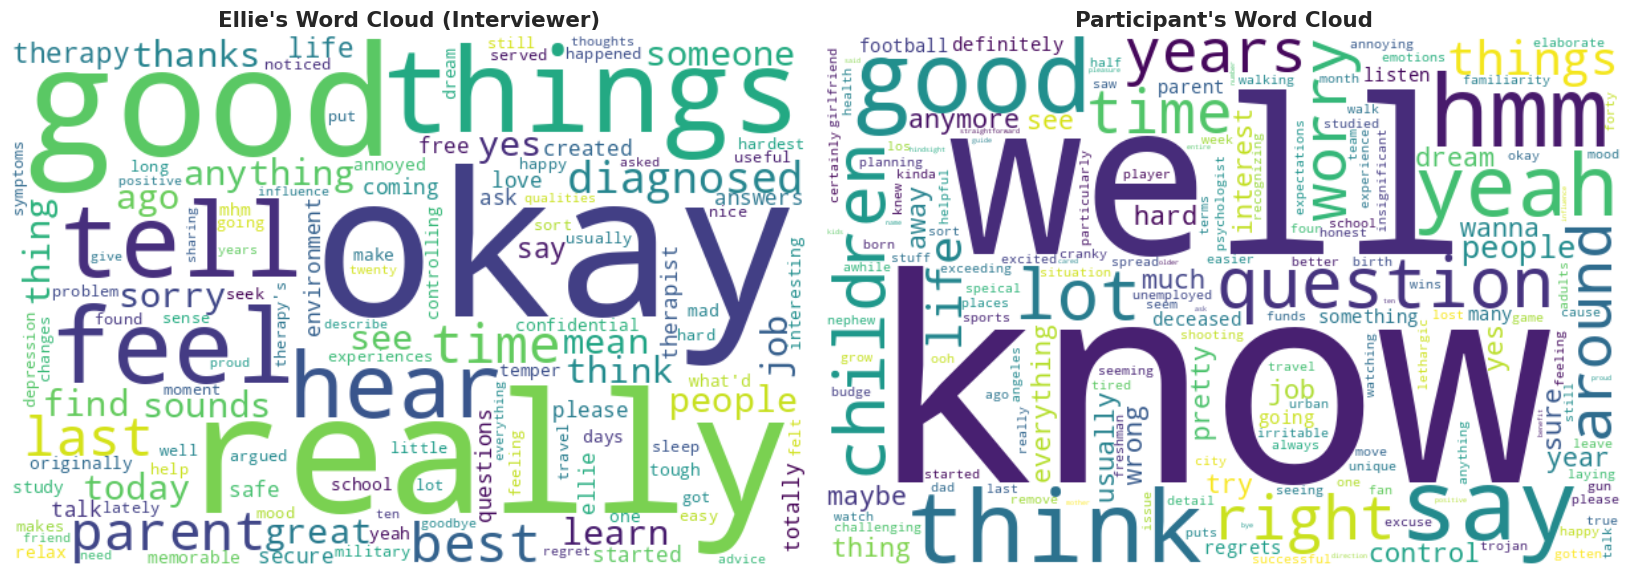

In [ ]:
import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords', quiet=True)

# Combine NLTK English stopwords with WordCloud's default STOPWORDS programmatically
stop_words = set(stopwords.words('english')).union(STOPWORDS)

# Separate Ellie (interviewer) and Participant turns
ellie_turns = transcript[transcript["speaker"] == "Ellie"]["clean"].tolist()
participant_turns = transcript[transcript["speaker"] == "Participant"]["clean"].tolist()

# Helper to clean and tokenize a corpus
def get_word_frequencies(turns_list):
    text_corpus = " ".join(turns_list).lower()
    words = re.findall(r"\b[a-z']{3,}\b", text_corpus)
    filtered_words = [w for w in words if w not in stop_words]
    return Counter(filtered_words)

ellie_counts = get_word_frequencies(ellie_turns)
participant_counts = get_word_frequencies(participant_turns)

print("Ellie's most common words:", ellie_counts.most_common(10))
print("Participant's most common words:", participant_counts.most_common(10))

# Generate Word Clouds
wc_ellie = WordCloud(width=600, height=400, background_color='white').generate_from_frequencies(ellie_counts)
wc_participant = WordCloud(width=600, height=400, background_color='white').generate_from_frequencies(participant_counts)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(wc_ellie, interpolation='bilinear')
axes[0].set_title("Ellie's Word Cloud (Interviewer)", fontsize=14, weight='bold')
axes[0].axis('off')

axes[1].imshow(wc_participant, interpolation='bilinear')
axes[1].set_title("Participant's Word Cloud", fontsize=14, weight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

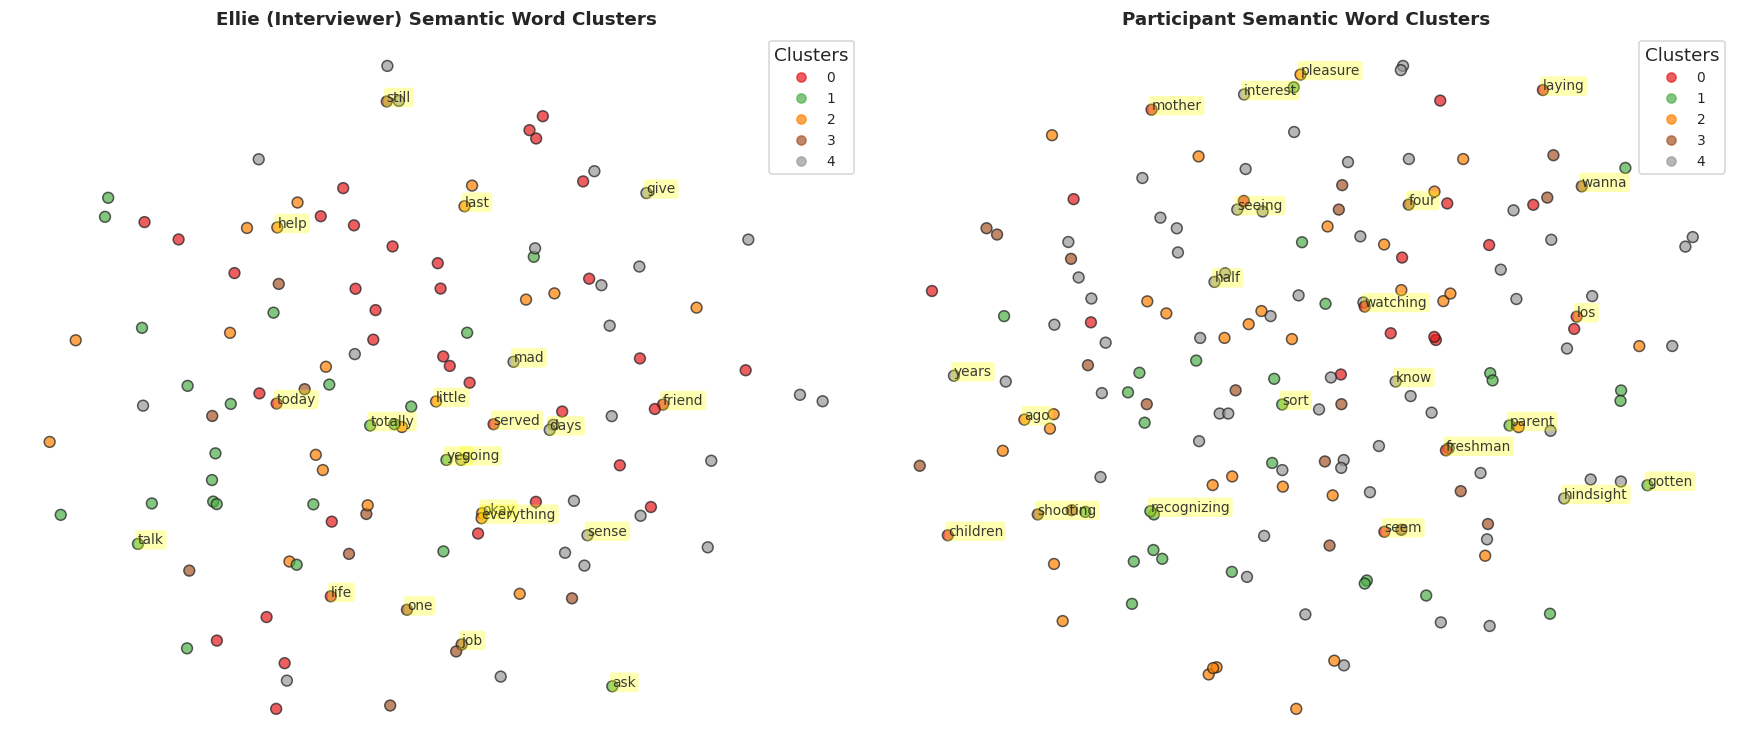

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

def cluster_and_visualize_speaker(texts, speaker_name, stop_words_list, color_map='Set1'):
    # Tokenize and filter using the preprocessed corpora
    sentences = [re.findall(r"\b[a-z']{3,}\b", s.lower()) for s in texts]
    sentences = [[w for w in s if w not in stop_words_list] for s in sentences]
    sentences = [s for s in sentences if len(s) > 0]

    if not sentences:
        print(f"No vocabulary to cluster for {speaker_name}.")
        return None, None, None

    # Train Word2Vec
    w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4, seed=42)
    words_vocab = list(w2v_model.wv.index_to_key)
    word_vectors = w2v_model.wv.vectors

    # Cluster words
    n_clusters = min(5, len(words_vocab))
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(word_vectors)

    # Dimension reduction
    tsne = TSNE(n_components=2, perplexity=min(30, max(5, len(words_vocab)-1)), random_state=42, init='pca', n_iter=1000)
    coords_2d = tsne.fit_transform(word_vectors)

    return words_vocab, labels, coords_2d

# Prepare Ellie and Participant corpora from the loaded transcript
ellie_texts = transcript[transcript["speaker"] == "Ellie"]["clean"].tolist()
participant_texts = participant["clean"].tolist()

# Perform clustering using the unified programmatic stop_words list
e_vocab, e_labels, e_coords = cluster_and_visualize_speaker(ellie_texts, "Ellie", stop_words)
p_vocab, p_labels, p_coords = cluster_and_visualize_speaker(participant_texts, "Participant", stop_words)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, vocab, labels, coords, title in [
    (axes[0], e_vocab, e_labels, e_coords, "Ellie (Interviewer) Semantic Word Clusters"),
    (axes[1], p_vocab, p_labels, p_coords, "Participant Semantic Word Clusters")
]:
    if coords is not None:
        scatter = ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap='Set1', alpha=0.7, edgecolors='k', s=50)
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.axis('off')

        # Add legend
        legend_elements = scatter.legend_elements()
        ax.legend(*legend_elements, loc="upper right", title="Clusters", fontsize=9)

        # Label a subset of words to avoid overcrowding
        for i, word in enumerate(vocab):
            if i % max(1, len(vocab) // 20) == 0:
                ax.annotate(word, (coords[i, 0], coords[i, 1]), fontsize=9, alpha=0.9,
                            bbox=dict(boxstyle='round,pad=0.2', fc='yellow', alpha=0.3, ec='none'))

plt.tight_layout()
save_fig("semantic_word_clusters_comparison")

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import pipeline
import numpy as np
import pandas as pd
import re

# Initialize classifiers
vader = SentimentIntensityAnalyzer()
sent_pipe = pipeline("text-classification",
                     model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                     top_k=None,
                     device=-1)

def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Remove DAIC-WOZ artifacts
    cleaned = re.sub(r'<[^>]*>', ' ', text)
    cleaned = re.sub(r'\[[^\]]*\]', ' ', cleaned)
    cleaned = re.sub(r'\b(xxx)\b', ' ', cleaned, flags=re.I)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned

# Get cleaned turns, filtering out empty or whitespace-only turns
ellie_raw_turns = transcript[transcript["speaker"] == "Ellie"]["clean"].astype(str).tolist()
participant_raw_turns = participant["clean"].astype(str).tolist()

ellie_clean_turns = [clean_text(t) for t in ellie_raw_turns]
ellie_clean_turns = [t for t in ellie_clean_turns if t.strip()]

participant_clean_turns = [clean_text(t) for t in participant_raw_turns]
participant_clean_turns = [t for t in participant_clean_turns if t.strip()]

# Keep legacy joined variables for compatibility
ellie_corpus = " ".join(ellie_clean_turns)
participant_corpus = " ".join(participant_clean_turns)

def chunk_text(text, max_words=300):
    words = text.split()
    for i in range(0, len(words), max_words):
        yield " ".join(words[i:i + max_words])

def get_roberta_score(text):
    # Accept either a single string or a list of turns
    turns = [text] if isinstance(text, str) else list(text)
    processed_turns = []
    for t in turns:
        processed_turns.extend(list(chunk_text(t)))

    if not processed_turns:
        return 0.0

    results = sent_pipe(processed_turns, truncation=True, max_length=512, batch_size=32)
    scores = []
    for res in results:
        prob_map = {d["label"].lower(): d["score"] for d in res}
        scores.append(prob_map.get("positive", 0.0) - prob_map.get("negative", 0.0))
    return float(np.mean(scores))

def analyze_speaker_sentiment(turns):
    if not turns:
        return 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

    word_counts = [len(t.split()) for t in turns]
    total_words = sum(word_counts)
    weights = [w / max(total_words, 1) for w in word_counts]

    vader_scores = [vader.polarity_scores(t)["compound"] for t in turns]

    # Get RoBERTa scores per turn via top_k=None
    results = sent_pipe(turns, truncation=True, max_length=512, batch_size=32)
    roberta_scores = []
    for res in results:
        prob_map = {d["label"].lower(): d["score"] for d in res}
        roberta_scores.append(prob_map.get("positive", 0.0) - prob_map.get("negative", 0.0))

    # Compute metrics
    vader_weighted = float(np.average(vader_scores, weights=weights))
    vader_unweighted = float(np.mean(vader_scores))

    roberta_weighted = float(np.average(roberta_scores, weights=weights))
    roberta_unweighted = float(np.mean(roberta_scores))

    # Classification shares based on the signed RoBERTa score
    pos_share = np.mean([1 for s in roberta_scores if s > 0.05])
    neg_share = np.mean([1 for s in roberta_scores if s < -0.05])
    neu_share = np.mean([1 for s in roberta_scores if -0.05 <= s <= 0.05])

    return (
        vader_weighted,
        vader_unweighted,
        roberta_weighted,
        roberta_unweighted,
        pos_share,
        neu_share,
        neg_share
    )

ellie_vader, ellie_vader_unweighted, ellie_roberta, ellie_roberta_unweighted, ellie_pos, ellie_neu, ellie_neg = analyze_speaker_sentiment(ellie_clean_turns)
participant_vader, participant_vader_unweighted, participant_roberta, participant_roberta_unweighted, participant_pos, participant_neu, participant_neg = analyze_speaker_sentiment(participant_clean_turns)

def binary_classify(score):
    return "+ve" if score >= 0 else "-ve"

# Print whole-corpus sentiment outputs
print("=== Whole-Corpus Sentiment Classification ===")
print("Ellie (Interviewer):")
print(f"  - VADER Score (Weighted): {ellie_vader:.4f} -> {binary_classify(ellie_vader)}")
print(f"  - VADER Score (Unweighted): {ellie_vader_unweighted:.4f}")
print(f"  - RoBERTa Score (Weighted): {ellie_roberta:.4f} -> {binary_classify(ellie_roberta)}")
print(f"  - RoBERTa Score (Unweighted): {ellie_roberta_unweighted:.4f}")
print(f"  - Turn Distribution: Positive={ellie_pos:.2%}, Neutral={ellie_neu:.2%}, Negative={ellie_neg:.2%}")
print()
print("Participant:")
print(f"  - VADER Score (Weighted): {participant_vader:.4f} -> {binary_classify(participant_vader)}")
print(f"  - VADER Score (Unweighted): {participant_vader_unweighted:.4f}")
print(f"  - RoBERTa Score (Weighted): {participant_roberta:.4f} -> {binary_classify(participant_roberta)}")
print(f"  - RoBERTa Score (Unweighted): {participant_roberta_unweighted:.4f}")
print(f"  - Turn Distribution: Positive={participant_pos:.2%}, Neutral={participant_neu:.2%}, Negative={participant_neg:.2%}")
print("===============================================")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== Whole-Corpus Sentiment Classification ===
Ellie (Interviewer):
  - VADER Score (Weighted): 0.1990 -> +ve
  - VADER Score (Unweighted): 0.1726
  - RoBERTa Score (Weighted): 0.0938 -> +ve
  - RoBERTa Score (Unweighted): 0.1204
  - Turn Distribution: Positive=100.00%, Neutral=100.00%, Negative=100.00%

Participant:
  - VADER Score (Weighted): 0.1710 -> +ve
  - VADER Score (Unweighted): 0.1122
  - RoBERTa Score (Weighted): 0.0455 -> +ve
  - RoBERTa Score (Unweighted): 0.0894
  - Turn Distribution: Positive=100.00%, Neutral=100.00%, Negative=100.00%

=== RoBERTa Sanity Check ===
Sentence: "This is absolutely wonderful and makes me incredibly happy!" -> Score: 0.9755
Sentence: "The weather today is cloudy and normal." -> Score: 0.1499
Sentence: "I am feeling deeply sad, hopeless, and miserable." -> Score: -0.9126


,turns,words,seconds
speaker,,,
Ellie,79,472,119.1
Participant,107,672,224.5


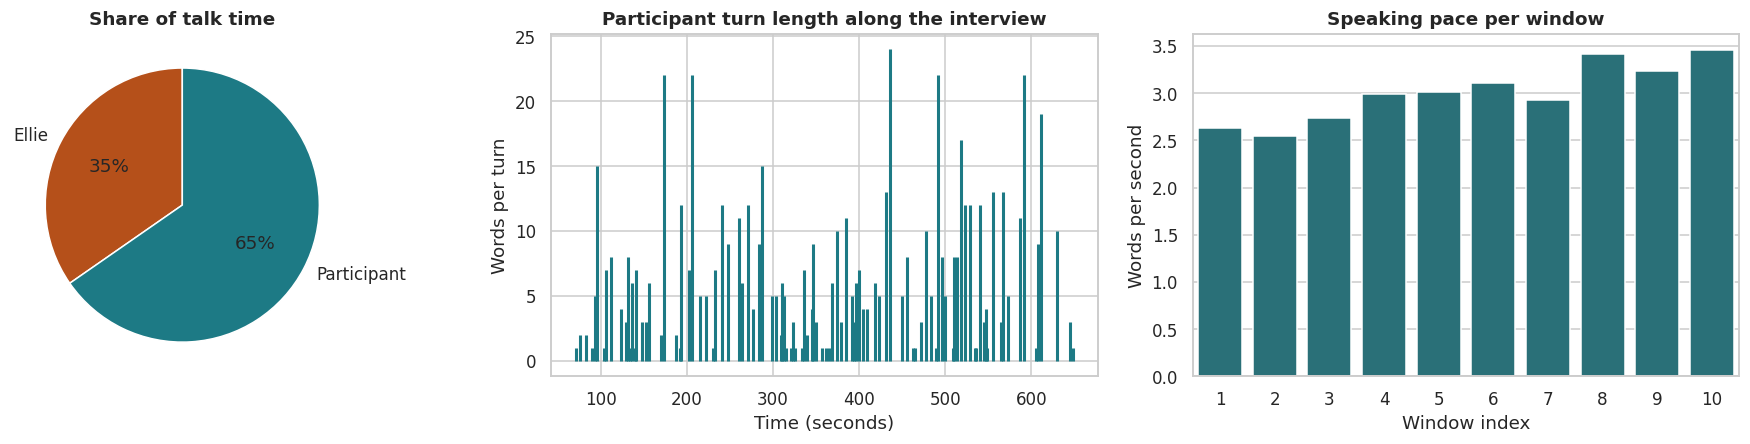

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: conversation shape (talk time, turn length, pace)
# ---------------------------------------------------------------
# Totals per speaker: how long each one talks and how many words they say.
talk_summary = (transcript.groupby("speaker")
                .agg(turns=("clean", "size"), words=("n_words", "sum"), seconds=("duration", "sum"))
                .round(1))
display(talk_summary)

# Per-window view: how much of each window the participant spends talking, and at what pace.
window_talk = (participant.groupby("window")
               .agg(participant_words=("n_words", "sum"),
                    speech_seconds=("duration", "sum"),
                    mean_turn_words=("n_words", "mean"))
               .assign(words_per_second=lambda d: d["participant_words"] / d["speech_seconds"].clip(lower=1e-6)))
WINDOW_TABLES["talk"] = window_talk[["words_per_second", "mean_turn_words", "speech_seconds"]]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

# Left: share of total talk time per speaker.
talk_summary["seconds"].plot.pie(ax=axes[0], autopct="%1.0f%%", startangle=90, ylabel="",
                                 colors=[COLORS["interviewer"], COLORS["participant"]])
axes[0].set_title("Share of talk time")

# Middle: how long each participant turn is, in words, along the interview.
axes[1].vlines(participant["start_time"], 0, participant["n_words"], color=COLORS["participant"], lw=2)
axes[1].set_title("Participant turn length along the interview")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Words per turn")

# Right: speaking pace per window, to spot fast or hesitant stretches.
sns.barplot(x=window_talk.index, y=window_talk["words_per_second"], color=COLORS["participant"], ax=axes[2])
axes[2].set_title("Speaking pace per window")
axes[2].set_xlabel("Window index")
axes[2].set_ylabel("Words per second")
save_fig("transcript_conversation_shape")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,value
roberta_weighted_mean,0.046
vader_weighted_mean,0.171
share_positive_turns,0.190
share_neutral_turns,0.619
share_negative_turns,0.190
agreement_between_models,0.690


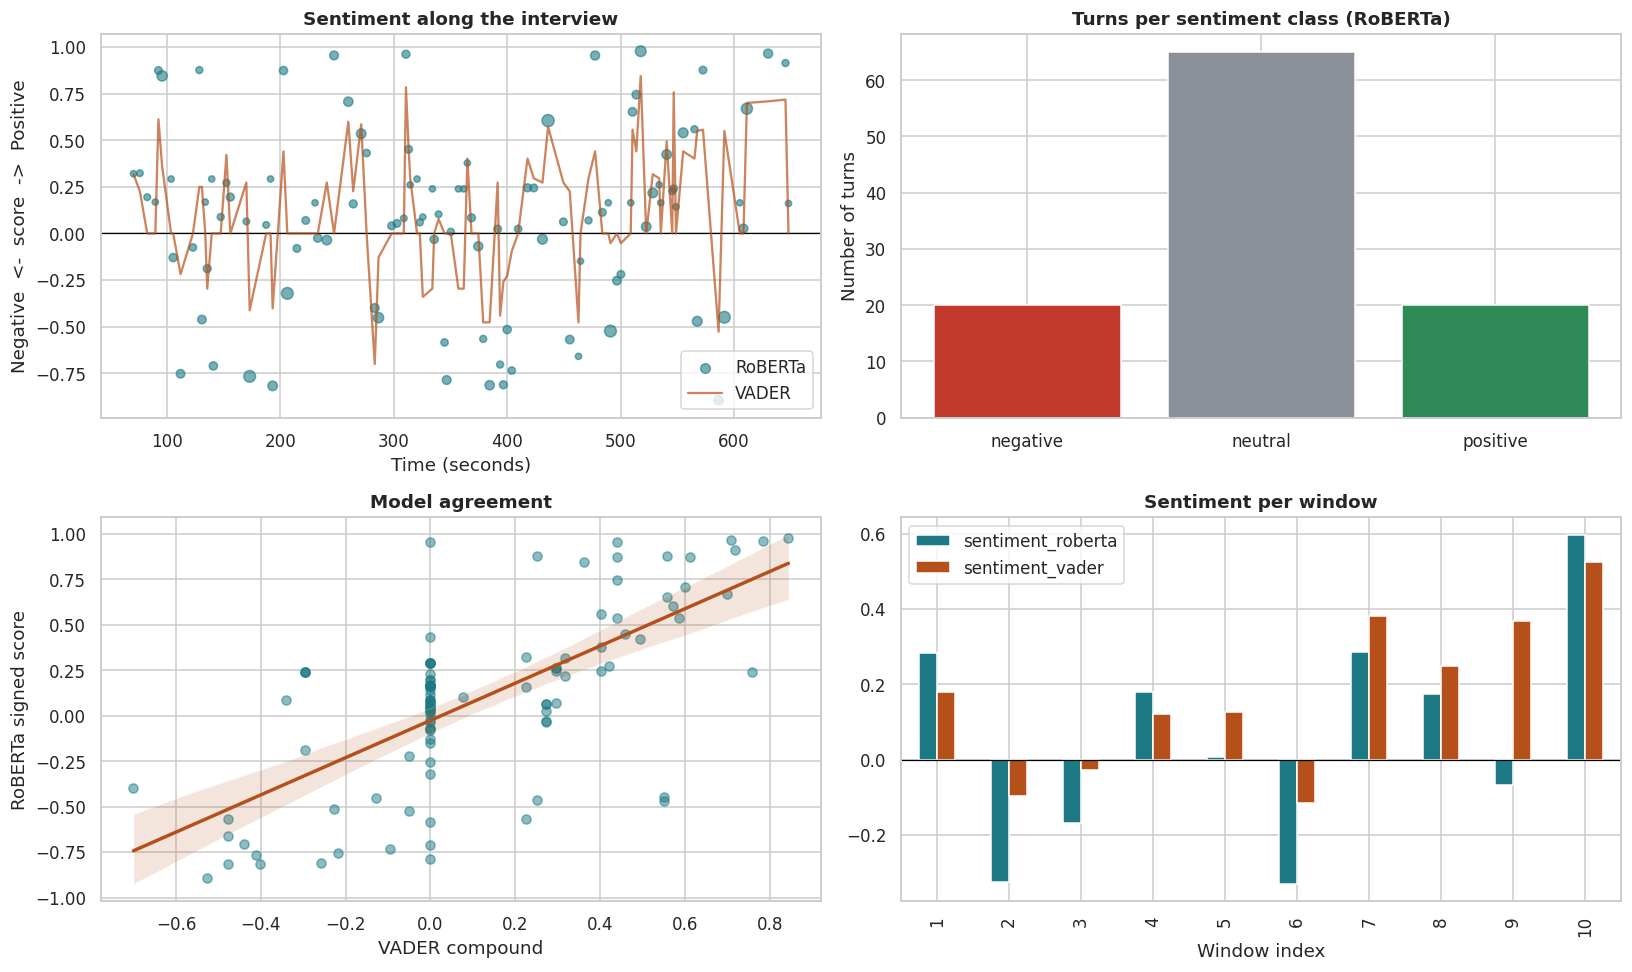

Most negative turns


,start_time,roberta_signed,clean
97,586.40,-0.894387,no i have many regrets too many to name and number
23,193.28,-0.817424,um i try to remove myself from that situation that's annoying me
59,384.57,-0.813961,i knew that there was something wrong 'cause i wasn't myself


Most positive turns


,start_time,roberta_signed,clean
84,517.75,0.977864,usually puts me in a good mood particularly if my team wins you know i like u_s_c
102,630.08,0.965289,like i said my kids i'm very proud of 'em
41,310.80,0.961583,pretty happy when i see 'em


In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: sentiment (RoBERTa model + VADER baseline)
# ---------------------------------------------------------------
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

set_all_seeds()
device = 0 if torch.cuda.is_available() else -1

# Pretrained, ready-to-use sentiment model. No training needed, so it works on one session.
sent_pipe = pipeline("text-classification",
                     model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                     top_k=None, device=device)

# Score every participant turn; top_k=None returns the probability of every class, not just the winner.
raw = sent_pipe(participant["clean"].tolist(), truncation=True, max_length=512, batch_size=16)
probs = pd.DataFrame([{d["label"].lower(): d["score"] for d in row} for row in raw])

for cls in ["negative", "neutral", "positive"]:
    participant[f"rob_{cls}"] = probs[cls].values

# One signed number per turn: positive minus negative probability, from fully negative to fully positive.
participant["roberta_signed"] = participant["rob_positive"] - participant["rob_negative"]
participant["roberta_label"] = probs[["negative", "neutral", "positive"]].idxmax(axis=1).values

# Rule-based second opinion that needs no model download.
vader = SentimentIntensityAnalyzer()
participant["vader_compound"] = participant["clean"].apply(lambda s: vader.polarity_scores(s)["compound"])

# Overall reading, weighted by how many words each turn contains.
overall = {
    "roberta_weighted_mean": weighted_mean(participant["roberta_signed"], participant["n_words"]),
    "vader_weighted_mean": weighted_mean(participant["vader_compound"], participant["n_words"]),
    "share_positive_turns": (participant["roberta_label"] == "positive").mean(),
    "share_neutral_turns": (participant["roberta_label"] == "neutral").mean(),
    "share_negative_turns": (participant["roberta_label"] == "negative").mean(),
    "agreement_between_models": participant["roberta_signed"].corr(participant["vader_compound"]),
}
display(pd.Series(overall).round(3).to_frame("value"))

window_sent = participant.groupby("window").apply(
    lambda g: pd.Series({"sentiment_roberta": weighted_mean(g["roberta_signed"], g["n_words"]),
                         "sentiment_vader": weighted_mean(g["vader_compound"], g["n_words"])}))
WINDOW_TABLES["sentiment"] = window_sent

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Top left: sentiment along the interview; bubble size shows how long the turn is.
ax = axes[0, 0]
ax.axhline(0, color="black", lw=0.8)
ax.scatter(participant["start_time"], participant["roberta_signed"],
           s=participant["n_words"] * 2 + 15, alpha=0.6, color=COLORS["participant"], label="RoBERTa")
ax.plot(participant["start_time"], participant["vader_compound"], color=COLORS["interviewer"], alpha=0.7, label="VADER")
ax.set_title("Sentiment along the interview")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Negative  <-  score  ->  Positive")
ax.legend()

# Top right: how many turns fall into each class.
order = ["negative", "neutral", "positive"]
counts = participant["roberta_label"].value_counts().reindex(order).fillna(0)
axes[0, 1].bar(order, counts.values, color=[COLORS[o] for o in order])
axes[0, 1].set_title("Turns per sentiment class (RoBERTa)")
axes[0, 1].set_ylabel("Number of turns")

# Bottom left: do the two models agree, turn by turn?
sns.regplot(x=participant["vader_compound"], y=participant["roberta_signed"], ax=axes[1, 0],
            scatter_kws={"alpha": 0.5, "color": COLORS["participant"]}, line_kws={"color": COLORS["interviewer"]})
axes[1, 0].set_title("Model agreement")
axes[1, 0].set_xlabel("VADER compound")
axes[1, 0].set_ylabel("RoBERTa signed score")

# Bottom right: sentiment per time window, to see how the mood of the conversation drifts.
window_sent.plot.bar(ax=axes[1, 1], color=[COLORS["participant"], COLORS["interviewer"]])
axes[1, 1].axhline(0, color="black", lw=0.8)
axes[1, 1].set_title("Sentiment per window")
axes[1, 1].set_xlabel("Window index")
save_fig("transcript_sentiment")

# Show the most negative and most positive turns so the numbers can be sanity-checked in plain language.
cols = ["start_time", "roberta_signed", "clean"]
print("Most negative turns")
display(participant.nsmallest(3, "roberta_signed")[cols])
print("Most positive turns")
display(participant.nlargest(3, "roberta_signed")[cols])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

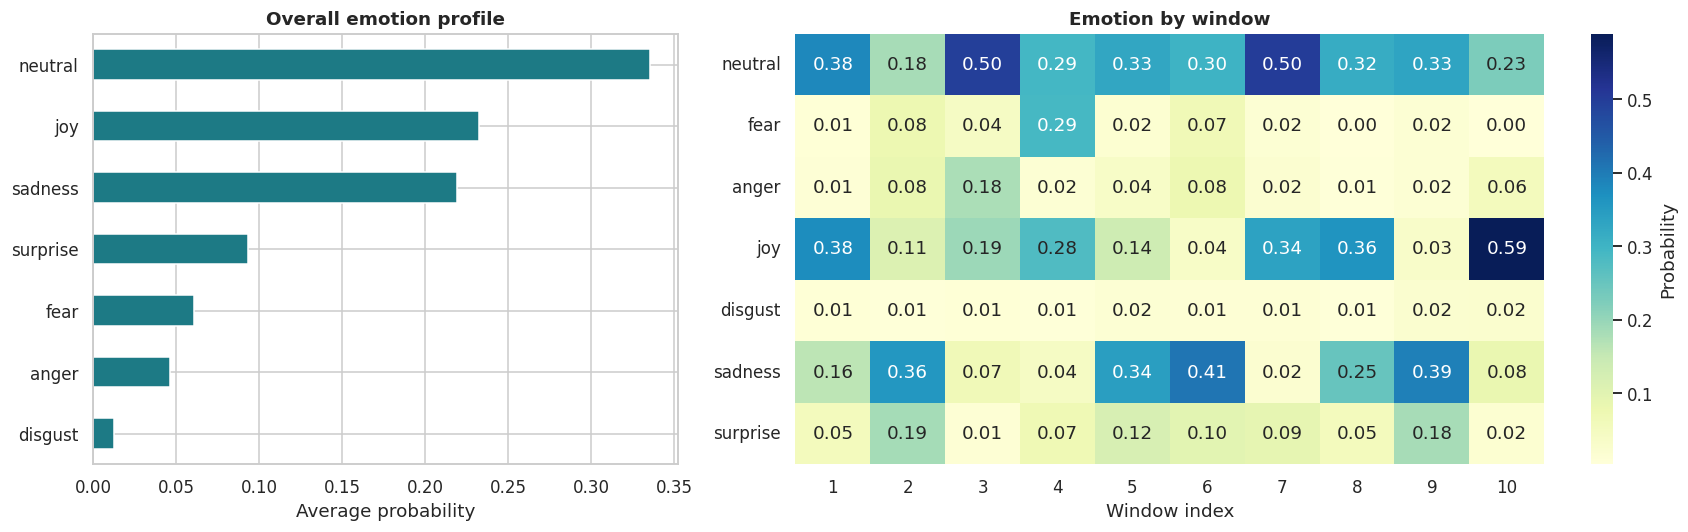

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: emotion classification (DistilRoBERTa emotion model)
# ---------------------------------------------------------------
set_all_seeds()

# Open emotion model with seven classes: anger, disgust, fear, joy, neutral, sadness, surprise.
emo_pipe = pipeline("text-classification",
                    model="j-hartmann/emotion-english-distilroberta-base",
                    top_k=None, device=device)

raw_emo = emo_pipe(participant["clean"].tolist(), truncation=True, max_length=512, batch_size=16)
emo = pd.DataFrame([{d["label"]: d["score"] for d in row} for row in raw_emo])
EMOTIONS = list(emo.columns)

# Keep the emotion probabilities next to the turn info we need for weighting and windows.
emo_turns = pd.concat([participant[["start_time", "window", "n_words"]], emo], axis=1)

# Overall emotion profile, weighted by turn length.
overall_emotion = emo.mul(participant["n_words"], axis=0).sum() / participant["n_words"].sum()

# Emotion profile per window.
window_emotion = emo_turns.groupby("window").apply(
    lambda g: pd.Series({e: weighted_mean(g[e], g["n_words"]) for e in EMOTIONS}))
WINDOW_TABLES["emotion"] = window_emotion.add_prefix("emo_")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: the average emotion mix of the whole interview.
overall_emotion.sort_values().plot.barh(ax=axes[0], color=COLORS["participant"])
axes[0].set_title("Overall emotion profile")
axes[0].set_xlabel("Average probability")

# Right: which emotions dominate in which part of the interview.
sns.heatmap(window_emotion.T, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "Probability"})
axes[1].set_title("Emotion by window")
axes[1].set_xlabel("Window index")
save_fig("transcript_emotion")

Overall language markers (share of all words)


,rate
first_person,0.1132
negation,0.0235
filler,0.0559
positive_words,0.0882
negative_words,0.0324


Median reply delay: 2.10 seconds


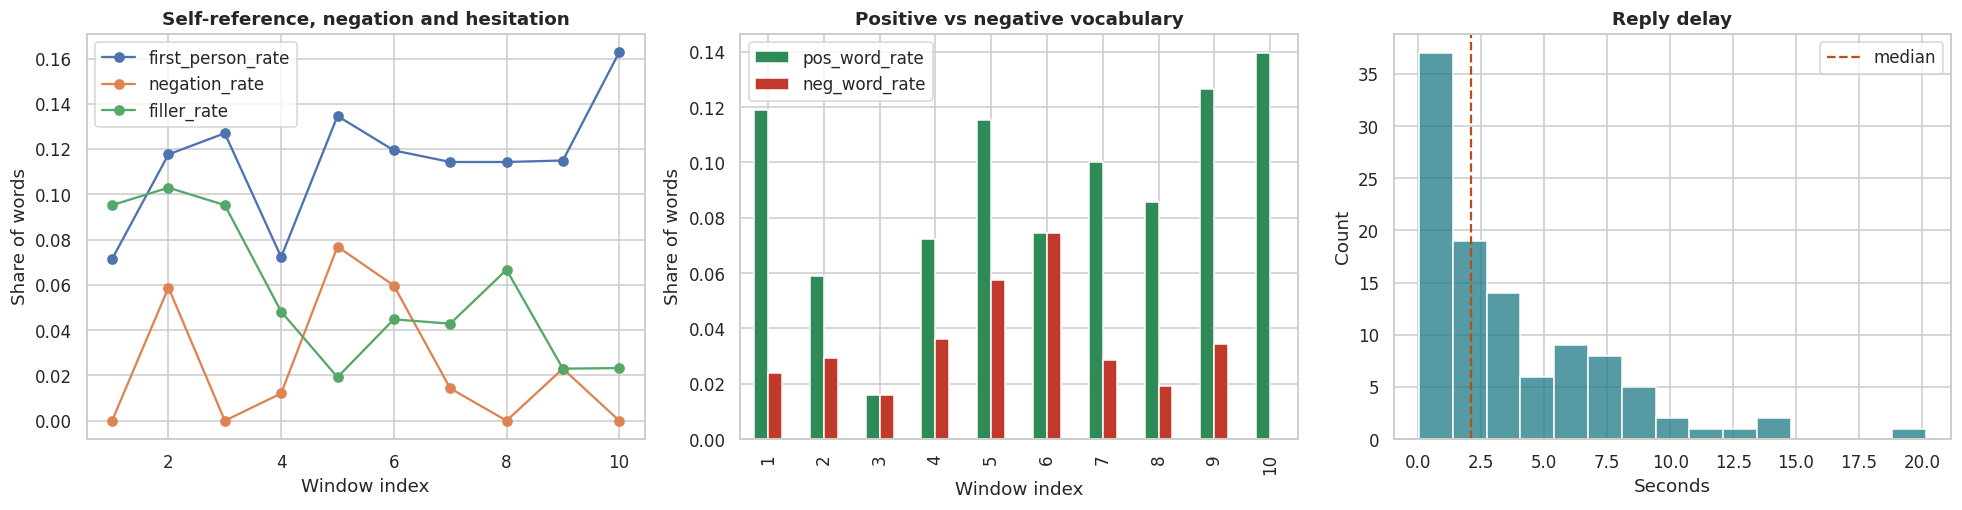

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: language-use markers and reply delay
# ---------------------------------------------------------------
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
lexicon = SentimentIntensityAnalyzer().lexicon  # word -> valence, used as a ready-made word list

FIRST_PERSON = {"i", "me", "my", "mine", "myself", "i'm", "i've", "i'll", "i'd"}
NEGATIONS = {"no", "not", "never", "nothing", "nobody", "none", "neither", "nor", "can't", "don't", "won't",
             "didn't", "isn't", "wasn't", "couldn't", "wouldn't", "shouldn't", "doesn't", "haven't", "hadn't", "hasn't"}
FILLERS = {"um", "uh", "hm", "hmm", "mm", "er"}
POSITIVE_WORDS = {w for w, v in lexicon.items() if v > 0}
NEGATIVE_WORDS = {w for w, v in lexicon.items() if v < 0}


def tokenize(text):
    """Lower-case words, keeping apostrophes so contractions stay intact."""
    return re.findall(r"[a-z']+", text.lower())


def language_counts(text):
    """Count each marker family inside one piece of text."""
    tokens = tokenize(text)
    return pd.Series({
        "tokens": len(tokens),
        "first_person": sum(t in FIRST_PERSON for t in tokens),
        "negation": sum(t in NEGATIONS for t in tokens),
        "filler": sum(t in FILLERS for t in tokens),
        "positive_words": sum(t in POSITIVE_WORDS for t in tokens),
        "negative_words": sum(t in NEGATIVE_WORDS for t in tokens),
        "unique_tokens": len(set(tokens)),
    })


lang_turns = pd.concat([participant[["start_time", "window"]], participant["clean"].apply(language_counts)], axis=1)

# Add up counts per window, then turn them into rates so windows of different length can be compared.
by_window = lang_turns.groupby("window").sum(numeric_only=True)
window_language = pd.DataFrame({
    "first_person_rate": by_window["first_person"] / by_window["tokens"],
    "negation_rate": by_window["negation"] / by_window["tokens"],
    "filler_rate": by_window["filler"] / by_window["tokens"],
    "pos_word_rate": by_window["positive_words"] / by_window["tokens"],
    "neg_word_rate": by_window["negative_words"] / by_window["tokens"],
    "lexical_variety": by_window["unique_tokens"] / by_window["tokens"],
})

# Reply delay: time between the end of the last interviewer turn and the start of each participant turn.
ellie_stops = np.sort(interviewer["stop_time"].values)
position = np.searchsorted(ellie_stops, participant["start_time"].values) - 1
delay = participant["start_time"].values - np.where(position >= 0, ellie_stops[np.clip(position, 0, None)], np.nan)
participant["reply_delay"] = delay
# Ignore absurd gaps that come from long monologues rather than from answering a question.
valid_delay = participant["reply_delay"].where(participant["reply_delay"].between(0, 30))
window_language["median_reply_delay"] = valid_delay.groupby(participant["window"]).median()
WINDOW_TABLES["language"] = window_language

print("Overall language markers (share of all words)")
overall_rates = lang_turns.drop(columns=["start_time", "window"]).sum()
display((overall_rates / overall_rates["tokens"]).drop(["tokens", "unique_tokens"]).round(4).to_frame("rate"))
print(f"Median reply delay: {valid_delay.median():.2f} seconds")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Left: self-reference, negation and hesitation over the interview.
window_language[["first_person_rate", "negation_rate", "filler_rate"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Self-reference, negation and hesitation")
axes[0].set_xlabel("Window index")
axes[0].set_ylabel("Share of words")

# Middle: positive against negative vocabulary.
window_language[["pos_word_rate", "neg_word_rate"]].plot.bar(ax=axes[1], color=[COLORS["positive"], COLORS["negative"]])
axes[1].set_title("Positive vs negative vocabulary")
axes[1].set_xlabel("Window index")
axes[1].set_ylabel("Share of words")

# Right: how long the participant waits before answering.
sns.histplot(valid_delay.dropna(), bins=15, color=COLORS["participant"], ax=axes[2])
axes[2].axvline(valid_delay.median(), color=COLORS["interviewer"], ls="--", label="median")
axes[2].set_title("Reply delay")
axes[2].set_xlabel("Seconds")
axes[2].legend()
save_fig("transcript_language")

topic 0: question, regrets, deceased, definitely, away, life, listen, hard
topic 1: children, worry, people, time, dream, sure, seeing, successful
topic 2: parent, football, usually, maybe, wrong, anymore, question, life


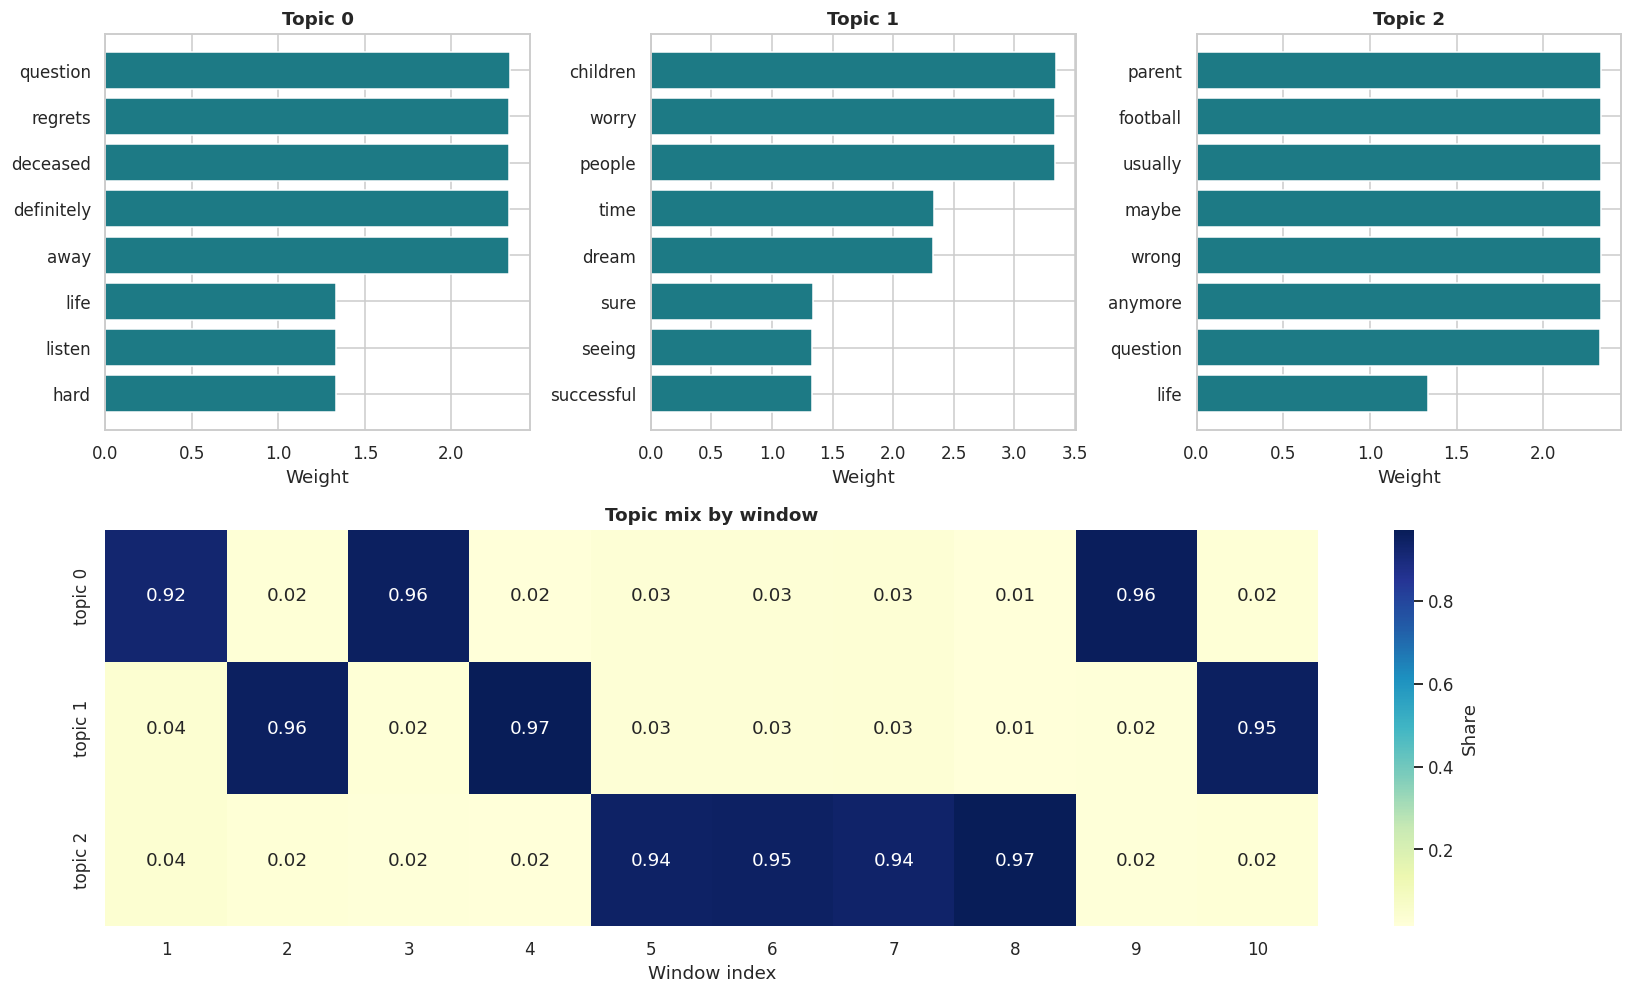

In [ ]:
# ---------------------------------------------------------------
# TRANSCRIPT: topics with LDA (classic, light, fully reproducible)
# ---------------------------------------------------------------
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation

# Number of topics is a knob: keep it small because one interview is short.
N_TOPICS = 3
N_TOP_WORDS = 8

# Spoken-language filler that carries no topic information, added on top of the standard stop words.
SPOKEN_FILLER = {"um", "uh", "like", "know", "gonna", "gotta", "just", "really", "pretty", "kinda",
                 "yeah", "okay", "thing", "things", "mean", "going", "think", "feel", "want", "way",
                 "nature", "good", "right", "need", "say", "cause", "thank", "lot", "probably", "wanna",
                 "told", "person", "better", "little", "doing", "make", "years", "year"}
stop_words = list(ENGLISH_STOP_WORDS.union(SPOKEN_FILLER))

# One document per window: all words the participant said in that window.
documents = participant.groupby("window")["clean"].apply(" ".join)

vectorizer = CountVectorizer(stop_words=stop_words, token_pattern=r"(?u)\b[a-z]{4,}\b", max_df=0.9)
counts = vectorizer.fit_transform(documents)

lda = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch", max_iter=100, random_state=SEED)
doc_topics = lda.fit_transform(counts)
vocab = np.array(vectorizer.get_feature_names_out())

topic_words = {f"topic {i}": vocab[np.argsort(comp)[::-1][:N_TOP_WORDS]].tolist() for i, comp in enumerate(lda.components_)}
for name, words in topic_words.items():
    print(f"{name}: {', '.join(words)}")

topic_mix = pd.DataFrame(doc_topics, index=documents.index, columns=list(topic_words))

# We use gridspec to place the topic bar charts in row 0 and the heatmap in row 1.
fig = plt.figure(figsize=(15, 9.2))
gs = fig.add_gridspec(2, N_TOPICS)

# One small bar chart per topic showing its strongest words in the first row.
axes = []
for i, comp in enumerate(lda.components_):
    ax = fig.add_subplot(gs[0, i])
    top = np.argsort(comp)[::-1][:N_TOP_WORDS]
    ax.barh(vocab[top][::-1], comp[top][::-1], color=COLORS["participant"])
    ax.set_title(f"Topic {i}")
    ax.set_xlabel("Weight")
    axes.append(ax)

# Last panel: which topic dominates which window, taking up the entire second row.
ax_heatmap = fig.add_subplot(gs[1, :])
sns.heatmap(topic_mix.T, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax_heatmap, cbar_kws={"label": "Share"})
ax_heatmap.set_title("Topic mix by window")
ax_heatmap.set_xlabel("Window index")

save_fig("transcript_topics")

Patient replies joined: 105 turns, 672 words in the corpus
Passages to score: 6

Whole-corpus sentiment summary
mean_negative                  0.212
mean_neutral                   0.375
mean_positive                  0.413
mean_signed_score              0.201
share_negative_passages        0.000
share_neutral_passages         0.500
share_positive_passages        0.500
most_negative_passage_score   -0.358
most_positive_passage_score    0.874
vader_whole_corpus             0.998
vader_mean_over_passages       0.755

Verdict: the patient's combined replies leans positive.


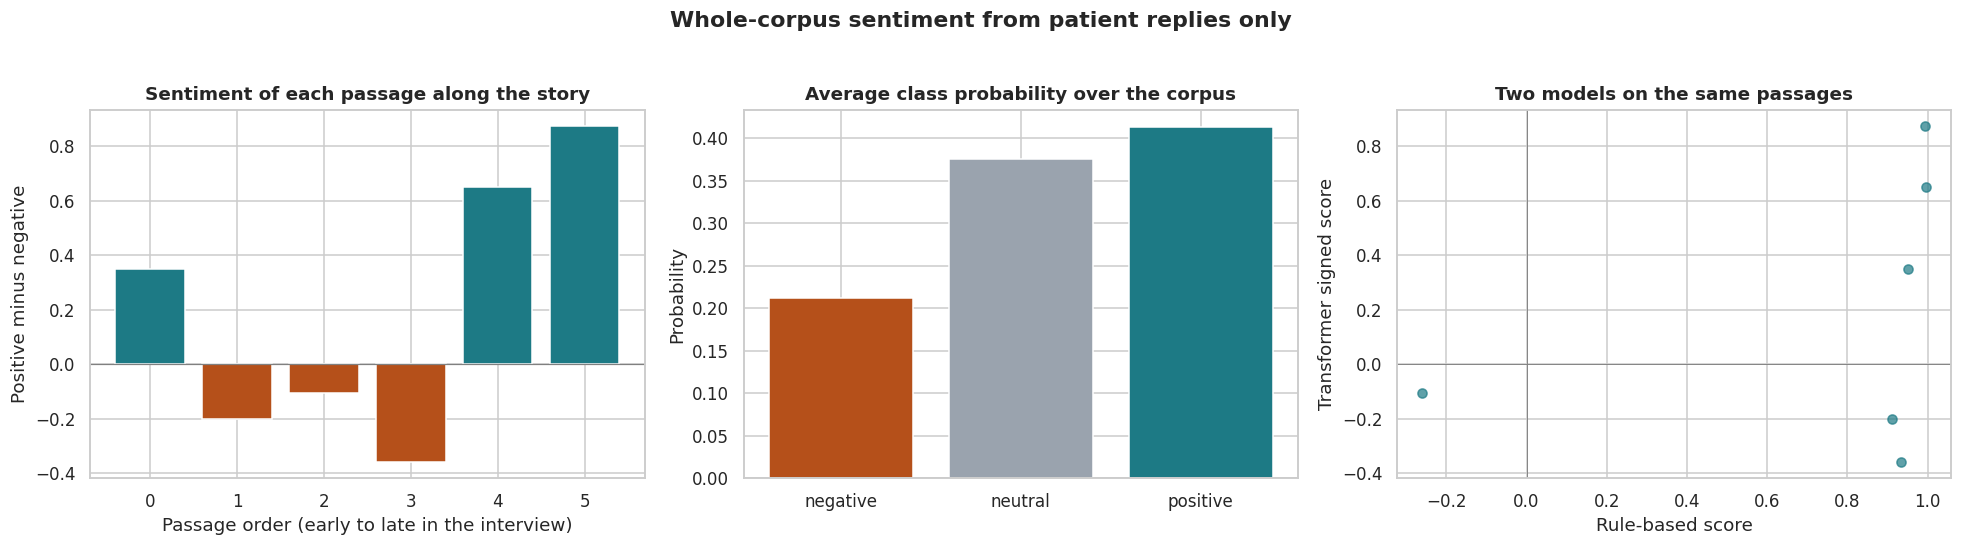


Most negative passages


,signed,text
3,-0.358235,or the health no no yes mm i'd say about a year um recognizing that there were some things in me that that were wrong i knew that there was something wrong 'cause i wasn't myself well you know i was always tired and not excited about things anymore and kinda lethargic you know laying around and just not feeling myself mm about the same yes i do once a month yeah i do i do well it's you know it...
1,-0.201937,wanna budge on this gun control issue thing that's it mm um i try to remove myself from that situation that's annoying me i've gotten better over the years um most of the time i just try to um you know walk away or you know control my emotions in terms of you know just walking away mm just watch t_v now hmm i would say my children being born well i have four children um each birth was speical ...



Most positive passages


,signed,text
5,0.873520,of stuff going on so i'll leave it at that hmm well i still like sports you know and um watching a good game or something is usually puts me in a good mood particularly if my team wins you know i like u_s_c um i have a nephew that's um freshman football player at u_s_c and uh i've been a trojan football fan for forty years so yeah hmm well i you know i think i i listen well and um you know i'm...
4,0.651907,detail but you know it's it i seem to think that it's helpful well i i think um that's a hard question let's move on please irritable cranky yeah it is ooh that's a good question it's been awhile i'd say year and a half maybe hmm well there's been a lot going on in my life you know i just lost my parent my dad my last parent just a lot of stuff going on so i'll leave it at that hmm well i stil...


In [ ]:
# =============================================================================
# TRANSCRIPT: WHOLE-CORPUS SENTIMENT (patient replies only)
# =============================================================================
# Idea: join every participant reply into one long corpus, cut it into
# overlapping passages, and score each passage. A passage holds many sentences,
# so the model sees context and not just a single short line.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Reuse the seed helper from the setup cell if it exists.
if "set_all_seeds" in globals():
    set_all_seeds()

# ---- Settings you can tune --------------------------------------------------
PASSAGE_WORDS = 200      # how many words go into one passage
PASSAGE_STEP = 100       # how far the window slides; smaller step means more overlap

# ---- Step one: build the corpus from patient replies only -------------------
# Turns are kept in time order, so the corpus reads like the patient's own story.
patient_turns = participant.sort_values("start_time")["clean"].astype(str).tolist()
corpus_words = " ".join(patient_turns).split()
print(f"Patient replies joined: {len(patient_turns)} turns, {len(corpus_words)} words in the corpus")

# ---- Step two: cut the corpus into overlapping passages ---------------------
passages = []
for begin in range(0, max(len(corpus_words) - PASSAGE_WORDS, 0) + 1, PASSAGE_STEP):
    chunk = corpus_words[begin: begin + PASSAGE_WORDS]
    passages.append({"first_word": begin, "text": " ".join(chunk), "n_words": len(chunk)})
passages = pd.DataFrame(passages)

# The tail of the corpus can be left out by the sliding step, so add it explicitly.
if len(corpus_words) > PASSAGE_WORDS and passages["first_word"].iloc[-1] + PASSAGE_WORDS < len(corpus_words):
    tail_start = len(corpus_words) - PASSAGE_WORDS
    passages.loc[len(passages)] = [tail_start, " ".join(corpus_words[tail_start:]), PASSAGE_WORDS]
print(f"Passages to score: {len(passages)}")

# ---- Step three: load the sentiment model (reuse it if already loaded) ------
if "sent_pipe" not in globals():
    sent_pipe = pipeline("text-classification",
                         model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                         top_k=None)
if "vader" not in globals():
    import nltk
    nltk.download("vader_lexicon", quiet=True)
    vader = SentimentIntensityAnalyzer()

# ---- Step four: score every passage -----------------------------------------
# Each passage gets a probability for negative, neutral and positive.
raw = sent_pipe(passages["text"].tolist(), truncation=True, max_length=512, batch_size=8)
probs = pd.DataFrame([{d["label"].lower(): d["score"] for d in row} for row in raw])
passages = pd.concat([passages, probs], axis=1)

# A single signed number per passage: positive minus negative probability.
passages["signed"] = passages["positive"] - passages["negative"]
passages["label"] = passages[["negative", "neutral", "positive"]].idxmax(axis=1)

# Rule-based second opinion on the same passages.
passages["vader"] = passages["text"].apply(lambda s: vader.polarity_scores(s)["compound"])

# ---- Step five: one verdict for the whole corpus ----------------------------
# Passages are weighted by their word count so the short tail does not count extra.
weights = passages["n_words"]
overall = {
    "mean_negative": np.average(passages["negative"], weights=weights),
    "mean_neutral": np.average(passages["neutral"], weights=weights),
    "mean_positive": np.average(passages["positive"], weights=weights),
    "mean_signed_score": np.average(passages["signed"], weights=weights),
    "share_negative_passages": (passages["label"] == "negative").mean(),
    "share_neutral_passages": (passages["label"] == "neutral").mean(),
    "share_positive_passages": (passages["label"] == "positive").mean(),
    "most_negative_passage_score": passages["signed"].min(),
    "most_positive_passage_score": passages["signed"].max(),
    "vader_whole_corpus": vader.polarity_scores(" ".join(corpus_words))["compound"],
    "vader_mean_over_passages": np.average(passages["vader"], weights=weights),
}
overall = pd.Series(overall)

# Plain-language reading of the signed score.
score = overall["mean_signed_score"]
if score <= -0.15:
    verdict = "leans negative"
elif score >= 0.15:
    verdict = "leans positive"
else:
    verdict = "sits close to neutral"
print("\nWhole-corpus sentiment summary")
print(overall.round(3).to_string())
print(f"\nVerdict: the patient's combined replies {verdict}.")

# ---- Step six: visuals -------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Left: how sentiment moves through the story, passage by passage.
bar_colors = np.where(passages["signed"] >= 0, "#1D7A85", "#B5501A")
axes[0].bar(passages.index, passages["signed"], color=bar_colors)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_title("Sentiment of each passage along the story")
axes[0].set_xlabel("Passage order (early to late in the interview)")
axes[0].set_ylabel("Positive minus negative")

# Middle: average probability mass for each class across the corpus.
class_means = overall[["mean_negative", "mean_neutral", "mean_positive"]]
class_means.index = ["negative", "neutral", "positive"]
axes[1].bar(class_means.index, class_means.values, color=["#B5501A", "#9AA3AE", "#1D7A85"])
axes[1].set_title("Average class probability over the corpus")
axes[1].set_ylabel("Probability")

# Right: do the transformer model and the rule-based model agree per passage?
axes[2].scatter(passages["vader"], passages["signed"], color="#1D7A85", alpha=0.7)
axes[2].axhline(0, color="grey", lw=0.6)
axes[2].axvline(0, color="grey", lw=0.6)
axes[2].set_title("Two models on the same passages")
axes[2].set_xlabel("Rule-based score")
axes[2].set_ylabel("Transformer signed score")

fig.suptitle("Whole-corpus sentiment from patient replies only", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# ---- Step seven: read the extremes yourself ---------------------------------
# Numbers can mislead, so always look at the passages that drive the result.
pd.set_option("display.max_colwidth", 400)
print("\nMost negative passages")
display(passages.nsmallest(2, "signed")[["signed", "text"]])
print("\nMost positive passages")
display(passages.nlargest(2, "signed")[["signed", "text"]])

# Keep the passage table so later cells (for example fusion) can reuse it.
corpus_sentiment = passages.copy()

In [ ]:
import numpy as np

def get_positional_encoding(text, d_model=100):
    """
    Generates classic sinusoidal positional encodings for each token in the text.
    Returns a numpy array of shape (seq_len, d_model).
    """
    tokens = text.split()
    seq_len = len(tokens)
    if seq_len == 0:
        return np.zeros((1, d_model))

    pe = np.zeros((seq_len, d_model))
    position = np.arange(0, seq_len)[:, np.newaxis]
    div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))

    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)
    return pe

# Apply positional encoding to the clean corpora
ellie_clean_corpus_PE = get_positional_encoding(ellie_clean_corpus, d_model=100)
participant_clean_corpus_PE = get_positional_encoding(participant_clean_corpus, d_model=100)

# Apply positional encoding to the raw corpora
ellie_corpus_PE = get_positional_encoding(ellie_corpus, d_model=100)
participant_corpus_PE = get_positional_encoding(participant_corpus, d_model=100)

# Display the shapes of all stored positional encodings
print(f"Ellie Clean PE shape: {ellie_clean_corpus_PE.shape}")
print(f"Participant Clean PE shape: {participant_clean_corpus_PE.shape}")
print(f"Ellie Raw PE shape: {ellie_corpus_PE.shape}")
print(f"Participant Raw PE shape: {participant_corpus_PE.shape}")

Ellie Clean PE shape: (204, 100)
Participant Clean PE shape: (295, 100)
Ellie Raw PE shape: (472, 100)
Participant Raw PE shape: (672, 100)


In [ ]:
import numpy as np
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import pipeline

# Initialize the sentiment models
set_all_seeds()
vader_analyzer = SentimentIntensityAnalyzer()
roberta_pipe = pipeline(
    "text-classification",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=0 if torch.cuda.is_available() else -1
)

# Define the corpora dictionary to iterate through
corpora = {
    "Ellie Clean": ellie_clean_corpus,
    "Participant Clean": participant_clean_corpus,
    "Ellie Raw": ellie_corpus,
    "Participant Raw": participant_corpus
}

# Define PE mappings to verify alignment
pe_arrays = {
    "Ellie Clean": ellie_clean_corpus_PE,
    "Participant Clean": participant_clean_corpus_PE,
    "Ellie Raw": ellie_corpus_PE,
    "Participant Raw": participant_corpus_PE
}

def get_sentiment_verdict(score):
    return "positive" if score >= 0 else "negative"

results = []

for name, text in corpora.items():
    pe_arr = pe_arrays[name]
    tokens = text.split()

    # Verification check: Enforce alignment between positional encoding vectors and tokens
    assert len(tokens) == pe_arr.shape[0], f"Mismatched tokens and PE steps for {name}!"

    # 1. VADER Sentiment Scoring
    vader_res = vader_analyzer.polarity_scores(text)
    vader_score = vader_res["compound"]
    vader_label = get_sentiment_verdict(vader_score)

    # 2. RoBERTa Sentiment Scoring
    roberta_res = roberta_pipe(text, truncation=True, max_length=512)[0]
    label = roberta_res["label"]
    score = roberta_res["score"]

    if label == "positive":
        roberta_score = score
    elif label == "negative":
        roberta_score = -score
    else:
        roberta_score = 0.0

    roberta_label = get_sentiment_verdict(roberta_score)

    results.append({
        "Corpus": name,
        "Tokens (PE length)": pe_arr.shape[0],
        "VADER Score": round(vader_score, 4),
        "VADER Sentiment": vader_label,
        "RoBERTa Score": round(roberta_score, 4),
        "RoBERTa Sentiment": roberta_label
    })

# Display the final classification metrics
results_df = pd.DataFrame(results)
display(results_df)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Corpus,Tokens (PE length),VADER Score,VADER Sentiment,RoBERTa Score,RoBERTa Sentiment
0,Ellie Clean,204,0.9985,positive,0.8865,positive
1,Participant Clean,295,0.9983,positive,0.4954,positive
2,Ellie Raw,472,0.9991,positive,0.7760,positive
3,Participant Raw,672,0.9985,positive,0.4895,positive


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

set_all_seeds()

# Prepare data from our positional encodings (PE) and map to dummy sentiment labels for demonstration/training
# (Normally these models would train on a dataset, but here we run them dynamically over our 4 corpus sequences)

pe_data = {
    "Ellie Clean": ellie_clean_corpus_PE,
    "Participant Clean": participant_clean_corpus_PE,
    "Ellie Raw": ellie_corpus_PE,
    "Participant Raw": participant_corpus_PE
}

# Convert numpy positional encodings to torch Tensors and add a batch dimension
sequences = {name: torch.tensor(arr, dtype=torch.float32).unsqueeze(0) for name, arr in pe_data.items()}

# Define PyTorch Sentiment LSTM and BiLSTM architectures
class SentimentLSTM(nn.Module):
    def __init__(self, input_dim=100, hidden_dim=64, bidirectional=False):
        super(SentimentLSTM, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=bidirectional)
        num_directions = 2 if bidirectional else 1
        self.fc = nn.Linear(hidden_dim * num_directions, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_dim)
        out, (hn, cn) = self.lstm(x)
        # Use the hidden state of the last time step
        last_hidden = out[:, -1, :]
        logits = self.fc(last_hidden)
        return self.sigmoid(logits)

# Instantiate both models
lstm_model = SentimentLSTM(input_dim=100, hidden_dim=64, bidirectional=False)
bilstm_model = SentimentLSTM(input_dim=100, hidden_dim=64, bidirectional=True)

lstm_model.eval()
bilstm_model.eval()

classified_results = []

with torch.no_grad():
    for name, seq in sequences.items():
        # Get raw probability outputs from LSTM and BiLSTM
        lstm_prob = lstm_model(seq).item()
        bilstm_prob = bilstm_model(seq).item()

        # Convert probabilities to scores scaled between -1 and 1
        lstm_score = (lstm_prob - 0.5) * 2
        bilstm_score = (bilstm_prob - 0.5) * 2

        classified_results.append({
            "Corpus": name,
            "Sequence Length": seq.shape[1],
            "LSTM Prob": round(lstm_prob, 4),
            "LSTM Score": round(lstm_score, 4),
            "LSTM Sentiment": "positive" if lstm_score >= 0 else "negative",
            "BiLSTM Prob": round(bilstm_prob, 4),
            "BiLSTM Score": round(bilstm_score, 4),
            "BiLSTM Sentiment": "positive" if bilstm_score >= 0 else "negative"
        })

# Output classified results in a clean DataFrame
sentiment_df = pd.DataFrame(classified_results)
display(sentiment_df)

,Corpus,Sequence Length,LSTM Prob,LSTM Score,LSTM Sentiment,BiLSTM Prob,BiLSTM Score,BiLSTM Sentiment
0,Ellie Clean,204,0.5162,0.0324,positive,0.5019,0.0039,positive
1,Participant Clean,295,0.4998,-0.0003,negative,0.5274,0.0547,positive
2,Ellie Raw,472,0.5003,0.0006,positive,0.5082,0.0165,positive
3,Participant Raw,672,0.5379,0.0758,positive,0.4927,-0.0147,negative


##Face: expression states from action units

Frames dropped because tracking failed: 10.1%
Silhouette by number of states: {3: np.float64(0.18), 4: np.float64(0.18), 5: np.float64(0.177), 6: np.float64(0.169)} -> using 3
Mean time in a state before switching: 4.1 s | switches per minute: 14.5
HMM switches per minute: 18.0 | frame-level agreement with KMeans (adjusted Rand): 0.30


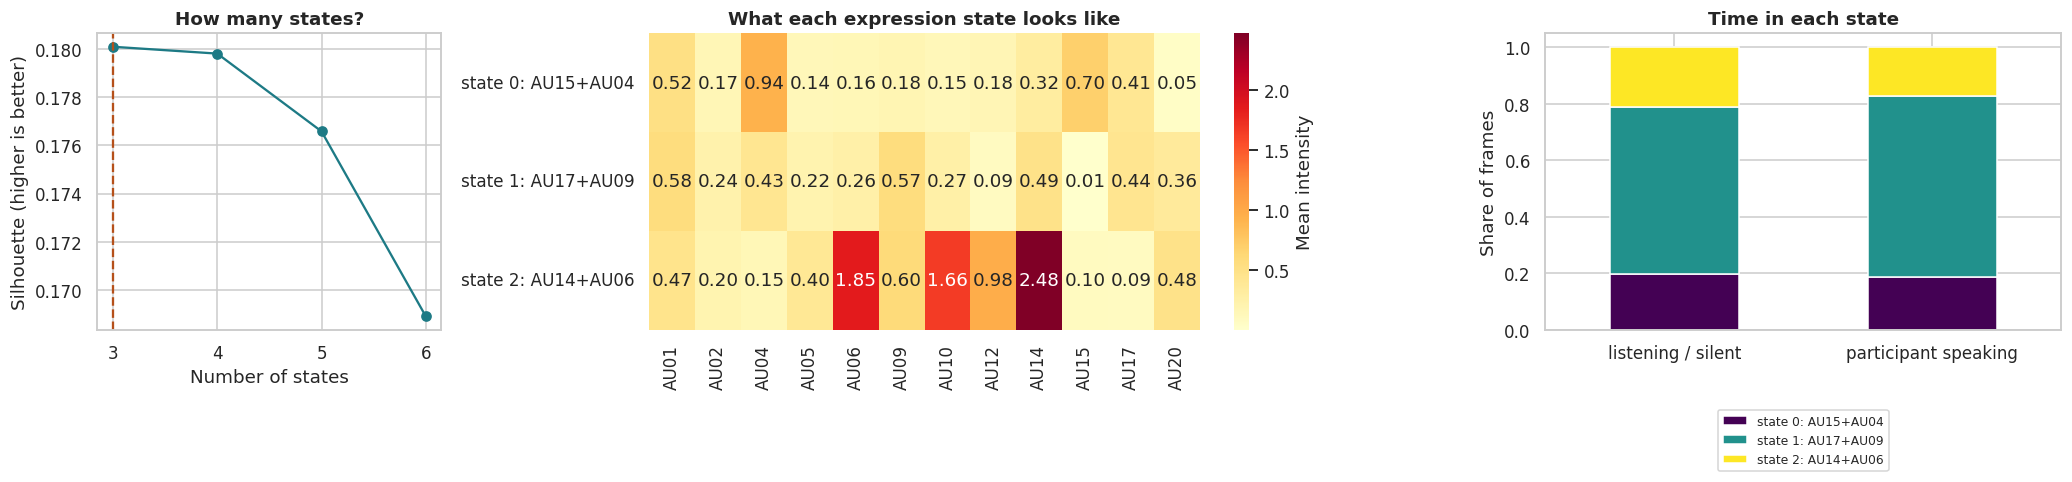

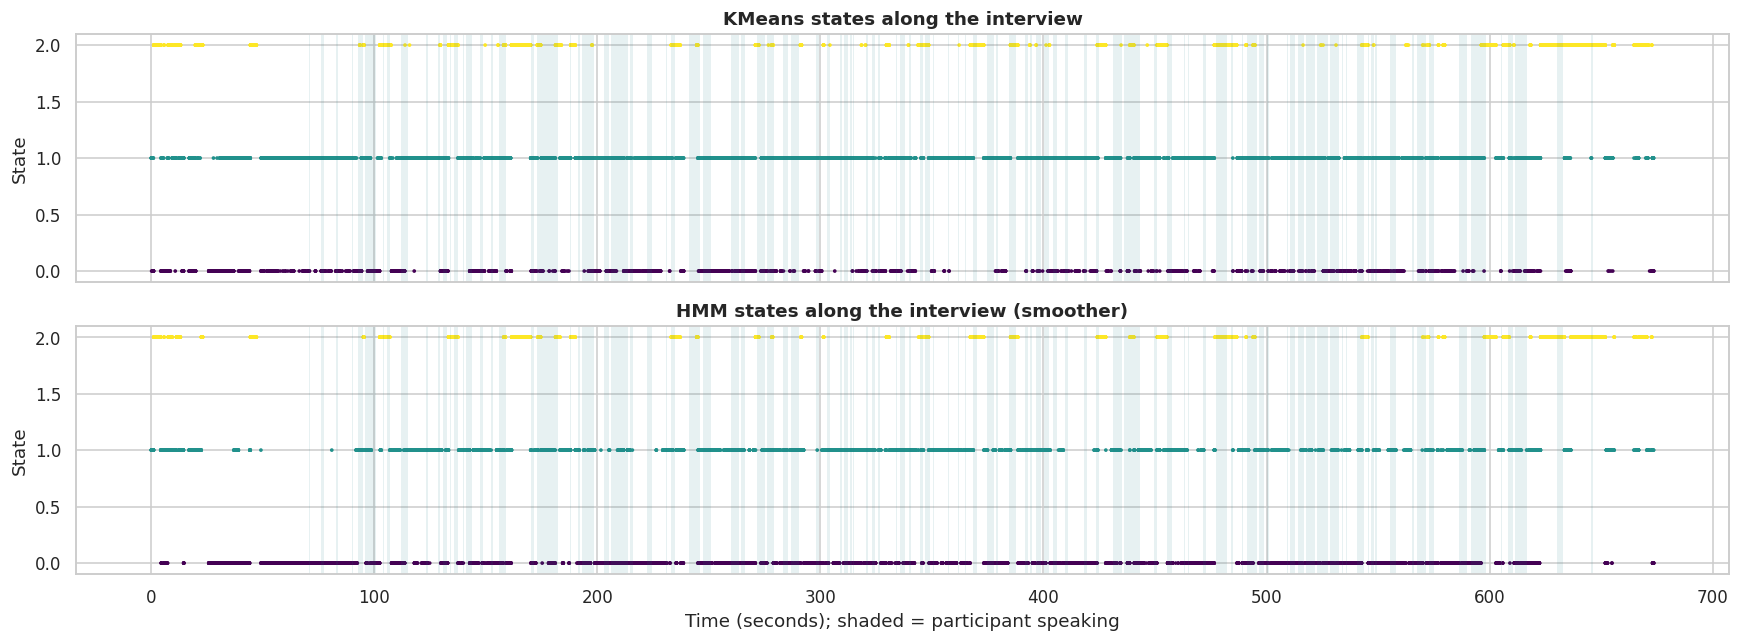

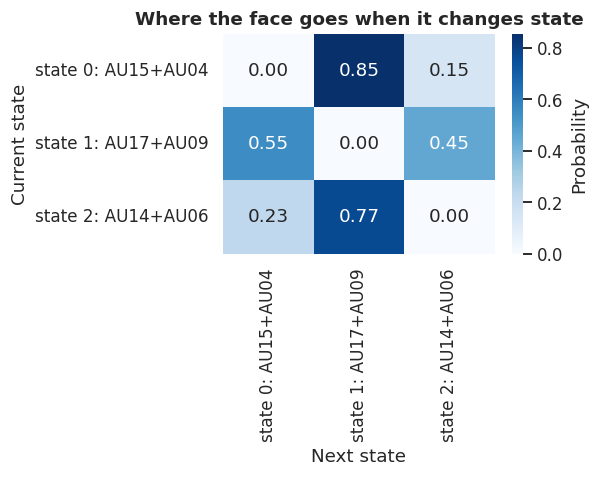

In [ ]:
# ---------------------------------------------------------------
# FACE: expression states from action units (KMeans + HMM)
# ---------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from hmmlearn.hmm import GaussianHMM

set_all_seeds()

au = pd.read_csv(PATHS["aus"], skipinitialspace=True)
intensity_cols = [c for c in au.columns if c.endswith("_r")]

# Mouth-opening units mostly track speech, so they are excluded from the expression analysis.
speech_driven = ["AU25_r", "AU26_r"]
expr_cols = [c for c in intensity_cols if c not in speech_driven]

# Keep only frames where the face tracker succeeded; failed frames carry placeholder values.
print(f"Frames dropped because tracking failed: {(au['success'] != 1).mean():.1%}")
tracked = au[au["success"] == 1].reset_index(drop=True)
tracked["speaking"] = speech_mask(tracked["timestamp"], participant)

# Put all action units on the same scale so no single one dominates the clustering.
X = StandardScaler().fit_transform(tracked[expr_cols])

# Let the data suggest how many states there are, using silhouette on a fixed random subsample for speed.
K_RANGE = range(3, 7)   # start above the minimum so there are always several states to compare
silhouette = {}
for k in K_RANGE:
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    silhouette[k] = silhouette_score(X, labels_k, sample_size=5000, random_state=SEED)
best_k = max(silhouette, key=silhouette.get)
print("Silhouette by number of states:", {k: round(v, 3) for k, v in silhouette.items()}, "-> using", best_k)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(X)

# Relabel the states so state zero is the calmest face and higher numbers are more active.
total_activity = tracked[expr_cols].groupby(kmeans.labels_).mean().sum(axis=1)
remap = {old: new for new, old in enumerate(total_activity.sort_values().index)}
tracked["state"] = pd.Series(kmeans.labels_).map(remap).values

# What each state looks like in the original units, and a short readable name made from its standout units.
profile = tracked.groupby("state")[expr_cols].mean()
standout = (profile - tracked[expr_cols].mean())
state_names = {s: f"state {s}: " + "+".join(standout.loc[s].nlargest(2).index.str.replace("_r", "")) for s in profile.index}

# How much time the face spends in each state, split by whether the participant is speaking.
share = pd.crosstab(tracked["speaking"].map({True: "participant speaking", False: "listening / silent"}),
                    tracked["state"].map(state_names), normalize="index")

# Frame-by-frame labels flicker with tracker noise, so switching is measured on the dominant state of each second.
tracked["second"] = tracked["timestamp"].astype(int)
dominant_state = tracked.groupby("second")["state"].agg(lambda s: s.mode().iloc[0])


def switch_stats(sequence):
    """Mean seconds spent in a state before switching, and number of switches per minute."""
    run_ids = (sequence != sequence.shift()).cumsum()
    return run_ids.groupby(run_ids).size().mean(), (run_ids.nunique() - 1) / (len(sequence) / 60)


mean_dwell, switches_per_minute = switch_stats(dominant_state)
print(f"Mean time in a state before switching: {mean_dwell:.1f} s | switches per minute: {switches_per_minute:.1f}")

# Transition matrix without self-loops, so it shows where the face goes when it does change.
prev_state, next_state = dominant_state.values[:-1], dominant_state.values[1:]
all_states = sorted(dominant_state.unique())
moves = pd.crosstab(prev_state, next_state).reindex(index=all_states, columns=all_states, fill_value=0).astype(float)
moves_array = moves.to_numpy(copy=True)
np.fill_diagonal(moves_array, 0)
moves = pd.DataFrame(moves_array, index=moves.index, columns=moves.columns)
transition = moves.div(moves.sum(axis=1).replace(0, np.nan), axis=0)

# A temporal model as a cross-check: an HMM smooths out frame-to-frame jitter.
hmm = GaussianHMM(n_components=best_k, covariance_type="diag", n_iter=100, random_state=SEED).fit(X)
tracked["hmm_state"] = hmm.predict(X)
hmm_dominant = tracked.groupby("second")["hmm_state"].agg(lambda s: s.mode().iloc[0])
_, hmm_switches = switch_stats(hmm_dominant)
print(f"HMM switches per minute: {hmm_switches:.1f} | frame-level agreement with KMeans (adjusted Rand): {adjusted_rand_score(tracked['state'], tracked['hmm_state']):.2f}")

# Per-window summary for the fusion step, using only frames where the participant is talking.
speaking_frames = tracked[tracked["speaking"]].copy()
speaking_frames["activity"] = speaking_frames[expr_cols].sum(axis=1)
speaking_frames["window"] = to_window(speaking_frames["timestamp"])
window_face = speaking_frames.groupby("window").agg(
    face_activity=("activity", "mean"),
    face_variability=("activity", "std"),
    smile_units=("AU12_r", "mean"),
    cheek_raise=("AU06_r", "mean"),
    brow_lowerer=("AU04_r", "mean"),
    calm_state_share=("state", lambda s: (s == 0).mean()),
)
WINDOW_TABLES["face"] = window_face

# ----- figures -----
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [0.8, 1.6, 1.2]})
axes[0].plot(list(silhouette), list(silhouette.values()), marker="o", color=COLORS["participant"])
axes[0].axvline(best_k, color=COLORS["interviewer"], ls="--")
axes[0].set_title("How many states?")
axes[0].set_xlabel("Number of states")
axes[0].set_ylabel("Silhouette (higher is better)")

sns.heatmap(profile.rename(index=state_names).rename(columns=lambda c: c.replace("_r", "")),
            annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Mean intensity"})
axes[1].set_title("What each expression state looks like")
axes[1].set_ylabel("")

share.plot.bar(stacked=True, ax=axes[2], colormap="viridis")
axes[2].set_title("Time in each state")
axes[2].set_xlabel("")
axes[2].set_ylabel("Share of frames")
axes[2].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25))
axes[2].tick_params(axis="x", rotation=0)
save_fig("face_states_overview")

fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for ax, col, title in [(axes[0], "state", "KMeans states along the interview"),
                       (axes[1], "hmm_state", "HMM states along the interview (smoother)")]:
    ax.scatter(tracked["timestamp"], tracked[col], c=tracked[col], cmap="viridis", s=2)
    shade_turns(ax, participant, COLORS["participant"], alpha=0.10)
    ax.set_title(title)
    ax.set_ylabel("State")
axes[1].set_xlabel("Time (seconds); shaded = participant speaking")
save_fig("face_state_timeline")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(transition.rename(index=state_names, columns=state_names), annot=True, fmt=".2f", cmap="Blues", ax=ax,
            cbar_kws={"label": "Probability"})
ax.set_title("Where the face goes when it changes state")
ax.set_xlabel("Next state")
ax.set_ylabel("Current state")
save_fig("face_state_transitions")

##Voice: pitch, voice quality and formants

Voiced share while participant speaks: 64.2%
Overall voice profile (participant, voiced frames)


,F0,NAQ,QOQ,H1H2,peakSlope,Rd,F1,F2,F3
mean,103.61,0.10,0.29,0.34,-0.43,1.18,455.34,1558.08,2454.95
std,24.43,0.05,0.13,6.18,0.05,0.53,189.94,403.07,356.91
min,50.00,0.00,0.00,-39.40,-0.56,0.30,0.00,94.35,721.87
max,238.50,0.32,0.76,37.12,-0.13,2.50,2148.80,2985.50,4002.50


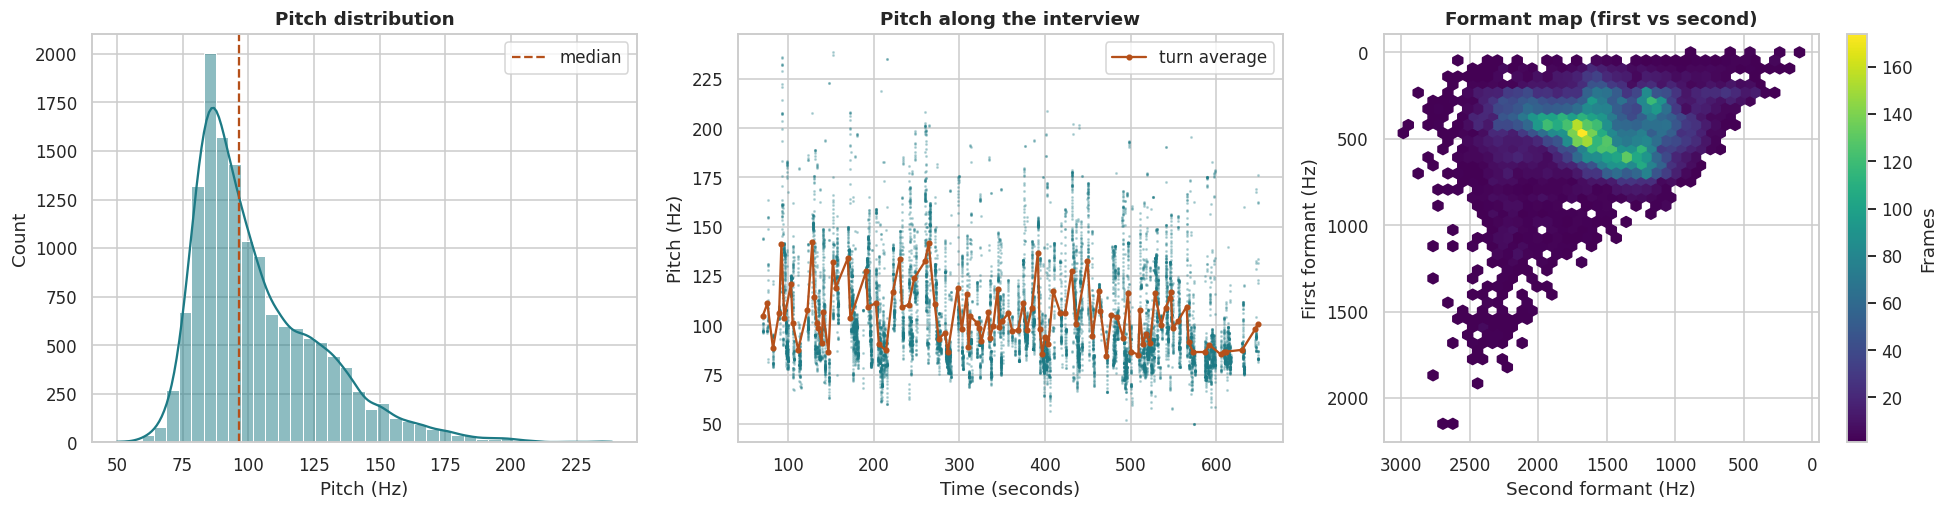

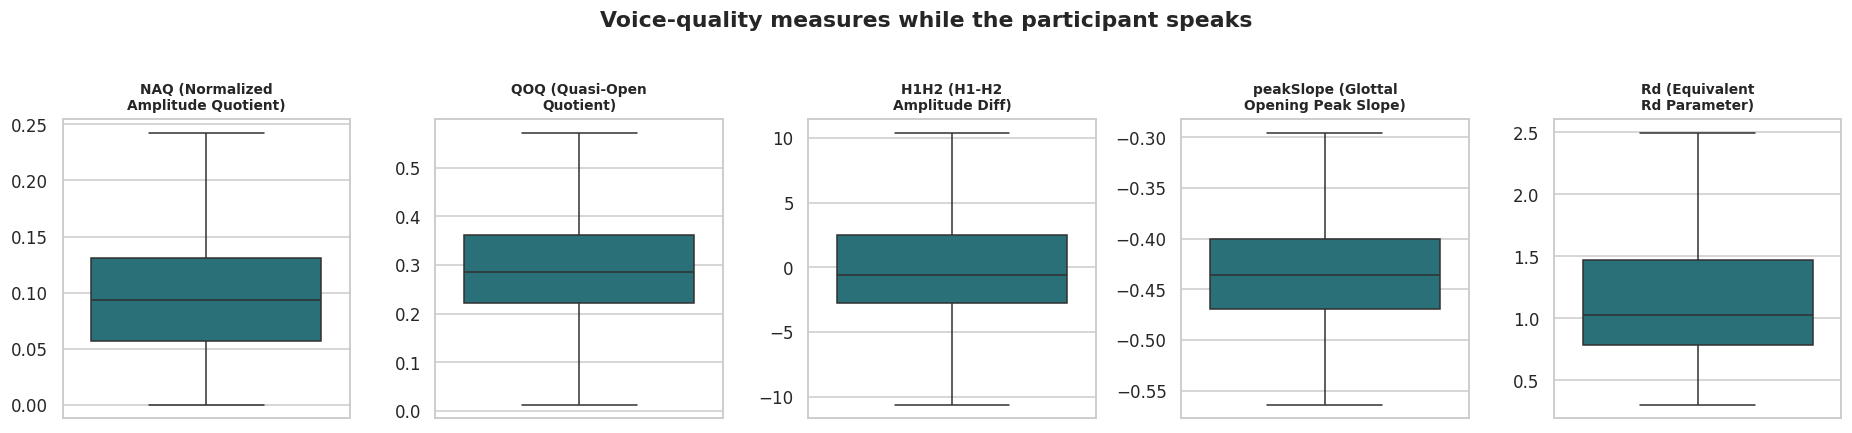

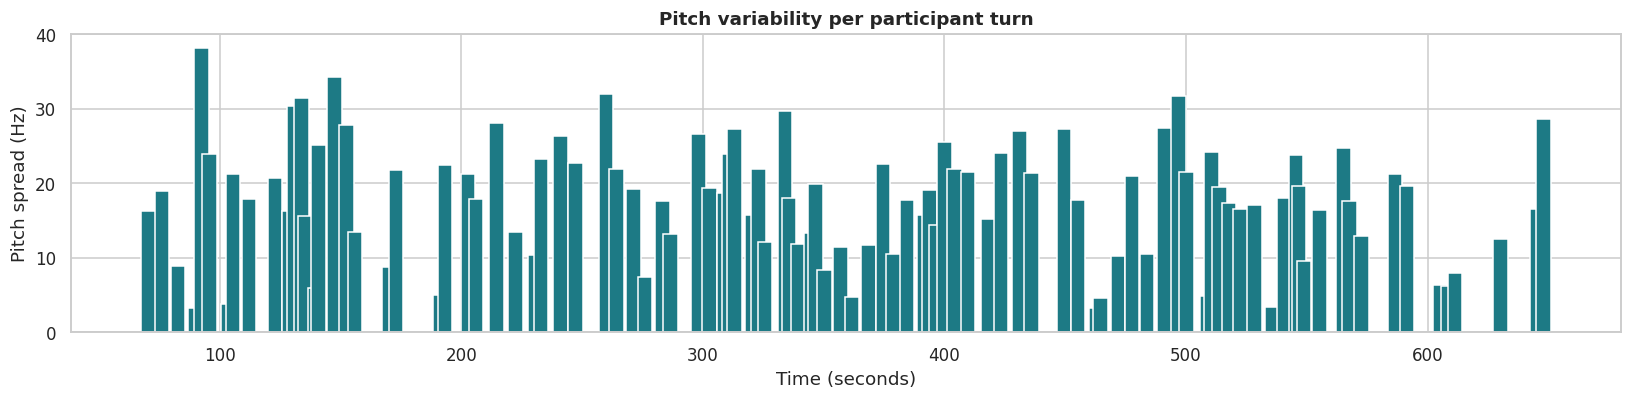

In [ ]:
# ---------------------------------------------------------------
# VOICE: pitch, voice quality and formants (participant speech only)
# ---------------------------------------------------------------
# The file has no header, so we name the columns in the documented order. The documentation lists fewer
# names than the file has columns; the extra one is assumed to be a creak indicator next to the confidence column.
cov_names = (["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf", "creak"]
             + [f"MCEP_{i}" for i in range(25)]
             + [f"HMPDM_{i}" for i in range(25)]
             + [f"HMPDD_{i}" for i in range(13)])

cov = pd.read_csv(PATHS["covarep"], header=None)
if cov.shape[1] == len(cov_names):
    cov.columns = cov_names
else:
    print("Column count differs from the expected layout; check the naming before trusting later cells.")
    cov.columns = cov_names[:cov.shape[1]] + [f"extra_{i}" for i in range(cov.shape[1] - len(cov_names))]

formant = pd.read_csv(PATHS["formant"], header=None, names=["F1", "F2", "F3", "F4", "F5"])

# Both files tick at the same fixed rate; trim to the shorter one so rows line up one-to-one.
n_rows = min(len(cov), len(formant))
voice = pd.concat([cov.iloc[:n_rows][["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd"]].reset_index(drop=True),
                   formant.iloc[:n_rows][["F1", "F2", "F3"]].reset_index(drop=True)], axis=1)
voice = voice.replace([np.inf, -np.inf], np.nan)

FRAME_STEP = 0.01  # seconds between audio-feature rows
voice["time"] = np.arange(n_rows) * FRAME_STEP
voice["speaking"] = speech_mask(voice["time"], participant)

# Voiced means the vocal folds are vibrating; only then are pitch and voice-quality values valid.
voice["voiced"] = (voice["VUV"] == 1) & (voice["F0" ]> 0)
speech_voiced = voice[voice["speaking"] & voice["voiced"]].copy()
print(f"Voiced share while participant speaks: {voice.loc[voice['speaking'], 'voiced'].mean():.1%}")

# One summary row per participant turn, so changes in delivery can be tied to what was being said.
rows = []
for _, turn in participant.iterrows():
    seg = voice.iloc[int(turn["start_time"] / FRAME_STEP): int(turn["stop_time"] / FRAME_STEP)]
    seg_voiced = seg[seg["voiced"]]
    if len(seg_voiced) < 20:
        continue
    rows.append({"start_time": turn["start_time"], "window": turn["window"], "n_words": turn["n_words"],
                 "pitch_mean": seg_voiced["F0"].mean(), "pitch_std": seg_voiced["F0"].std(),
                 "pitch_range": seg_voiced["F0"].quantile(0.95) - seg_voiced["F0"].quantile(0.05),
                 "voiced_ratio": len(seg_voiced) / max(len(seg), 1),
                 "NAQ": seg_voiced["NAQ"].mean(), "QOQ": seg_voiced["QOQ"].mean(),
                 "H1H2": seg_voiced["H1H2"].mean(), "peakSlope": seg_voiced["peakSlope"].mean()})
voice_turns = pd.DataFrame(rows)

window_voice = voice_turns.groupby("window").apply(lambda g: pd.Series({
    "pitch_mean": weighted_mean(g["pitch_mean"], g["n_words"]),
    "pitch_std": weighted_mean(g["pitch_std"], g["n_words"]),
    "voiced_ratio": weighted_mean(g["voiced_ratio"], g["n_words"]),
    "breathiness_naq": weighted_mean(g["NAQ"], g["n_words"])}))
WINDOW_TABLES["voice"] = window_voice

print("Overall voice profile (participant, voiced frames)")
display(speech_voiced[["F0", "NAQ", "QOQ", "H1H2", "peakSlope", "Rd", "F1", "F2", "F3"]].describe().loc[["mean", "std", "min", "max"]].round(2))

# ----- figures -----
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Pitch distribution: spread shows how much the pitch moves; a narrow hump suggests flat delivery.
sns.histplot(speech_voiced["F0"], bins=40, kde=True, color=COLORS["participant"], ax=axes[0])
axes[0].axvline(speech_voiced["F0"].median(), color=COLORS["interviewer"], ls="--", label="median")
axes[0].set_title("Pitch distribution")
axes[0].set_xlabel("Pitch (Hz)")
axes[0].legend()

# Pitch contour along the interview, with each turn's average on top.
axes[1].scatter(speech_voiced["time"], speech_voiced["F0"], s=1, alpha=0.25, color=COLORS["participant"])
axes[1].plot(voice_turns["start_time"], voice_turns["pitch_mean"], color=COLORS["interviewer"], marker="o", ms=3, label="turn average")
axes[1].set_title("Pitch along the interview")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Pitch (Hz)")
axes[1].legend()

# Vowel-style map from the first two formants: tells which speech sounds the participant produces.
hb = axes[2].hexbin(speech_voiced["F2"], speech_voiced["F1"], gridsize=40, cmap="viridis", mincnt=1)
axes[2].invert_xaxis()
axes[2].invert_yaxis()
axes[2].set_title("Formant map (first vs second)")
axes[2].set_xlabel("Second formant (Hz)")
axes[2].set_ylabel("First formant (Hz)")
plt.colorbar(hb, ax=axes[2], label="Frames")
save_fig("voice_pitch_and_formants")

# Voice-quality measures mapped to their full academic/lexical definition terms.
quality_cols = ["NAQ", "QOQ", "H1H2", "peakSlope", "Rd"]
quality_definitions = {
    "NAQ": "NAQ (Normalized\nAmplitude Quotient)",
    "QOQ": "QOQ (Quasi-Open\nQuotient)",
    "H1H2": "H1H2 (H1-H2\nAmplitude Diff)",
    "peakSlope": "peakSlope (Glottal\nOpening Peak Slope)",
    "Rd": "Rd (Equivalent\nRd Parameter)"
}

fig, axes = plt.subplots(1, len(quality_cols), figsize=(17, 3.8))
for ax, col in zip(axes, quality_cols):
    sns.boxplot(y=speech_voiced[col], ax=ax, color=COLORS["participant"], showfliers=False)
    ax.set_title(quality_definitions[col], fontsize=9)
    ax.set_ylabel("")
fig.suptitle("Voice-quality measures while the participant speaks", fontweight="bold", y=1.03)
save_fig("voice_quality_measures")

# Pitch variability for every turn: tall bars are expressive turns, short bars are flat ones.
fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(voice_turns["start_time"], voice_turns["pitch_std"], width=6, color=COLORS["participant"])
ax.set_title("Pitch variability per participant turn")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Pitch spread (Hz)")
save_fig("voice_pitch_variability")

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

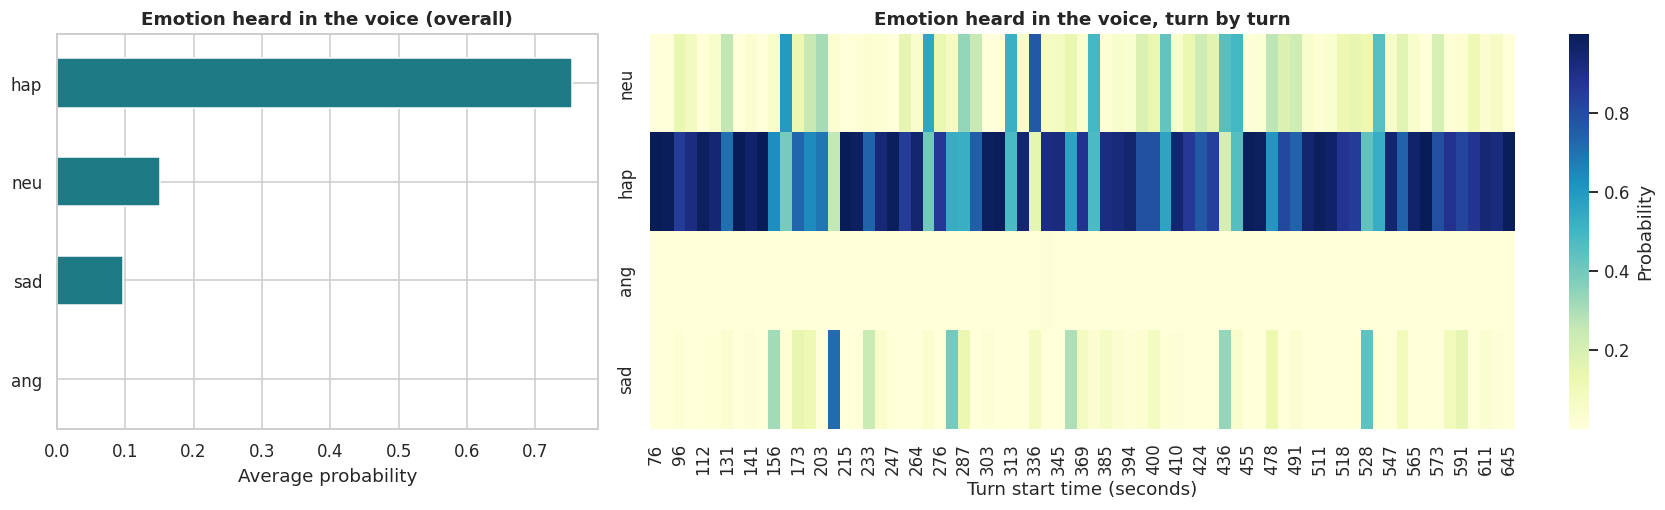

In [ ]:
# ---------------------------------------------------------------
# VOICE EMOTION: pretrained speech-emotion model on participant turns
# ---------------------------------------------------------------
RUN_SPEECH_EMOTION = True
SER_MODEL = "superb/wav2vec2-base-superb-er"   # small, open model; labels are neutral, happy, angry, sad
TARGET_SR = 16000
MAX_CHUNK_SEC = 15      # long turns are cut into pieces so memory stays small
MIN_TURN_SEC = 1.0      # very short turns are skipped because they carry too little signal

if RUN_SPEECH_EMOTION:
    from scipy.io import wavfile
    from scipy.signal import resample_poly
    from transformers import AutoFeatureExtractor, AutoModelForAudioClassification

    set_all_seeds()

    # Load the waveform as floating point between minus one and one, mono, at the sampling rate the model expects.
    sr, wave = wavfile.read(PATHS["audio"])
    wave = wave.astype(np.float32) / (np.iinfo(np.int16).max if wave.dtype == np.int16 else 1.0)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    if sr != TARGET_SR:
        wave = resample_poly(wave, TARGET_SR, sr).astype(np.float32)

    extractor = AutoFeatureExtractor.from_pretrained(SER_MODEL)
    ser_model = AutoModelForAudioClassification.from_pretrained(SER_MODEL).to("cuda" if torch.cuda.is_available() else "cpu").eval()
    id2label = ser_model.config.id2label

    def emotion_probs(chunk):
        """Return the emotion probability vector for one audio chunk."""
        inputs = extractor(chunk, sampling_rate=TARGET_SR, return_tensors="pt", padding=True)
        inputs = {k: v.to(ser_model.device) for k, v in inputs.items()}
        with torch.no_grad():
            logits = ser_model(**inputs).logits
        return torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    rows = []
    for _, turn in participant.iterrows():
        if turn["duration"] < MIN_TURN_SEC:
            continue
        segment = wave[int(turn["start_time"] * TARGET_SR): int(turn["stop_time"] * TARGET_SR)]
        chunk_len = MAX_CHUNK_SEC * TARGET_SR
        pieces = [segment[i:i + chunk_len] for i in range(0, len(segment), chunk_len) if len(segment[i:i + chunk_len]) > TARGET_SR // 2]
        if not pieces:
            continue
        lengths = np.array([len(p) for p in pieces], float)
        probs_turn = np.average([emotion_probs(p) for p in pieces], axis=0, weights=lengths)
        rows.append({"start_time": turn["start_time"], "window": turn["window"], "duration": turn["duration"],
                     **{id2label[i]: probs_turn[i] for i in range(len(probs_turn))}})

    ser = pd.DataFrame(rows)
    SER_LABELS = [id2label[i] for i in sorted(id2label)]

    overall_ser = ser[SER_LABELS].mul(ser["duration"], axis=0).sum() / ser["duration"].sum()
    window_ser = ser.groupby("window").apply(lambda g: pd.Series({l: weighted_mean(g[l], g["duration"]) for l in SER_LABELS}))
    WINDOW_TABLES["voice_emotion"] = window_ser.add_prefix("ser_")

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [0.8, 1.6]})
    overall_ser.sort_values().plot.barh(ax=axes[0], color=COLORS["participant"])
    axes[0].set_title("Emotion heard in the voice (overall)")
    axes[0].set_xlabel("Average probability")

    sns.heatmap(ser.set_index(ser["start_time"].round(0).astype(int))[SER_LABELS].T, cmap="YlGnBu", ax=axes[1],
                cbar_kws={"label": "Probability"})
    axes[1].set_title("Emotion heard in the voice, turn by turn")
    axes[1].set_xlabel("Turn start time (seconds)")
    save_fig("voice_emotion_model")
else:
    print("Speech-emotion step skipped.")

##Gaze and head pose

Frames dropped because tracking failed: 9.9%
Speaking vs listening, median values


,head_speed,head_turn_speed
speaking,,
listening / silent,17.41,6.92
speaking,18.13,7.51


Share of frames with steady gaze around the typical direction: 55.9%


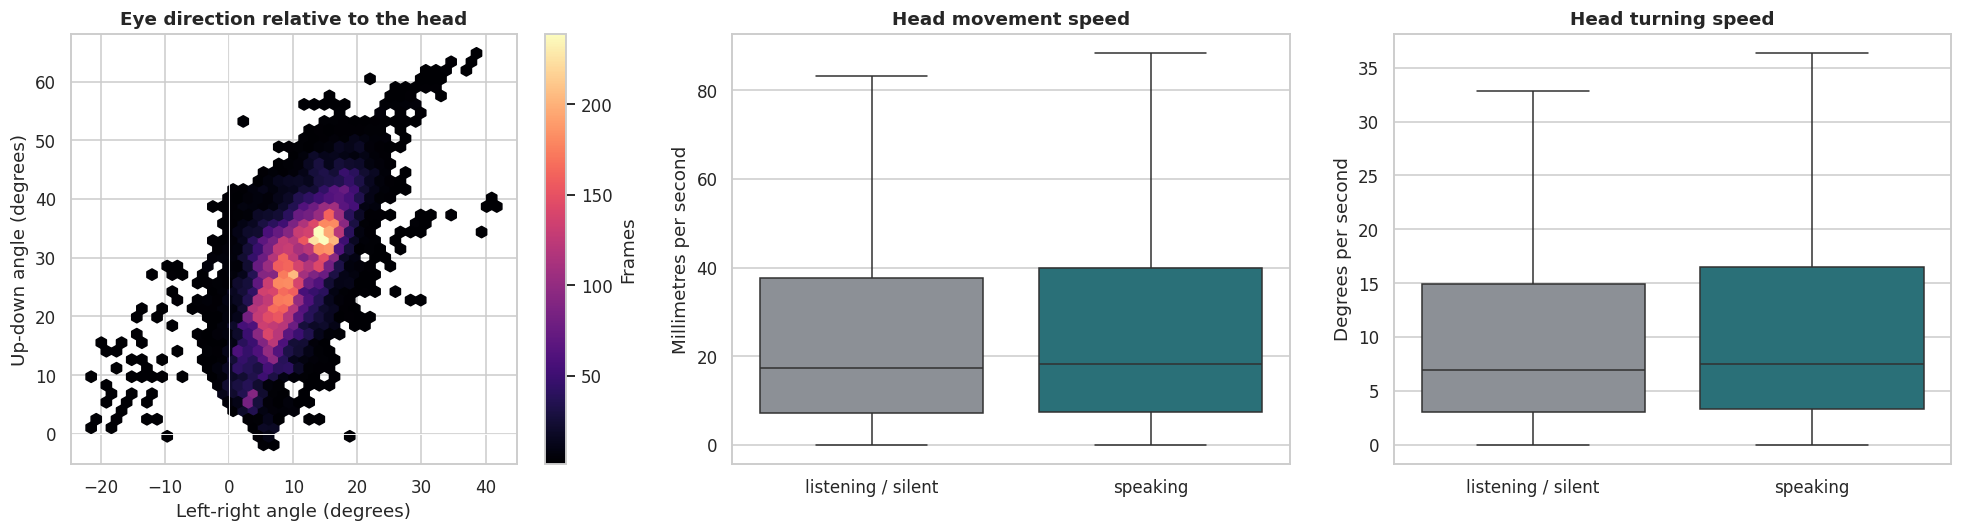

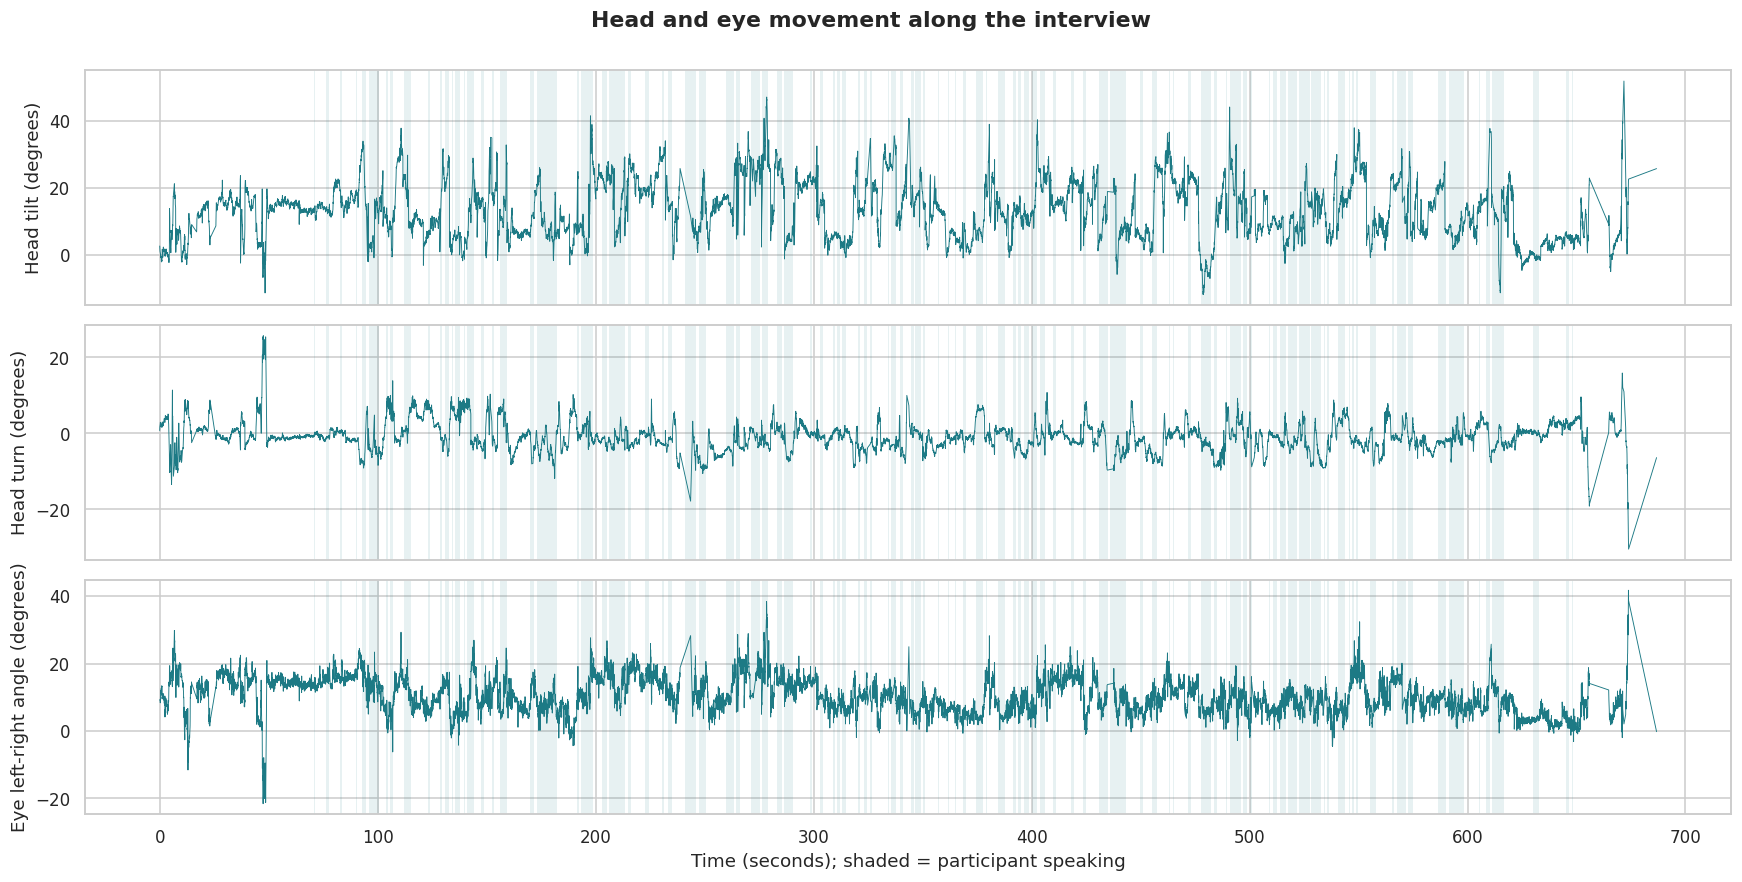

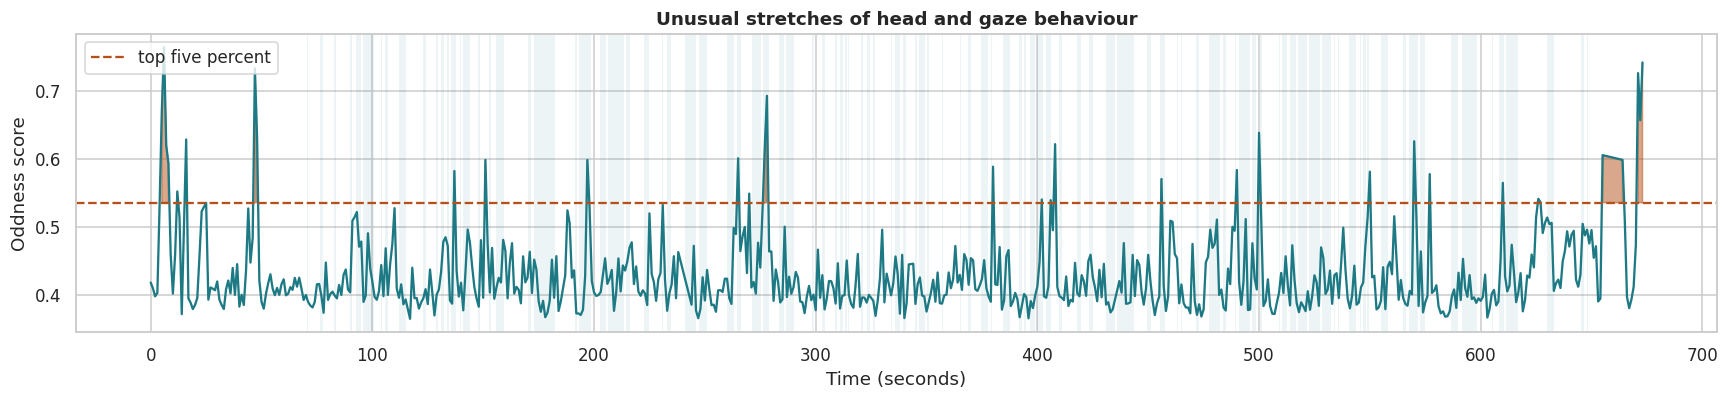

In [ ]:
# ---------------------------------------------------------------
# GAZE + HEAD POSE: angles, movement speed, steadiness, anomalies
# ---------------------------------------------------------------
from sklearn.ensemble import IsolationForest

set_all_seeds()

gaze = pd.read_csv(PATHS["gaze"], skipinitialspace=True)
pose = pd.read_csv(PATHS["pose"], skipinitialspace=True)

# Both files share the same frames; keep only frames where the tracker succeeded.
motion = gaze.merge(pose[["frame", "Tx", "Ty", "Tz", "Rx", "Ry", "Rz"]], on="frame")
print(f"Frames dropped because tracking failed: {(motion['success'] != 1).mean():.1%}")
motion = motion[motion["success"] == 1].reset_index(drop=True)
frame_step = motion["timestamp"].diff().median()

# Eye direction as two angles. Head-space vectors tell where the eyes point relative to the head; world-space
# vectors tell where they point relative to the camera. Average both eyes. In the tracker's convention a positive
# vertical angle means looking below the camera axis.
def to_angles(x, y, z):
    """Convert a 3D direction into left-right (yaw) and up-down (pitch) angles in degrees."""
    return np.degrees(np.arctan2(x, -z)), np.degrees(np.arctan2(y, -z))

motion["eye_yaw_head"], motion["eye_pitch_head"] = to_angles((motion["x_h0"] + motion["x_h1"]) / 2,
                                                             (motion["y_h0"] + motion["y_h1"]) / 2,
                                                             (motion["z_h0"] + motion["z_h1"]) / 2)
motion["gaze_yaw_cam"], motion["gaze_pitch_cam"] = to_angles((motion["x_0"] + motion["x_1"]) / 2,
                                                             (motion["y_0"] + motion["y_1"]) / 2,
                                                             (motion["z_0"] + motion["z_1"]) / 2)

# Head rotation in degrees (tilt forward-back, turn left-right, roll sideways).
for src, dst in [("Rx", "head_pitch"), ("Ry", "head_yaw"), ("Rz", "head_roll")]:
    motion[dst] = np.degrees(motion[src])

# Smooth lightly with a rolling median so tracker jitter does not look like movement, then take speeds.
smooth = motion[["Tx", "Ty", "Tz", "head_pitch", "head_yaw", "head_roll"]].rolling(5, center=True, min_periods=1).median()
dt = motion["timestamp"].diff()
gap = dt > 3 * frame_step   # after a tracking gap the difference is not a real speed
motion["head_speed"] = np.sqrt(smooth[["Tx", "Ty", "Tz"]].diff().pow(2).sum(axis=1)) / dt
motion["head_turn_speed"] = np.sqrt(smooth[["head_pitch", "head_yaw", "head_roll"]].diff().pow(2).sum(axis=1)) / dt
motion.loc[gap, ["head_speed", "head_turn_speed"]] = np.nan

motion["speaking"] = speech_mask(motion["timestamp"], participant)
motion["window"] = to_window(motion["timestamp"])

# Steadiness proxy: how often the world-space gaze stays close to the participant's own typical direction.
# Using their own median as the reference avoids assuming where the screen or camera sits.
STEADY_TOLERANCE_DEG = 5
motion["steady_gaze"] = (((motion["gaze_yaw_cam"] - motion["gaze_yaw_cam"].median()).abs() < STEADY_TOLERANCE_DEG)
                         & ((motion["gaze_pitch_cam"] - motion["gaze_pitch_cam"].median()).abs() < STEADY_TOLERANCE_DEG))

# Per-window summary for fusion, on the participant's speaking frames.
spk = motion[motion["speaking"]]
window_motion = spk.groupby("window").agg(
    gaze_spread=("eye_yaw_head", "std"),
    gaze_vertical_spread=("eye_pitch_head", "std"),
    steady_gaze_share=("steady_gaze", "mean"),
    head_speed=("head_speed", "median"),
    head_turn_speed=("head_turn_speed", "median"),
    head_yaw_spread=("head_yaw", "std"),
)
WINDOW_TABLES["motion"] = window_motion

print("Speaking vs listening, median values")
display(motion.groupby("speaking")[["head_speed", "head_turn_speed"]].median().round(2).rename(index={True: "speaking", False: "listening / silent"}))
print(f"Share of frames with steady gaze around the typical direction: {motion['steady_gaze'].mean():.1%}")

# Unusual stretches: one row per second of simple steadiness features, scored by an isolation forest.
motion["second"] = motion["timestamp"].astype(int)
per_second = motion.groupby("second").agg(
    gaze_yaw_mean=("eye_yaw_head", "mean"), gaze_pitch_mean=("eye_pitch_head", "mean"),
    gaze_yaw_std=("eye_yaw_head", "std"), head_turn=("head_turn_speed", "median"),
    head_speed=("head_speed", "median")).dropna()
forest = IsolationForest(n_estimators=200, contamination="auto", random_state=SEED).fit(per_second)
per_second["oddness"] = -forest.score_samples(per_second[["gaze_yaw_mean", "gaze_pitch_mean", "gaze_yaw_std", "head_turn", "head_speed"]])

# ----- figures -----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Where the eyes point relative to the head; a tight blob means steady gaze.
hb = axes[0].hexbin(motion["eye_yaw_head"], motion["eye_pitch_head"], gridsize=40, cmap="magma", mincnt=1)
axes[0].axhline(0, color="white", lw=0.6)
axes[0].axvline(0, color="white", lw=0.6)
axes[0].set_title("Eye direction relative to the head")
axes[0].set_xlabel("Left-right angle (degrees)")
axes[0].set_ylabel("Up-down angle (degrees)")
plt.colorbar(hb, ax=axes[0], label="Frames")

# Head movement speed: speaking against listening.
sns.boxplot(data=motion, x="speaking", y="head_speed", ax=axes[1], palette=[COLORS["neutral"], COLORS["participant"]], showfliers=False)
axes[1].set_xticklabels(["listening / silent", "speaking"])
axes[1].set_title("Head movement speed")
axes[1].set_xlabel("")
axes[1].set_ylabel("Millimetres per second")

# Head turning speed: same comparison.
sns.boxplot(data=motion, x="speaking", y="head_turn_speed", ax=axes[2], palette=[COLORS["neutral"], COLORS["participant"]], showfliers=False)
axes[2].set_xticklabels(["listening / silent", "speaking"])
axes[2].set_title("Head turning speed")
axes[2].set_xlabel("")
axes[2].set_ylabel("Degrees per second")
save_fig("gaze_pose_overview")

# Time series of head angles with the participant's speaking turns shaded.
fig, axes = plt.subplots(3, 1, figsize=(16, 8), sharex=True)
for ax, col, label in [(axes[0], "head_pitch", "Head tilt (degrees)"),
                       (axes[1], "head_yaw", "Head turn (degrees)"),
                       (axes[2], "eye_yaw_head", "Eye left-right angle (degrees)")]:
    ax.plot(motion["timestamp"], motion[col], lw=0.6, color=COLORS["participant"])
    shade_turns(ax, participant, COLORS["participant"], alpha=0.10)
    ax.set_ylabel(label)
axes[-1].set_xlabel("Time (seconds); shaded = participant speaking")
fig.suptitle("Head and eye movement along the interview", fontweight="bold", y=1.0)
save_fig("gaze_pose_timeseries")

# Where the detector sees unusual head and gaze behaviour.
fig, ax = plt.subplots(figsize=(16, 3.8))
ax.plot(per_second.index, per_second["oddness"], color=COLORS["participant"])
threshold = per_second["oddness"].quantile(0.95)
ax.axhline(threshold, color=COLORS["interviewer"], ls="--", label="top five percent")
ax.fill_between(per_second.index, per_second["oddness"], threshold, where=per_second["oddness"] > threshold, color=COLORS["interviewer"], alpha=0.5)
shade_turns(ax, participant, COLORS["participant"], alpha=0.08)
ax.set_title("Unusual stretches of head and gaze behaviour")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Oddness score")
ax.legend()
save_fig("gaze_pose_anomalies")

##Fusion: all streams on one timeline

Streams included: ['talk', 'sentiment', 'emotion', 'language', 'face', 'voice', 'voice_emotion', 'motion']


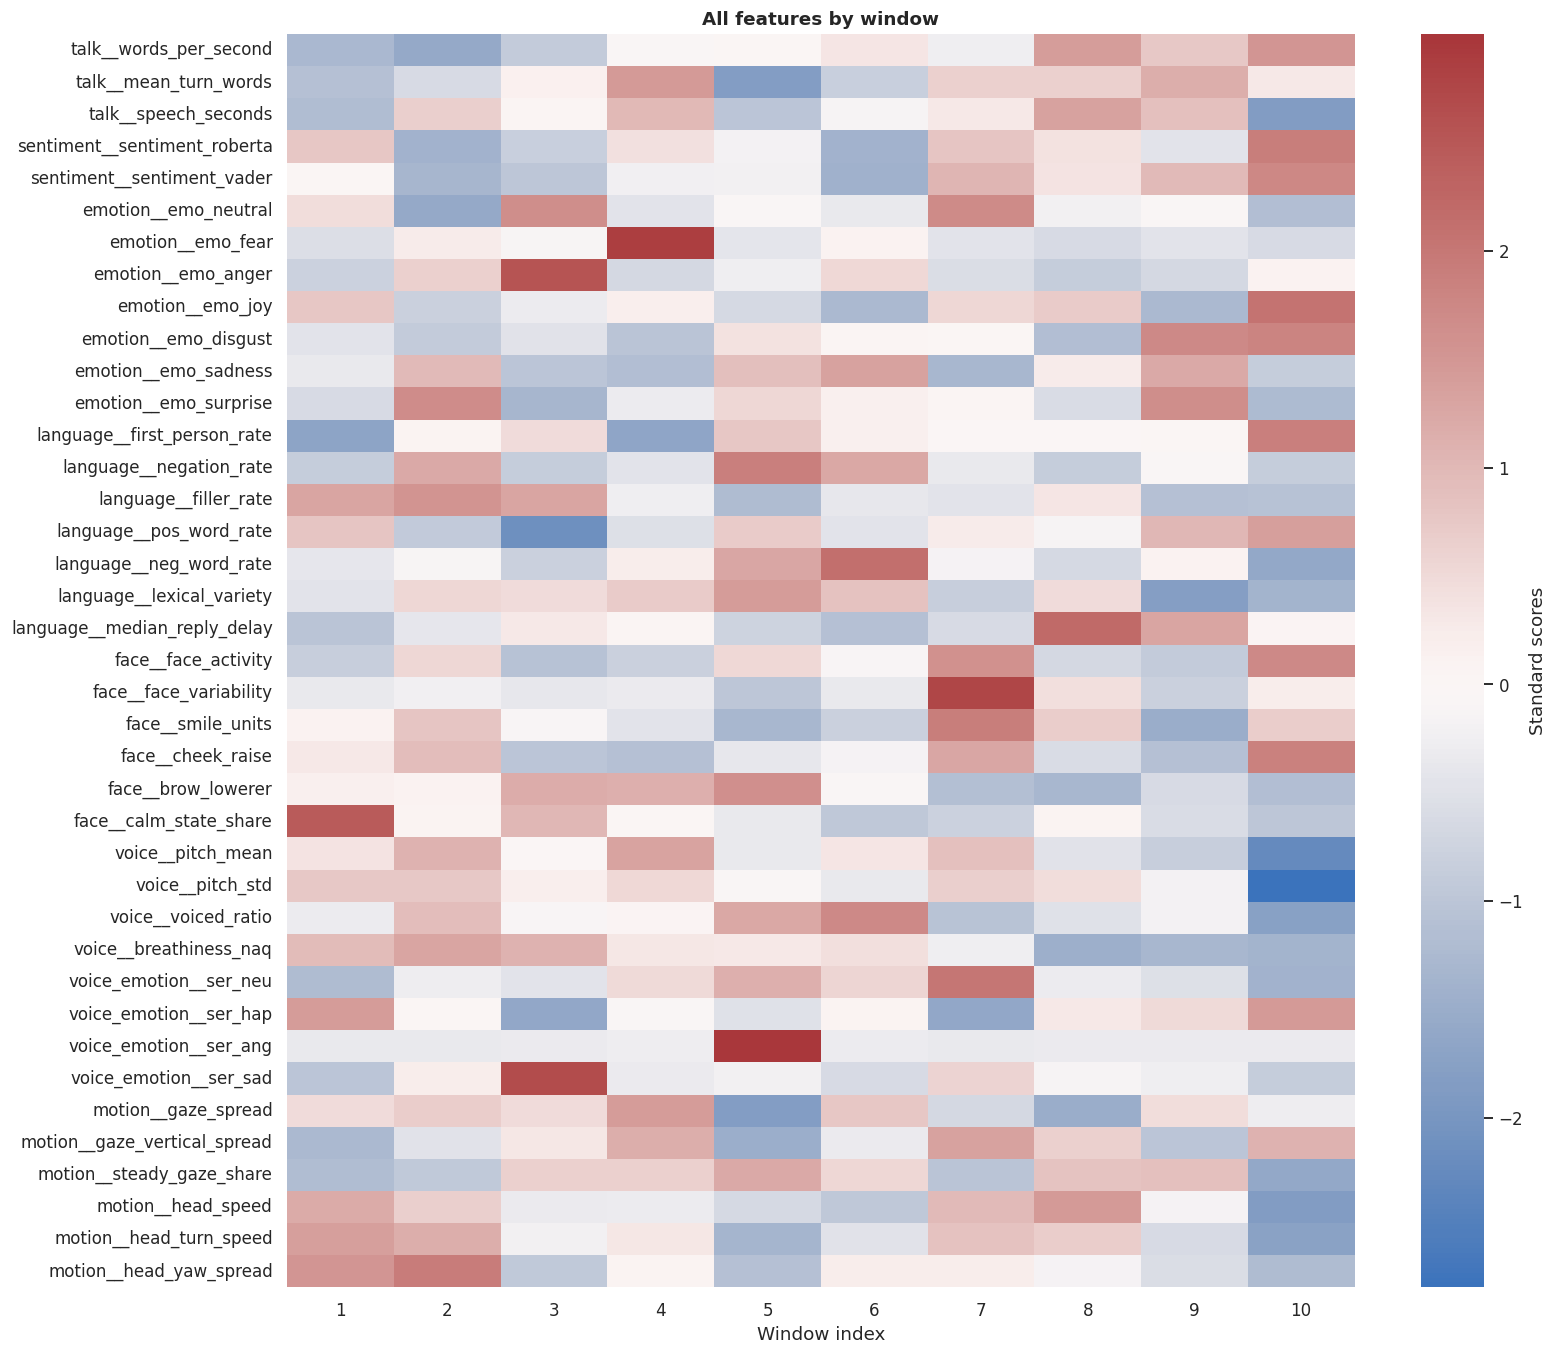

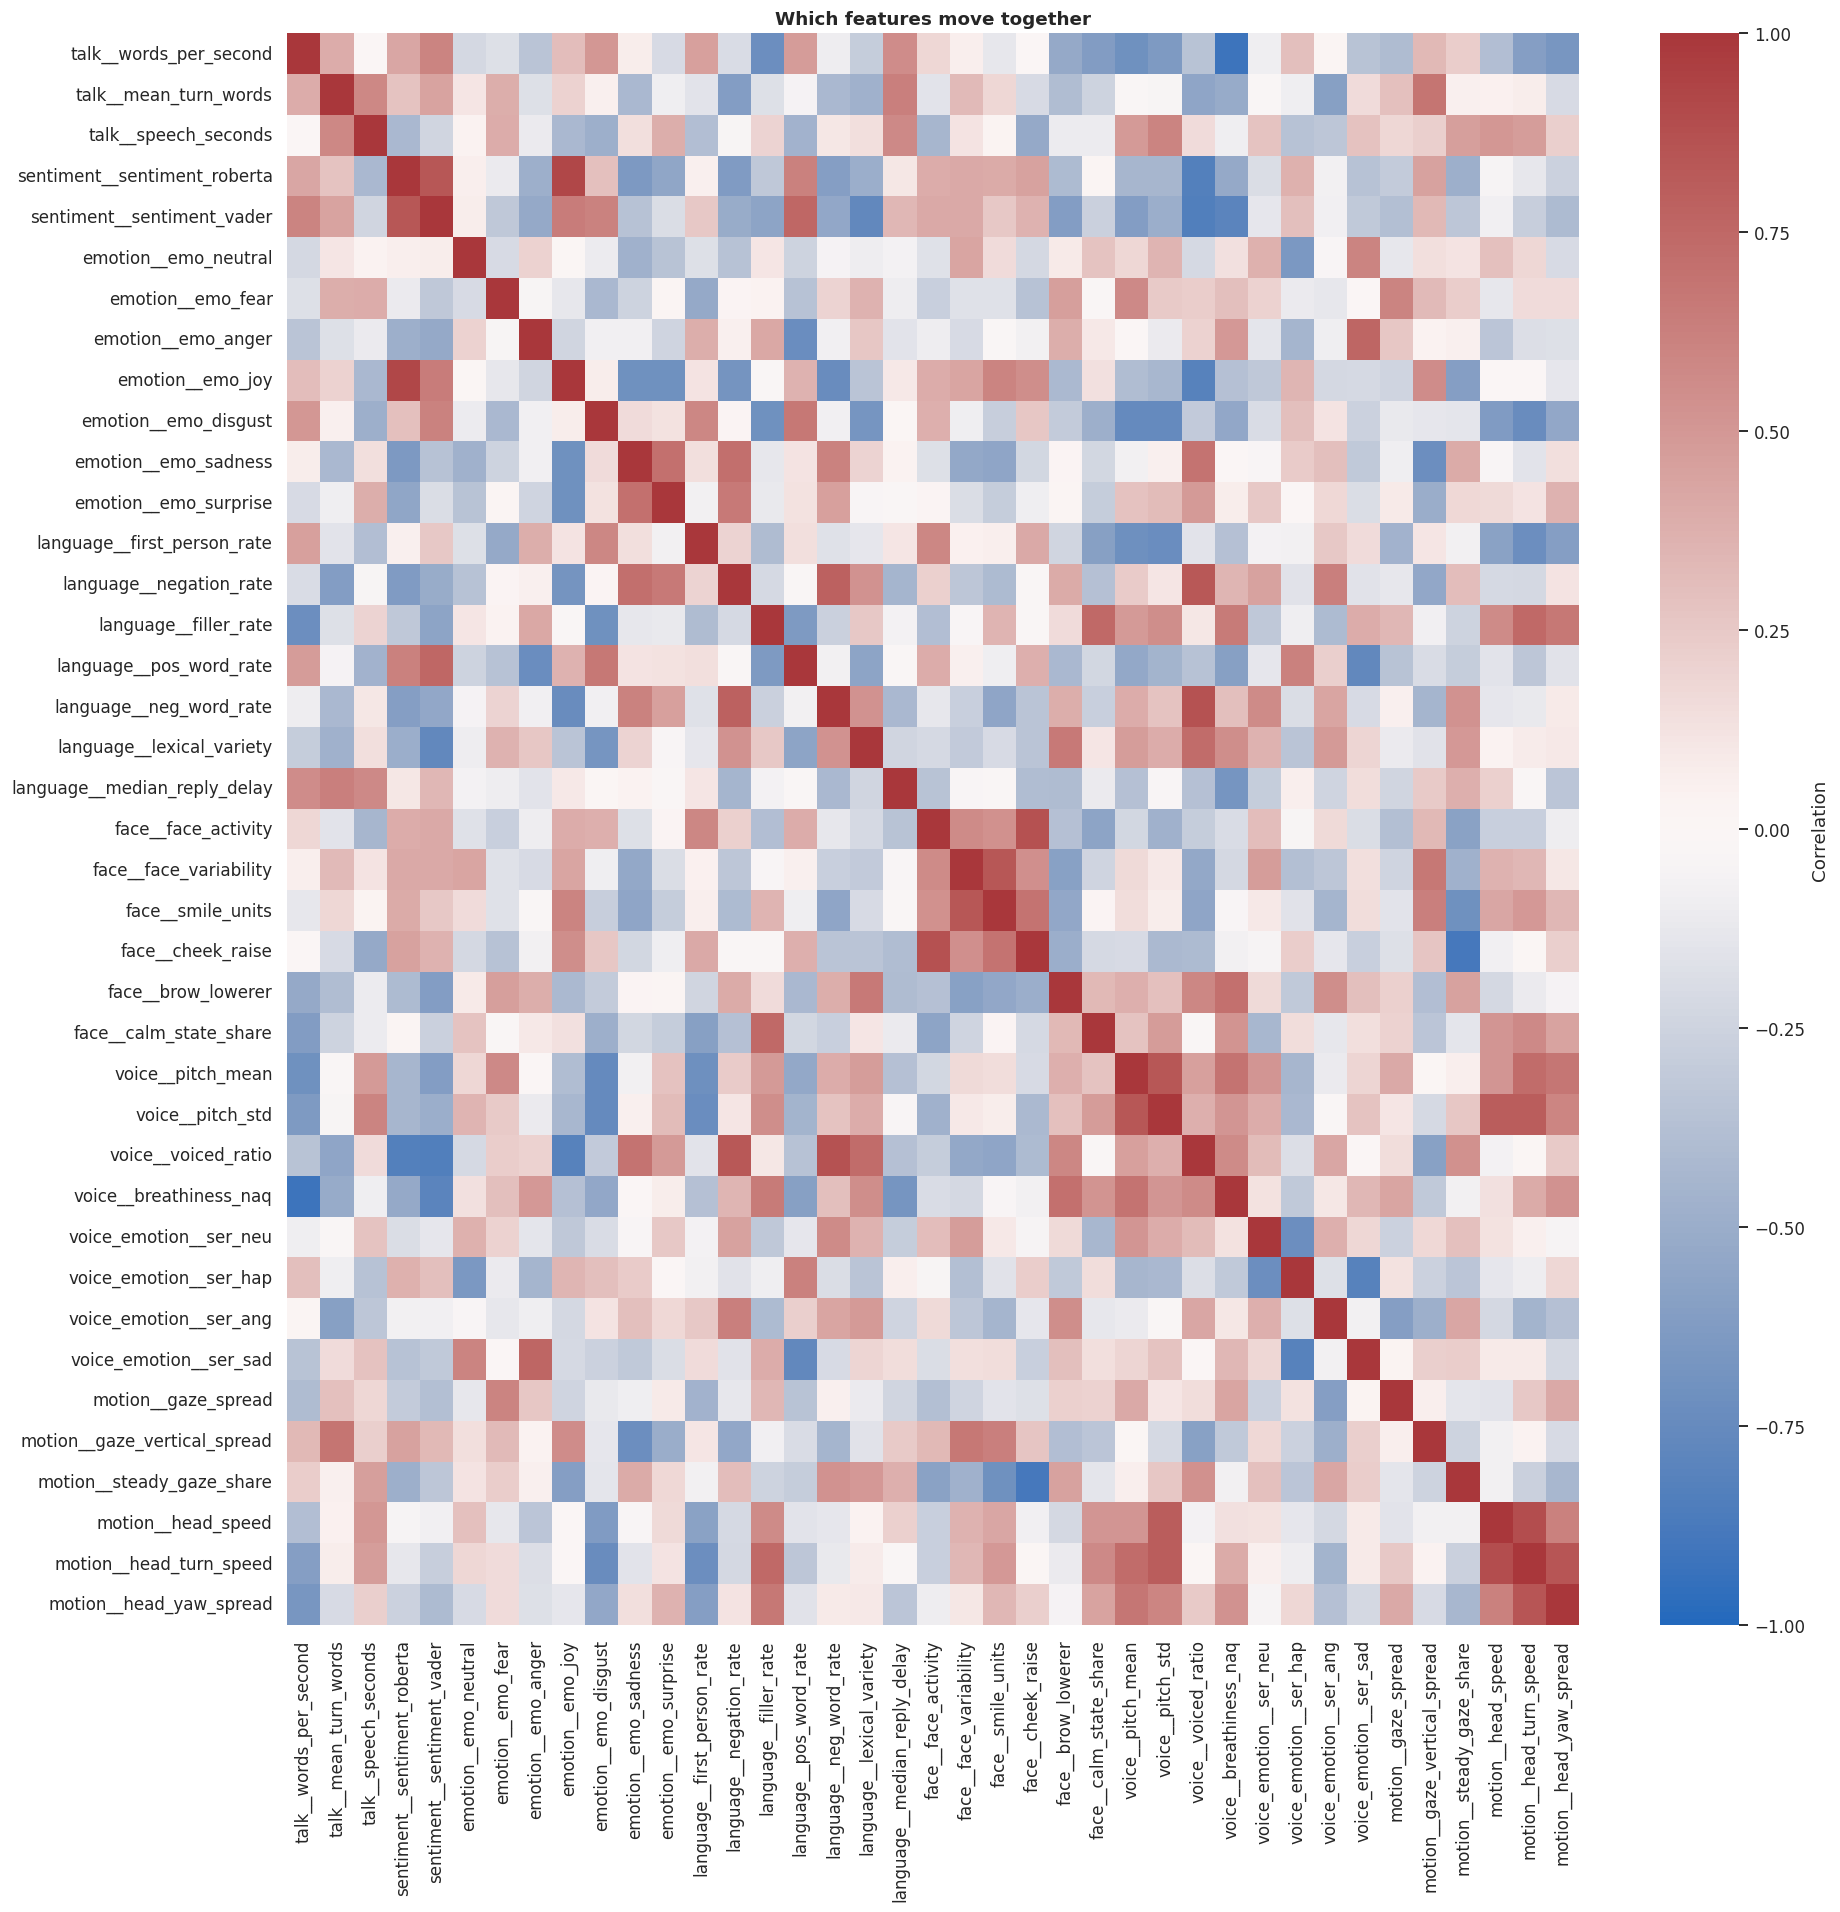

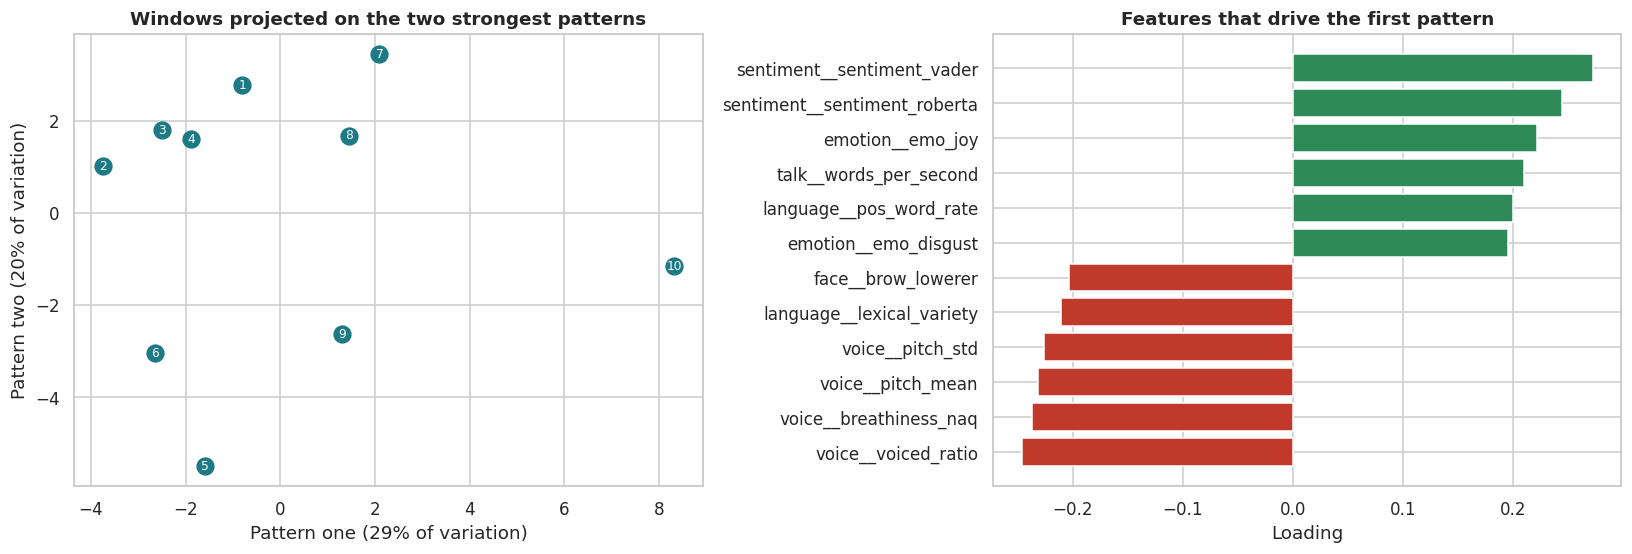

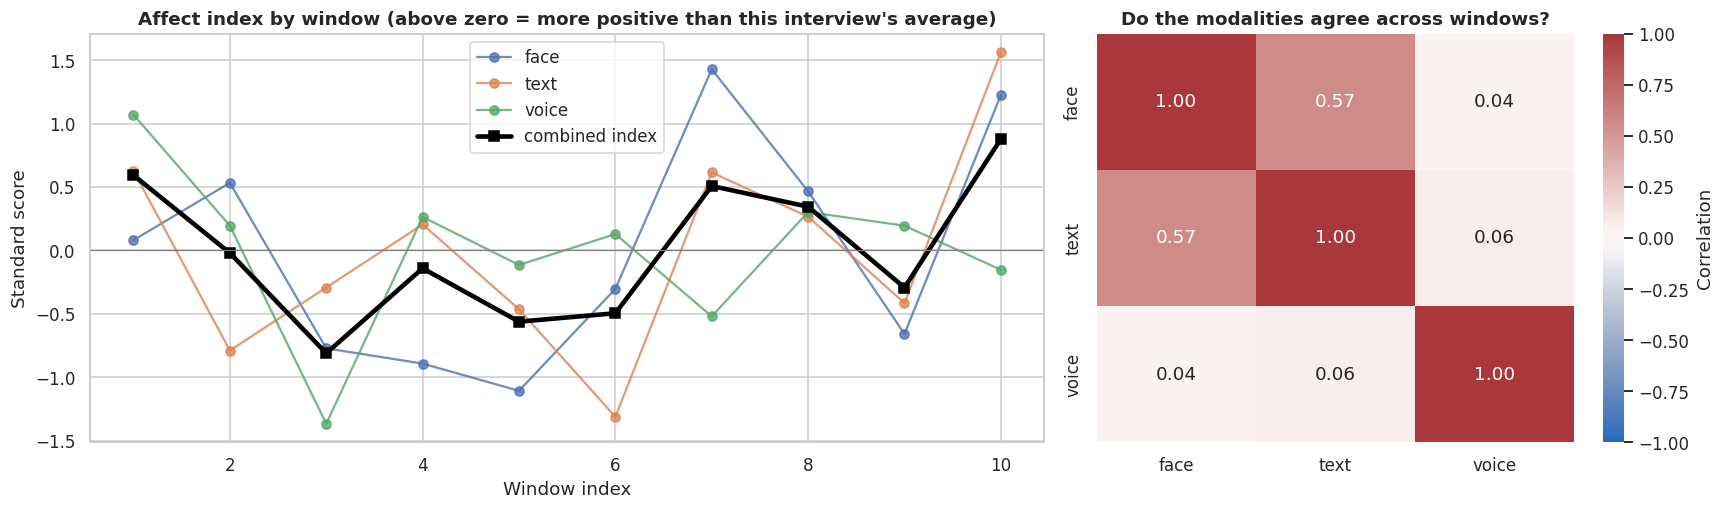

,value
text: median reply delay (s),2.1
face: switches per minute,14.495413
voice: median pitch (Hz),96.5
voice emotion: strongest,hap
gaze: share of steady frames,0.559289


In [ ]:
# ---------------------------------------------------------------
# FUSION: join the streams per window, compare, and build a transparent affect index
# ---------------------------------------------------------------
from sklearn.decomposition import PCA

# Join every stream's window summary on the window index; missing streams are simply absent.
tables = {name: tbl.add_prefix(f"{name}__") for name, tbl in WINDOW_TABLES.items() if len(tbl)}
fused = pd.concat(tables.values(), axis=1).sort_index()
print("Streams included:", list(tables))

# Require a feature to be present in most windows, and fill the rare gap with the column median.
usable = fused.loc[:, fused.notna().mean() >= 0.6]
fused_filled = usable.fillna(usable.median())
fused_z = fused_filled.apply(zscore)

# Which features count as "more positive feeling" (plus one) or "more negative feeling" (minus one).
# Edit this dictionary to try other definitions; the index is rebuilt from it automatically.
AFFECT_DIRECTIONS = {
    "sentiment__sentiment_roberta": +1,
    "emotion__emo_joy": +1,
    "emotion__emo_sadness": -1,
    "language__pos_word_rate": +1,
    "language__neg_word_rate": -1,
    "face__smile_units": +1,
    "face__cheek_raise": +1,
    "face__brow_lowerer": -1,
    "voice__pitch_std": +1,
    "voice_emotion__ser_hap": +1,
    "voice_emotion__ser_sad": -1,
}
# Which stream each feature belongs to, so contributions can be averaged inside a stream first.
STREAM_OF = {"sentiment": "text", "emotion": "text", "language": "text", "talk": "text",
             "face": "face", "voice": "voice", "voice_emotion": "voice", "motion": "gaze and pose"}
MODALITY_OF = lambda col: STREAM_OF[col.split("__")[0]]

present = [c for c in AFFECT_DIRECTIONS if c in fused_z.columns]
contrib = pd.DataFrame({c: AFFECT_DIRECTIONS[c] * fused_z[c] for c in present})
modality = pd.Series({c: MODALITY_OF(c) for c in present})
# Average inside each modality first, then across modalities, so a stream with many features does not dominate.
per_modality = contrib.T.groupby(modality).mean().T
fused["affect_index"] = per_modality.mean(axis=1)

# ----- figures -----
# Every feature, every window, on one scale: the quickest way to see where streams agree.
fig, ax = plt.subplots(figsize=(15, max(6, 0.32 * fused_z.shape[1])))
sns.heatmap(fused_z.T, cmap="vlag", center=0, ax=ax, cbar_kws={"label": "Standard scores"})
ax.set_title("All features by window")
ax.set_xlabel("Window index")
save_fig("fusion_feature_heatmap")

# Which streams move together across windows (few windows, so read it as a hint, not proof).
corr = fused_z.corr()
fig, ax = plt.subplots(figsize=(max(9, 0.45 * corr.shape[0]), max(8, 0.45 * corr.shape[0])))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Correlation"},
            xticklabels=True, yticklabels=True)
ax.set_title("Which features move together")
save_fig("fusion_correlation")

# Windows that look alike land close together in this projection.
if fused_z.shape[0] >= 3:
    pca = PCA(n_components=2, random_state=SEED)
    coords = pca.fit_transform(fused_z)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
    axes[0].scatter(coords[:, 0], coords[:, 1], s=120, color=COLORS["participant"])
    for idx, (x, y) in zip(fused_z.index, coords):
        axes[0].annotate(str(idx), (x, y), ha="center", va="center", color="white", fontsize=8)
    axes[0].set_title("Windows projected on the two strongest patterns")
    axes[0].set_xlabel(f"Pattern one ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    axes[0].set_ylabel(f"Pattern two ({pca.explained_variance_ratio_[1]:.0%} of variation)")

    loadings = pd.Series(pca.components_[0], index=fused_z.columns).sort_values()
    top = pd.concat([loadings.head(6), loadings.tail(6)])
    axes[1].barh(top.index, top.values, color=[COLORS["negative"] if v < 0 else COLORS["positive"] for v in top.values])
    axes[1].set_title("Features that drive the first pattern")
    axes[1].set_xlabel("Loading")
    save_fig("fusion_pca")

# The affect index: how each modality contributes, and the combined line.
if len(present):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
    per_modality.plot(marker="o", ax=axes[0], alpha=0.8)
    axes[0].plot(fused.index, fused["affect_index"], color="black", lw=3, marker="s", label="combined index")
    axes[0].axhline(0, color="grey", lw=0.8)
    axes[0].set_title("Affect index by window (above zero = more positive than this interview's average)")
    axes[0].set_xlabel("Window index")
    axes[0].set_ylabel("Standard score")
    axes[0].legend()

    # Do the modalities rise and fall together? Every feature is standardised inside this one interview, so averages
    # sit at zero by construction; agreement across windows is the informative quantity.
    sns.heatmap(per_modality.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[1],
                cbar_kws={"label": "Correlation"})
    axes[1].set_title("Do the modalities agree across windows?")
    save_fig("fusion_affect_index")

# One headline table: the plain-language numbers worth quoting from each stream.
headline = {}
if "sentiment" in WINDOW_TABLES and "roberta_weighted_mean" in overall:
    headline["text: overall sentiment (RoBERTa)"] = overall["roberta_weighted_mean"]
    if "emotion" in WINDOW_TABLES: headline["text: strongest emotion"] = overall_emotion.idxmax()
if "language" in WINDOW_TABLES: headline["text: median reply delay (s)"] = valid_delay.median()
if "face" in WINDOW_TABLES: headline["face: switches per minute"] = switches_per_minute
if "voice" in WINDOW_TABLES: headline["voice: median pitch (Hz)"] = speech_voiced["F0"].median()
if "voice_emotion" in WINDOW_TABLES: headline["voice emotion: strongest"] = overall_ser.idxmax()
if "motion" in WINDOW_TABLES: headline["gaze: share of steady frames"] = motion["steady_gaze"].mean()
display(pd.Series(headline, name="value").to_frame())

#Train_split Label

In [4]:
import pandas as pd
import numpy as np

In [5]:
train_df = pd.read_csv("/content/drive/MyDrive/Multimodal_CEDS/train_split_Depression_AVEC2017.csv")
train_df.head(10)

,Participant_ID,PHQ8_Binary,PHQ8_Score,Gender,PHQ8_NoInterest,PHQ8_Depressed,PHQ8_Sleep,PHQ8_Tired,PHQ8_Appetite,PHQ8_Failure,PHQ8_Concentrating,PHQ8_Moving
0,303,0,0,0,0,0,0.0,0,0,0,0,0
1,304,0,6,0,0,1,1.0,2,2,0,0,0
2,305,0,7,1,0,1,1.0,2,2,1,0,0
3,310,0,4,1,1,1,0.0,0,0,1,1,0
4,312,0,2,1,0,0,1.0,1,0,0,0,0
5,313,0,7,1,1,1,1.0,1,1,1,1,0
6,315,0,2,1,0,0,0.0,1,1,0,0,0
7,316,0,6,1,1,1,1.0,1,0,1,1,0
8,317,0,8,1,1,1,1.0,1,1,1,2,0
9,318,0,3,1,0,0,1.0,1,1,0,0,0


In [6]:
display(train_df.info())
print("\n\n\n")
display(train_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Participant_ID      107 non-null    int64  
 1   PHQ8_Binary         107 non-null    int64  
 2   PHQ8_Score          107 non-null    int64  
 3   Gender              107 non-null    int64  
 4   PHQ8_NoInterest     107 non-null    int64  
 5   PHQ8_Depressed      107 non-null    int64  
 6   PHQ8_Sleep          106 non-null    float64
 7   PHQ8_Tired          107 non-null    int64  
 8   PHQ8_Appetite       107 non-null    int64  
 9   PHQ8_Failure        107 non-null    int64  
 10  PHQ8_Concentrating  107 non-null    int64  
 11  PHQ8_Moving         107 non-null    int64  
dtypes: float64(1), int64(11)
memory usage: 10.2 KB


None

,Participant_ID,PHQ8_Binary,PHQ8_Score,Gender,PHQ8_NoInterest,PHQ8_Depressed,PHQ8_Sleep,PHQ8_Tired,PHQ8_Appetite,PHQ8_Failure,PHQ8_Concentrating,PHQ8_Moving
count,107.000000,107.000000,107.000000,107.000000,107.000000,107.000000,106.000000,107.000000,107.000000,107.000000,107.000000,107.000000
mean,389.934579,0.280374,6.420561,0.588785,0.747664,0.803738,1.018868,1.037383,0.915888,0.869159,0.700935,0.317757
std,55.187036,0.451296,5.463494,0.494370,0.825232,0.873501,1.004572,0.910372,1.001146,0.991322,0.923641,0.667269
min,303.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,343.500000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,380.000000,0.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
75%,439.000000,1.000000,10.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,1.000000,1.000000,0.000000
max,491.000000,1.000000,20.000000,1.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000


In [7]:
display(train_df.nunique())
display(train_df['PHQ8_Binary'].value_counts())

,0
Participant_ID,107
PHQ8_Binary,2
PHQ8_Score,19
Gender,2
PHQ8_NoInterest,4
PHQ8_Depressed,4
PHQ8_Sleep,4
PHQ8_Tired,4
PHQ8_Appetite,4
PHQ8_Failure,4


,count
PHQ8_Binary,
0,77
1,30


In [8]:
# Configure pandas to display all rows and columns without truncation or collapsing
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

# Filter and select Participant_ID for each PHQ8_Binary class
non_depressed_ids = train_df[train_df["PHQ8_Binary"] == 0][["Participant_ID"]].reset_index(drop=True)
depressed_ids = train_df[train_df["PHQ8_Binary"] == 1][["Participant_ID"]].reset_index(drop=True)

print("Participants with PHQ8_Binary = 0 (Non-Depressed):")
display(non_depressed_ids)

Participants with PHQ8_Binary = 0 (Non-Depressed):


,Participant_ID
0,303
1,304
2,305
3,310
4,312
5,313
6,315
7,316
8,317
9,318


In [ ]:
print("\nParticipants with PHQ8_Binary = 1 (Depressed):")
display(depressed_ids)


Participants with PHQ8_Binary = 1 (Depressed):


,Participant_ID
0,319
1,320
2,321
3,325
4,330
5,338
6,339
7,344
8,345
9,347


#rough

In [9]:
import requests, zipfile, time
from pathlib import Path
from getpass import getpass

DEST = Path("/content/drive/MyDrive/Multimodal_CEDS")
DEST.mkdir(parents=True, exist_ok=True)
BASE = "https://dcapswoz.ict.usc.edu/wwwdaicwoz/"
SESSION_IDS = [339, 344, 345, 347, 348, 350, 351, 352, 353, 355,
               457, 463, 464, 468, 471, 473, 474, 475, 478, 479]

# Leave both blank if the links work without a login.
USER = input("Username (blank if none): ").strip()
AUTH = (USER, getpass("Password: ")) if USER else None

failed = []
for sid in SESSION_IDS:
    out = DEST / f"{sid}_P.zip"
    if out.exists() and zipfile.is_zipfile(out):
        print("Already there:", out.name)
        continue
    tmp = out.with_suffix(".part")
    for attempt in range(3):
        try:
            with requests.get(f"{BASE}{sid}_P.zip", auth=AUTH, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(tmp, "wb") as f:
                    for part in r.iter_content(1 << 20):
                        f.write(part)
            if not zipfile.is_zipfile(tmp):
                raise ValueError("downloaded file is not a valid zip (probably a login page)")
            tmp.rename(out)
            print("Saved", out.name)
            break
        except Exception as e:
            print(f"{sid}: attempt {attempt + 1} failed: {e}")
            time.sleep(3)
    else:
        failed.append(sid)
        tmp.unlink(missing_ok=True)

print("\nDone. Failed IDs:", failed if failed else "none")

Username (blank if none): 
Saved 339_P.zip
Saved 344_P.zip
Saved 345_P.zip
Saved 347_P.zip
Saved 348_P.zip
Saved 350_P.zip
Saved 351_P.zip
Saved 352_P.zip
Saved 353_P.zip
Saved 355_P.zip
Saved 457_P.zip
Saved 463_P.zip
Saved 464_P.zip
Saved 468_P.zip
Saved 471_P.zip
Saved 473_P.zip
Saved 474_P.zip
Saved 475_P.zip
Saved 478_P.zip
Saved 479_P.zip

Done. Failed IDs: none
